# 장기 보유 대비 매매 시점 결정 방법에 관한 실무 자문 요청

**중간 연구 보고 · 2026년 11월 · 홍익대학교 졸업 프로젝트 R2H(주가 급등 국면 포착) 팀 · 국내 상장 ETF 20종 일봉 분석**

---

## 1. 개요

#### 가. 목적

- 일봉 자료만으로 정한 매매 규칙이 장기 보유(Buy & Hold)를 이길 수 있는지 검증한 결과를 공유합니다.
- 저희가 이미 확인한 사항을 먼저 정리해, **실무 경험으로만 답할 수 있는 쟁점**에 의견을 구하고자 합니다.

#### 나. 요지

> 현행 규칙은 장기 보유보다 **덜 벌고(+61.9% vs +90.2%) 훨씬 덜 빠졌습니다(최대낙폭 11.6% vs 31.3%)**. 다만 이 차이의 대부분은 평균 38%의 기간만 보유한 **노출 축소**에서 나오며, 같은 위험 대비 타이밍 우위(연 +3.0%p)는 이 표본으로 **확인되지 않았습니다**.

#### 다. 저희가 확인한 것과 여쭙고 싶은 기준

| 검토 항목 | 저희가 확인한 것 | 여쭙고 싶은 기준 |
|---|---|---|
| 상승 국면 판단 | 사후 정의(10% 반전 · 15% 상승)를 기계학습(GBM)으로 학습하면 국면은 잘 가립니다(AUC 0.816) | ① 실무의 **상승 국면 판단 기준** |
| 매수 시점 | 같은 모델이 수익 나는 날은 고르지 못합니다(AUC 0.515, 무작위 0.5) | ② 국면 판단 뒤 **매수 시점 기준** |
| 고점 직전 매수 | 상승 구간을 맞힌 매수 중 고점 3거래일 이내 61건은 이익 거래가 2%이고, 검토한 과열 지표로는 6건만 걸러집니다 | ③ 추격 매수를 **거르는 기준** |
| 매도 · 재진입 | 매도 대안 4종은 현행보다 나은 근거가 없고, 20일선 회복 재진입은 휩소가 41%입니다 | ④ **청산 · 재진입 기준** |
| 성과 평가 | 보유 대비 수익은 −28.3%p, 최대낙폭은 1/3이며, 같은 위험 대비 우위(연 +3.0%p)는 5.8년 표본으로 확인되지 않습니다 | ⑤ 전략을 평가하는 **지표 · 검증 기간 기준** |
| 거래비용 | 편도 0.1%를 0.3%로 올리면 우위가 +0.7%p로 줄어듭니다 | ⑥ 현실적인 **비용 · 슬리피지 기준** |

#### 라. 질의 사항 (7장)

1. 실무에서 **상승 국면(추세)을 판단하실 때 어떤 기준**(지표 · 기간 · 임계값)을 쓰시는지 여쭙습니다.
2. 국면을 판단한 뒤 **실제 매수 시점은 어떤 기준**으로 정하시는지 여쭙습니다.
3. 고점 직전 **추격 매수를 피하는 기준**(일봉 외 정보 · 운용 원칙 포함)이 있는지 여쭙습니다.
4. **매도와 재진입은 어떤 기준**으로 정하시는지 여쭙습니다.
5. 매매 전략을 평가하실 때 **수익 · 최대낙폭 · 샤프 비율 중 무엇을 기준**으로 하시는지, 그리고 **최소 어느 기간의 검증**을 요구하시는지 여쭙습니다.
6. ETF 매매의 **현실적인 거래비용 · 슬리피지 기준**을 여쭙습니다.

*5장 성과표 기준: 20개 ETF를 기초지수군마다 같은 비중으로 묶음 · 종가로 판단하고 다음 날 시가에 체결 · 거래비용 편도 0.1% · 현금 이자 0 · 세전 · 2021-01-04 ~ 2026-10-29. 다른 기준을 쓴 표는 표마다 따로 적었습니다.*

---

### 보고서 구성

| 장 | 내용 |
|---|---|
| 1 | 개요 |
| 2 | 배경 — 상승 구간의 정의 |
| 3 | 주제 및 판단 기준 |
| 4 | 분석 기준 — 자료 · 설계 · 수익 계산 · 기준 매매 규칙 |
| 5 | 현황 — 현행 규칙의 성과 |
| 6 | 검토한 방안과 확인 결과 |
| 7 | 남은 쟁점과 질의 사항 |
| 8 | 한계 |
| 붙임 | 1. 학습 종목 수와 모델 성과 · 2. 용어 |

이 노트북은 보고서의 모든 수치를 처음부터 다시 계산합니다. 각 절은 **판단 → 근거(표 · 그림) → 해석** 순서이며, 코드 셀을 건너뛰고 읽어도 됩니다.

## 0. 계산 준비

- 아래 두 셀에서 자료를 읽고 지표 · 상승 구간 · 매매 규칙 · 모델 · 성과 계산 도구를 정의합니다
- 자료 파일의 지문(SHA-256 앞자리 `54511b71`)이 다르면 계산을 멈춤

In [1]:
# ── 공용 코드: 자료 · 정답지 · 모델 · 매매 엔진 · 위치 좌표 (GBM 은 early_stopping=False · 행 순서 고정으로 재현성 확보) ──
import os  # 스레드 환경 변수를 numpy 보다 먼저 정하기 위해 가져옴
os.environ.setdefault("OMP_NUM_THREADS", "4")  # 코어가 많은 PC 에서 HistGB 가 멈추는 것을 막음
import hashlib, json, time, warnings  # 자료 지문 · 수치 저장 · 시간 측정 · 경고 제어
from pathlib import Path  # 경로 처리
import numpy as np  # 배열 계산
import pandas as pd  # 표 계산
import matplotlib as mpl  # 그림 전역 설정
import matplotlib.pyplot as plt  # 그림 그리기
from matplotlib import font_manager as fm  # 한글 글꼴 등록
from IPython.display import display  # 노트북 표 출력
from sklearn.ensemble import HistGradientBoostingClassifier  # GBM 모델
warnings.filterwarnings("ignore")  # 라이브러리 안내 경고를 숨김
import logging  # 글꼴 경고 숨김용
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 굵은 글꼴 대체 안내를 숨김
pd.set_option("display.width", 220)  # 표 출력 폭
pd.set_option("display.max_columns", 50)  # 표 열 수 제한
pd.set_option("display.max_rows", 200)  # 표 행 수 제한

# ── 경로 ──
ROOT = Path(os.environ.get("REPORT_ROOT", ".")).resolve()  # 노트북이 있는 폴더
RES = ROOT / "results"  # 이 노트북의 결과 표
FIG = ROOT / "figures"  # 이 노트북의 그림
CACHE = RES / "cache"  # GBM 예측 저장소 (같은 학습을 반복하지 않기 위함)
for _d in (RES, FIG, CACHE):  # 폴더 세 개를 돌며
    _d.mkdir(parents=True, exist_ok=True)  # 없으면 만듦

# ── 그림 설정 ──
for _f in ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", "/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf"):  # 나눔고딕 (없으면 기본 글꼴)
    if Path(_f).exists():  # 글꼴 파일이 있으면
        fm.fontManager.addfont(_f)  # 등록
mpl.rcParams.update({"font.family": ["NanumGothic", "DejaVu Sans"], "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 200,  # 글꼴 · 해상도
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9a9994", "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": .7,  # 축 · 격자는 눈에 덜 띄게
                     "axes.axisbelow": True, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,  # 글자 크기
                     "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2})  # 범례 · 선 두께
INK, MUTED = "#0b0b0b", "#6f6e69"  # 글자 색 (주 · 보조)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"  # 검증한 범주 팔레트 (고정 순서)
GRAY = "#b7b6b0"  # 대조군 · 배경 표시용 회색
MODEL_COLOR = {"베이스라인": BLUE, "GBM단독": ORANGE, "GBM합동": AQUA}  # 모델 색은 순위가 아니라 모델을 따라감

def savefig(fig, name):  # 그림을 파일로 저장하고 화면에도 보여 주는 함수
    fig.tight_layout()  # 여백 정리
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")  # PNG 저장
    plt.show()  # 노트북 출력

NUM = {}  # 보고서에 옮길 수치를 모으는 사전 (손으로 옮겨 적지 않기 위함)
CHECKS = []  # 재현 점검 결과 목록
def check(ok, msg):  # 점검 한 건을 기록하고 출력
    CHECKS.append((bool(ok), msg))  # 결과 저장
    print(("✔ " if ok else "✘ ") + msg)  # 통과 여부 출력
def near(a, b, tol=0.0006):  # 두 값이 허용 오차 안인지 확인
    return abs(a - b) <= tol  # 절댓값 비교

# ── 고정 상수 (스위치판) ──
DATA_PATH = ROOT / "data" / "etf_daily_20261101.csv"  # FinanceDataReader 2026-11-01 수집 · 20 ETF + 지수 2
DATA_END, TEST_START, SEED = "2026-10-29", 2021, 0  # 재현 기준일 · 평가 시작 연도 · 시드
ZZ_TH, LEG_MIN = 0.10, 0.15  # 지그재그 전환 10% · 급등 구간 최소 상승 15%
GBM_ON, GBM_OFF = 0.6, 0.4  # GBM 켜짐 · 꺼짐 기준
P = dict(ma=20, hi_n=20, disp_hot=115, rsi_n=14, rsi_hot=70, atr_n=14, atr_k=3.0, part_frac=0.5, repart=True)  # 지표 · 청산 상수
RULES = {"규칙1": dict(P, disp_hot=np.inf, rsi_hot=np.inf), "규칙2": P}  # 규칙 1 = 전량 청산만 · 규칙 2 = 부분 청산 포함
REBUY = "HI20"  # 재매수 조건 (팀 합의안)
SPLIT = pd.Timestamp("2021-01-01")  # 표본 경계: 2021 전 (규칙을 고른 기간) < SPLIT ≤ 2021 후 (평가 기간)
T0 = pd.Timestamp(f"{TEST_START}-01-01")  # 평가 시작일

# ── 자료 ──
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().startswith("54511b71"), "자료 파일이 바뀌었습니다"  # 파일 지문 확인
raw = pd.read_csv(DATA_PATH, dtype={"Code": str}, parse_dates=["Date"])  # 원자료 읽기
raw = raw[raw.Date <= DATA_END]  # 재현 기준일까지만 사용
_u = raw[raw.Stage > 0][["Code", "Name", "Stage"]].drop_duplicates()  # ETF 목록 (지수 제외)
NAME = dict(zip(_u.Code, _u.Name))  # 코드 → 이름
STAGE = dict(zip(_u.Code, _u.Stage))  # 코드 → 확대 단계
ALL = [c for c in _u.Code if STAGE[c] in (1, 2, 3)]  # 20종
S1 = [c for c in _u.Code if STAGE[c] == 1]  # 스위치판 5종
S2 = ["069500", "229200"]  # 11/02 발표 2종
FAMILY = {c: NAME[c] for c in ALL}  # 기본은 종목 자체가 한 계열
FAMILY.update({c: "코스피대형주지수군" for c in ["069500", "102110", "226490"]})  # KOSPI200 · KOSPI 추종 3종 (일간 상관 0.99 수준)
FAMILY.update({c: "코스닥150지수군" for c in ["229200", "232080"]})  # 같은 지수 추종 2종
def get(code):  # 한 종목의 일봉 표
    return raw[raw.Code == code].set_index("Date").sort_index()[["Open", "High", "Low", "Close", "Volume"]]  # 날짜순 OHLCV
kospi = raw[raw.Code == "KS11"].set_index("Date").sort_index().Close  # KOSPI 종가 (입력 피처용)

def rsi(c, n):  # RSI 계산
    d = c.diff()  # 전일 대비 변화
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()  # 상승분 지수평활
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()  # 하락분 지수평활
    return 100 - 100 / (1 + up / dn)  # RSI 공식

def indicators(d, p=P):  # 매매에 쓰는 지표 붙이기
    x = d.copy()  # 원본 보호
    x["MA"] = x.Close.rolling(p["ma"]).mean()  # 20일선 (오늘 포함)
    x["DISP"] = x.Close / x.MA * 100  # 이격도
    x["RSI"] = rsi(x.Close, p["rsi_n"])  # RSI
    tr = pd.concat([x.High - x.Low, (x.High - x.Close.shift()).abs(), (x.Low - x.Close.shift()).abs()], axis=1).max(axis=1)  # 실제 변동폭
    x["ATR"] = tr.ewm(alpha=1 / p["atr_n"], adjust=False).mean()  # ATR
    x["HI"] = x.Close.rolling(p["hi_n"]).max().shift(1)  # 어제까지 20일 최고 종가
    return x  # 지표가 붙은 표 반환

def zigzag(c, th=ZZ_TH):  # 지그재그 전환점 → 저점에서 고점까지의 구간 표
    v = c.values  # 종가 배열
    idx = c.index  # 날짜
    pts, trend, hi_i, lo_i = [], 0, 0, 0  # 전환점 목록 · 현재 추세 · 최고 위치 · 최저 위치
    for k in range(1, len(v)):  # 날짜를 앞에서부터 훑음
        if v[k] > v[hi_i]:  # 새 최고가면
            hi_i = k  # 최고 위치 갱신
        if v[k] < v[lo_i]:  # 새 최저면
            lo_i = k  # 최저 위치 갱신
        if trend >= 0 and v[k] <= v[hi_i] * (1 - th):  # 고점에서 10% 하락 → 고점 확정
            if trend == 0 and lo_i < hi_i:  # 첫 전환이면 앞의 저점도 넣음
                pts.append((lo_i, "trough"))  # 저점 기록
            pts.append((hi_i, "peak"))  # 고점 기록
            trend, lo_i = -1, k  # 하락 추세로 전환
            continue  # 다음 날로
        if trend <= 0 and v[k] >= v[lo_i] * (1 + th):  # 저점에서 10% 상승 → 저점 확정
            if trend == 0 and hi_i < lo_i:  # 첫 전환이면 앞의 고점도 넣음
                pts.append((hi_i, "peak"))  # 고점 기록
            pts.append((lo_i, "trough"))  # 저점 기록
            trend, hi_i = 1, k  # 상승 추세로 전환
    legs = []  # 상승 구간 목록
    for (a, ta), (b, tb) in zip(pts, pts[1:]):  # 이웃한 전환점 쌍마다
        if ta == "trough" and tb == "peak":  # 저점 → 고점 쌍이면
            legs.append(dict(trough=idx[a], trough_px=v[a], peak=idx[b], peak_px=v[b], gain=v[b] / v[a] - 1))  # 구간 기록
    if pts and pts[-1][1] == "trough":  # 자료 끝에서 상승이 진행 중이면
        a = pts[-1][0]  # 마지막 저점
        b = a + int(np.argmax(v[a:]))  # 그 뒤 최고 위치
        legs.append(dict(trough=idx[a], trough_px=v[a], peak=idx[b], peak_px=v[b], gain=v[b] / v[a] - 1))  # 잠정 구간 기록
    return pd.DataFrame(legs, columns=["trough", "trough_px", "peak", "peak_px", "gain"])  # 표로 반환

X = {c: indicators(get(c)) for c in NAME}  # 종목별 지표 표
ZZ_ALL = {c: zigzag(X[c].Close) for c in X}  # 15% 미만 상승까지 포함한 구간
LEGS = {c: ZZ_ALL[c][ZZ_ALL[c].gain >= LEG_MIN].reset_index(drop=True) for c in X}  # 15% 이상 급등 구간
def in_leg_label(code):  # 국면 정답 Y: 급등 구간 안이면 1
    y = pd.Series(0, index=X[code].index)  # 전부 0 으로 시작
    for L in LEGS[code].itertuples():  # 급등 구간마다
        y[(y.index > L.trough) & (y.index <= L.peak)] = 1  # 저점 다음 날 ~ 고점 당일을 1 로
    return y  # 정답 시리즈 반환
Y = {c: in_leg_label(c) for c in X}  # 종목별 정답

def onset(state):  # 꺼짐 → 켜짐 날 = 진입 신호
    s = state.fillna(0).astype(int)  # 결측은 꺼짐
    return (s == 1) & (s.shift(fill_value=0) == 0)  # 오늘 켜졌고 어제 꺼져 있던 날
def baseline_state(x):  # 베이스라인 상태: 종가 > 어제까지 20일 최고 종가
    return (x.Close > x.HI).astype(float).where(x.HI.notna()).fillna(0)  # 비교 불가한 초기 날은 꺼짐

def make_features(code, xs=None, ys=None):  # GBM 입력 13개 + 정답
    x = (xs or X)[code]  # 지표 표
    C = x.Close  # 종가
    lr = np.log(C).diff()  # 로그 수익
    f = pd.DataFrame(index=x.index)  # 빈 표
    for n in (5, 20, 60):  # 세 기간에 대해
        f[f"r{n}"] = np.log(C).diff(n)  # 기간 수익
    f["disp20"] = C / x.MA - 1  # 20일선 이격
    f["disp60"] = C / C.rolling(60).mean() - 1  # 60일선 이격
    f["ma20_slope"] = x.MA / x.MA.shift(5) - 1  # 20일선 기울기
    f["hi20_dist"] = C / C.rolling(20).max() - 1  # 20일 최고가와의 거리
    f["hi60_dist"] = C / C.rolling(60).max() - 1  # 60일 최고가와의 거리
    f["rsi14"] = x.RSI / 100  # RSI (0~1)
    m = C.ewm(span=12).mean() - C.ewm(span=26).mean()  # MACD 선
    f["macd_hist"] = (m - m.ewm(span=9).mean()) / C  # MACD 히스토그램 (종가 대비)
    f["vol20"] = lr.rolling(20).std() * np.sqrt(252)  # 20일 변동성
    f["vol_ratio"] = f.vol20 / (lr.rolling(60).std() * np.sqrt(252))  # 단기 · 장기 변동성 비
    f["mkt_r20"] = np.log(kospi.reindex(x.index).ffill()).diff(20)  # KOSPI 20일 수익
    f["y"] = (ys or Y)[code]  # 학습 정답
    f["code"] = code  # 종목 코드
    return f  # 피처 표 반환
FEATURES = ["r5", "r20", "r60", "disp20", "disp60", "ma20_slope", "hi20_dist", "hi60_dist", "rsi14", "macd_hist", "vol20", "vol_ratio", "mkt_r20"]  # 입력 이름
FT = pd.concat([make_features(c) for c in X]).dropna(subset=FEATURES).rename_axis("Date").reset_index().sort_values(["Date", "code"]).set_index("Date")  # 전 종목 학습표 (날짜 · 종목 순 고정)
FT["year"] = FT.index.year  # 연도 열

_PROB = {}  # 메모리 예측 저장소
def gbm_prob(train, pred, embargo=60, target=None, ft=None, tag="Y"):  # 매년 그 이전으로 학습 → 그해 예측 (walk-forward)
    ft = FT if ft is None else ft  # 학습표 선택
    key = hashlib.md5(json.dumps([sorted(train), sorted(pred), embargo, tag]).encode()).hexdigest()[:16]  # 조합 식별자
    fn = CACHE / f"p_{key}.parquet"  # 디스크 저장 위치
    if key in _PROB:  # 이미 계산했으면
        return _PROB[key]  # 바로 반환
    if fn.exists():  # 디스크에 있으면
        _PROB[key] = pd.read_parquet(fn)  # 읽어서 저장
        return _PROB[key]  # 반환
    out = []  # 연도별 예측
    for yr in range(TEST_START, int(ft.year.max()) + 1):  # 평가 연도마다
        tr = ft[(ft.year < yr) & ft.code.isin(train)]  # 그 이전 자료
        te = ft[(ft.year == yr) & ft.code.isin(pred)]  # 그해 자료
        tr = tr[tr.index <= tr.index.max() - pd.tseries.offsets.BDay(embargo)]  # 경계 앞 60영업일은 비움 (라벨 미확정 방지)
        yy = tr.y if target is None else tr[target]  # 학습 정답 선택
        ok = yy.notna()  # 정답이 있는 행만
        if yy[ok].nunique() < 2:  # 한 클래스뿐이면
            out.append(pd.DataFrame({"p": np.nan, "code": te.code, "in_p": np.nan}, index=te.index))  # 그해는 예측 없음
            continue  # 다음 연도
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=200, random_state=SEED, early_stopping=False)  # 원본 설정 + early stopping 끔 (행 순서 · 시드 잡음 제거)
        m.fit(tr.loc[ok, FEATURES], yy[ok].astype(int))  # 학습
        out.append(pd.DataFrame({"p": m.predict_proba(te[FEATURES])[:, 1], "code": te.code}, index=te.index))  # 표본 외 예측
    r = pd.concat(out)  # 연도별 예측 합치기
    r.to_parquet(fn)  # 디스크 저장
    _PROB[key] = r  # 메모리 저장
    return r  # 반환

def hysteresis(p, on=GBM_ON, off=GBM_OFF):  # 점수 → 켜짐/꺼짐 상태 (이력 현상)
    s, st = [], 0  # 상태 목록 · 현재 상태
    for v in p.values:  # 날짜순으로
        if st == 0 and v >= on:  # 꺼져 있고 켜짐 기준 이상이면
            st = 1  # 켬
        elif st == 1 and v <= off:  # 켜져 있고 꺼짐 기준 이하면
            st = 0  # 끔
        s.append(st)  # 그 사이 값이면 이전 상태 유지
    return pd.Series(s, index=p.index)  # 시리즈 반환

def make_model(pr, on=GBM_ON, off=GBM_OFF, name="GBM"):  # 확률 → 진입 모델
    st = {c: hysteresis(pr[pr.code == c].p, on, off).reindex(X[c].index).fillna(0) for c in pr.code.unique()}  # 종목별 상태
    return dict(name=name, entry={c: onset(s) for c, s in st.items()}, state=st, start=pr.index.min())  # 진입 · 상태 묶음

def model_for(codes, train, on=GBM_ON, off=GBM_OFF):  # 학습 방식별 모델 만들기
    if train == "단독":  # 종목마다 따로 학습
        pr = pd.concat([gbm_prob([c], [c]) for c in codes])  # 종목별 예측 합치기
    elif train == "합동":  # 대상 전부로 하나 학습
        pr = gbm_prob(codes, codes)  # 합동 예측
    else:  # 학습 묶음을 직접 준 경우
        pr = gbm_prob(list(train), codes)  # 그 묶음으로 학습해 대상 예측
    return make_model(pr, on, off)  # 모델로 변환

BL = dict(name="베이스라인", state={c: baseline_state(X[c]) for c in X}, start=X["069500"].index[0])  # 베이스라인 상태
BL["entry"] = {c: onset(BL["state"][c]) for c in X}  # 베이스라인 진입 신호

def simulate(x, entry, state, p=P, rebuy=None, topup=False, same_bar=False, exit_mode="ma_atr"):  # 매매 엔진 (청산 방식 선택 가능)
    O, H, C = x.Open.values, x.High.values, x.Close.values  # 시가 · 고가 · 종가
    MA, ATR, DISP, RSI_, HI = x.MA.values, x.ATR.values, x.DISP.values, x.RSI.values, x.HI.values  # 지표 배열
    MA60 = x.Close.rolling(60).mean().values  # 60일선 (관찰 행용)
    idx = x.index  # 날짜
    n = len(x)  # 길이
    S = entry.reindex(idx).fillna(False).values  # 진입 신호 배열
    St = state.reindex(idx).fillna(0).values.astype(bool)  # 상태 배열
    keep = 1.0 - p["part_frac"]  # 부분 청산 뒤 비중
    def rebuy_ok(i):  # 재매수 조건 판단 (i 일 종가 기준)
        return (rebuy == "NEXT") or (rebuy == "MA20" and C[i] > MA[i]) or (rebuy == "HI20" and C[i] > HI[i])  # 조건 셋 중 지정된 것
    lvl = np.zeros(n)  # 일별 보유 비중
    log = []  # 사건 기록
    i = p["ma"] + 1  # 지표가 생긴 뒤부터 시작
    waiting = False  # 재매수 대기 여부
    while i < n - 1:  # 마지막 전날까지
        go, kind = bool(S[i]), "진입"  # 진입 신호 확인
        if not go and waiting:  # 신호가 없고 재매수 대기 중이면
            if not St[i]:  # 상태가 꺼졌으면
                waiting = False  # 대기 끝
            elif rebuy_ok(i):  # 재매수 조건 충족이면
                go, kind = True, "재매수"  # 재매수
        if not go:  # 아무 일도 없으면
            i += 1  # 다음 날로
            continue  # 반복
        waiting_was = kind == "재매수"  # 위반판 처리를 위해 재매수 여부 보관
        waiting = False  # 대기 해제
        e = i if (same_bar and waiting_was) else i + 1  # 정상은 다음 날 시가 체결 (위반판만 그날 시가)
        cur, hi, hot, part_used = 1.0, H[e], False, False  # 보유 비중 · 최고가 · 과열 표시 · 부분 청산 사용 여부
        lvl[e] = 1.0  # 체결일 비중
        log.append((idx[e], kind, O[e]))  # 체결 기록
        j = e  # 보유일 포인터
        while j < n - 1:  # 보유 중 매일
            hi = max(hi, H[j])  # 최고가 갱신
            hot = hot or RSI_[j] >= p["rsi_hot"]  # 과열 진입 여부
            new = cur  # 내일 비중 후보
            if cur == 1.0 and not part_used and (DISP[j] >= p["disp_hot"] or (hot and RSI_[j] < p["rsi_hot"])):  # 부분 청산 조건
                new = keep  # 비중 축소
                part_used = True  # 사용 표시
                log.append((idx[j + 1], "부분 청산", O[j + 1]))  # 다음 날 시가 체결
            _atr_stop = C[j] < hi - p["atr_k"] * ATR[j]  # 보유 중 최고가 − 3ATR 이탈
            if exit_mode == "ma_atr":  # 기본 청산: 20일선 또는 3ATR 이탈
                _out = C[j] < MA[j] or _atr_stop  # 20일선 이탈 또는 ATR 이탈
            elif exit_mode == "atr_only":  # C3: 20일선 조건 제거
                _out = _atr_stop  # ATR 이탈만
            elif exit_mode == "ma60":  # 관찰: 60일선
                _out = C[j] < MA60[j] or _atr_stop  # 60일선 이탈 또는 ATR 이탈
            elif exit_mode == "ma_2d":  # 관찰: 이틀 연속 확인
                _out = (C[j] < MA[j] and C[j - 1] < MA[j - 1]) or _atr_stop  # 이틀 연속 20일선 아래 또는 ATR 이탈
            else:  # 관찰: 장벽 ±2ATR · 20일
                _a = ATR[e - 1] / C[e - 1]  # 신호일 ATR%
                _out = C[j] >= O[e] * (1 + 2 * _a) or C[j] <= O[e] * (1 - 2 * _a) or j - e >= 19  # 익절 · 손절 · 시한
            if _out:  # 전량 청산 (종가 판단)
                lvl[j + 1] = new  # 청산 체결일 칸은 청산 전 비중 (원본 곡선 규약)
                log.append((idx[j + 1], "전량 청산", O[j + 1]))  # 다음 날 시가 체결
                cur = 0.0  # 현금화
                break  # 보유 끝
            if topup and 0 < cur < 1.0 and St[j] and C[j] > HI[j]:  # 부분 재매수 조건
                new = 1.0  # 비중 복원
                part_used = not p["repart"]  # 다시 부분 청산 허용
                hot = False  # 과열 표시 초기화
                log.append((idx[j + 1], "부분 재매수", O[j + 1]))  # 다음 날 시가 체결
            cur = new  # 비중 반영
            lvl[j + 1] = cur  # 다음 날 비중 기록
            j += 1  # 다음 날로
        if cur == 0.0:  # 청산했으면
            i = j + 1  # 청산 체결일부터 다시 봄
            waiting = rebuy is not None  # 재매수 규칙이 있으면 대기
        else:  # 끝까지 보유했으면
            i = n  # 반복 종료
    return pd.Series(lvl, index=idx), pd.DataFrame(log, columns=["date", "event", "px"])  # 비중 · 사건 반환

def equity(x, pos, start, end=None, cost_bp=0):  # 종가 기준 계산: 전날 비중 × 종가→종가 (일반적인 백테스트 관행)
    seg = x.loc[start:end]  # 평가 구간
    held = pos.reindex(seg.index).shift().fillna(0)  # 전날 비중
    dr = seg.Close.pct_change().fillna(0) * held - held.diff().abs().fillna(0) * cost_bp / 1e4  # 일별 수익 − 비용
    return (1 + dr).cumprod()  # 누적

def equity_fill(x, lg, start, end=None, cost_bp=0, part_frac=None):  # 시가 체결 계산: 매매 내역의 시가로 사고팔고 매일 종가로 평가
    part_frac = P["part_frac"] if part_frac is None else part_frac  # 부분 청산 비율
    seg = x.loc[start:end]  # 평가 구간
    k = cost_bp / 1e4  # 편도 비용
    ev = {}  # 날짜별 사건
    for d, e, px in lg.values:  # 사건마다
        ev.setdefault(pd.Timestamp(d), []).append((e, px))  # 날짜로 묶음
    cash, sh, vals = 1.0, 0.0, []  # 현금 · 수량 · 곡선
    for d, cl in zip(seg.index, seg.Close.values):  # 날짜순으로
        for e, px in ev.get(d, []):  # 그날 시가 체결을 처리
            if e in ("진입", "재매수", "부분 재매수"):  # 매수 사건
                sh += cash * (1 - k) / px  # 현금 전부로 매수
                cash = 0.0  # 현금 소진
            elif e == "부분 청산":  # 일부 매도
                q = sh * part_frac  # 팔 수량
                cash += q * px * (1 - k)  # 매도 대금
                sh -= q  # 수량 감소
            else:  # 전량 청산
                cash += sh * px * (1 - k)  # 매도 대금
                sh = 0.0  # 수량 0
        vals.append(cash + sh * cl)  # 그날 종가 평가액
    return pd.Series(vals, index=seg.index)  # 곡선 반환

def mdd(eq):  # 최대 낙폭
    return (eq / eq.cummax() - 1).min()  # 누적 최고 대비 최저

def sim(c, board, block=None, start=T0, end=None, same_bar=False, exit_mode="ma_atr"):  # 한 종목 매매. board=(모델, 규칙, 재매수, 되사기) · block=끌 날
    m, rule, rebuy, topup = board  # 판 구성 풀기
    x = X[c]  # 지표 표
    idx = x.index  # 날짜
    e_ = pd.Timestamp(end) if end else idx[-1]  # 끝 날짜
    win = (idx >= start) & (idx <= e_)  # 평가 창
    en = m["entry"][c].reindex(idx).fillna(False).values & win  # 창 안 진입
    st = m["state"][c].reindex(idx).fillna(0).values * win  # 창 안 상태
    if block is not None:  # 끌 날이 있으면
        en = en & ~block  # 진입 끔
        st = st * (~block)  # 상태 끔
    return simulate(x, pd.Series(en, index=idx), pd.Series(st, index=idx), RULES[rule], rebuy, topup, same_bar, exit_mode)  # 엔진 실행

def sleeve(curves):  # 자금을 1/N 씩 나눠 따로 굴린 묶음 곡선
    return pd.concat(curves, axis=1).mean(axis=1)  # 시작 1 인 곡선들의 평균

def conf_one(c, state, start=T0):  # 일별 혼동행렬 (상태 vs Y)
    idx = X[c].index  # 날짜
    m = idx >= start  # 평가 창
    s = state.reindex(idx).fillna(0).astype(int)[m]  # 상태
    y = Y[c][m]  # 정답
    return dict(TP=int(((s == 1) & (y == 1)).sum()), FP=int(((s == 1) & (y == 0)).sum()), FN=int(((s == 0) & (y == 1)).sum()), TN=int(((s == 0) & (y == 0)).sum()), Y비율=y.mean())  # 네 칸

def f1_table(codes, model):  # 묶음 합산 F1 과 '매일 켬' 기준선
    t = pd.DataFrame([conf_one(c, model["state"][c]) for c in codes])  # 종목별 표
    s = t[["TP", "FP", "FN", "TN"]].sum()  # 네 칸 합
    prec, rec = s.TP / max(s.TP + s.FP, 1), s.TP / max(s.TP + s.FN, 1)  # 정밀도 · 재현율
    return dict(F1=2 * s.TP / max(2 * s.TP + s.FP + s.FN, 1), 정밀도=prec, 재현율=rec, 켜짐비율=(s.TP + s.FP) / s.sum(), 매일켬_F1=(2 * t.Y비율 / (1 + t.Y비율)).mean())  # 요약

# ── 고점 좌표 (사후) ──
def zone_table(c):  # 급등 고점 뒤 날짜마다 좌표 k · dd 를 붙임
    x = X[c]  # 지표 표
    idx = x.index  # 날짜
    C = x.Close.values  # 종가
    L = LEGS[c]  # 급등 구간
    Z = ZZ_ALL[c]  # 모든 상승 구간
    rows = []  # 결과 행
    n = len(idx)  # 길이
    all_tr = [idx.get_loc(t) for t in Z.trough]  # 모든 지그재그 저점 위치
    for j, l in enumerate(L.itertuples()):  # 급등 구간마다
        p = idx.get_loc(l.peak)  # 고점 위치
        tr0 = idx.get_loc(l.trough)  # 저점 위치
        nxt = idx.get_loc(L.trough.iloc[j + 1]) if j + 1 < len(L) else n - 1  # 다음 급등의 저점까지가 구역
        prov = (j == len(L) - 1) and not any(t > p for t in all_tr) and not (C[p + 1:] <= C[p] * (1 - ZZ_TH)).any()  # 자료 끝에서 아직 확정 안 된 고점
        for i in range(p + 1, nxt + 1):  # 구역 날짜마다
            rows.append(dict(date=idx[i], peak=l.peak, peak_px=C[p], leg_gain=l.gain, k=i - p, dd=C[i] / C[p] - 1, provisional=prov))  # 좌표 기록
    d = pd.DataFrame(rows)  # 표로 변환
    if len(d):  # 비어 있지 않으면
        d = d.set_index("date")  # 날짜를 인덱스로
        d["code"] = c  # 종목 코드
    return d  # 반환

def forced_trade(c, i, rule="규칙1"):  # i 일 종가 신호 → i+1 시가 진입 → 청산 규칙으로 나올 때까지 (거래 하나)
    p = RULES[rule]  # 청산 상수
    x = X[c]  # 지표 표
    O, H, Cl = x.Open.values, x.High.values, x.Close.values  # 가격 배열
    MA, ATR, DISP, RSI_ = x.MA.values, x.ATR.values, x.DISP.values, x.RSI.values  # 지표 배열
    n = len(x)  # 길이
    if i + 1 >= n - 1:  # 체결할 날이 없으면
        return None  # 거래 없음
    e, ep, hi, hot, part, j = i + 1, O[i + 1], H[i + 1], False, None, i + 1  # 진입일 · 진입가 · 최고가 · 과열 · 부분 체결가 · 포인터
    while j < n - 1:  # 보유 중 매일
        hi = max(hi, H[j])  # 최고가 갱신
        hot = hot or RSI_[j] >= p["rsi_hot"]  # 과열 표시
        if part is None and (DISP[j] >= p["disp_hot"] or (hot and RSI_[j] < p["rsi_hot"])):  # 부분 청산 조건
            part = O[j + 1]  # 다음 날 시가
        if Cl[j] < MA[j] or Cl[j] < hi - p["atr_k"] * ATR[j]:  # 전량 청산 조건
            xp = O[j + 1]  # 다음 날 시가
            f = p["part_frac"]  # 부분 청산 비율
            ret = f * (part / ep - 1) + (1 - f) * (xp / ep - 1) if part is not None else xp / ep - 1  # 거래 수익
            return dict(ret=ret, days=j + 1 - e, open_end=False)  # 거래 결과
        j += 1  # 다음 날로
    return dict(ret=np.nan, days=n - 1 - e, open_end=True)  # 끝까지 미청산

_PANEL = {}  # 패널 저장소
def forced_panel(rule="규칙1"):  # 20종 모든 날의 강제 진입 패널 (모델 없음)
    if rule in _PANEL:  # 이미 만들었으면
        return _PANEL[rule]  # 재사용
    rows = []  # 종목별 표
    for c in ALL:  # 20종마다
        x = X[c]  # 지표 표
        idx = x.index  # 날짜
        z = zone_table(c)  # 고점 좌표
        z = z[~z.index.duplicated()]  # 중복 날짜 제거
        d = pd.DataFrame(index=idx)  # 빈 표
        d["code"] = c  # 코드
        d["i"] = np.arange(len(idx))  # 위치
        d["Y"] = Y[c].values  # 국면 정답
        for col in ["k", "dd", "peak", "provisional"]:  # 좌표 열마다
            d[col] = z[col].reindex(idx)  # 날짜에 맞춤
        d["atr_pct"] = (x.ATR / x.Close).values  # 신호일 ATR%
        d["above"] = (x.Close > x.MA).values  # 20일선 위 여부
        tr = [forced_trade(c, i, rule) if not np.isnan(x.MA.values[i]) and i < len(idx) - 2 else None for i in range(len(idx))]  # 날마다 거래 계산
        d["ret"] = [t["ret"] if t else np.nan for t in tr]  # 거래 수익
        d["open_end"] = [t["open_end"] if t else False for t in tr]  # 미청산 여부
        d["traded"] = [t is not None for t in tr]  # 거래 존재 여부
        pk = np.full(len(idx), np.nan)  # 고점까지 남은 거래일
        lp = np.full(len(idx), np.datetime64("NaT"), dtype="datetime64[ns]")  # 자기 급등 구간의 고점 날짜
        for L in LEGS[c].itertuples():  # 급등 구간마다
            m = (idx > L.trough) & (idx <= L.peak)  # 구간 안 날짜
            pk[m] = idx.get_loc(L.peak) - d["i"].values[m]  # 남은 거래일
            lp[m] = np.datetime64(L.peak)  # 고점 날짜
        d["to_peak"] = pk  # 열 추가
        d["leg_peak_y1"] = lp  # 열 추가
        rows.append(d.reset_index().rename(columns={"Date": "date", "index": "date"}))  # 날짜를 열로
    p = pd.concat(rows, ignore_index=True)  # 합치기
    p["peak"] = pd.to_datetime(p.peak)  # 날짜형 변환
    p["in_zone"] = p.k.notna()  # 고점 뒤 구역 여부
    p["provisional"] = p.provisional.astype("boolean").fillna(False).astype(bool)  # 미확정 표시
    p["split_date"] = p.peak.fillna(p.leg_peak_y1).fillna(p.date)  # 표본 배정 기준 (구역 · Y=1 은 고점, 나머지는 날짜)
    p["split"] = np.where(p.split_date < SPLIT, "2021 전", "2021 후")  # 2021 전 · 2021 후 표본
    _PANEL[rule] = p[p.traded].reset_index(drop=True)  # 저장
    return _PANEL[rule]  # 반환

def boards(univ, models=None):  # 판 6개: 진입 3 × 규칙 2
    codes = S1 if univ == "5종" else ALL  # 대상
    solo = model_for(codes, "단독")  # 종목 단독 학습
    joint = model_for(codes, "합동")  # 합동 학습
    return codes, {"베이스라인·규칙1": (BL, "규칙1", None, False), "베이스라인·규칙2·되사기": (BL, "규칙2", None, True),  # 베이스라인 두 판
                   "GBM단독·규칙1·HI20": (solo, "규칙1", REBUY, False), "GBM단독·규칙2·HI20·되사기": (solo, "규칙2", REBUY, True),  # 단독 두 판
                   "GBM합동·규칙1·HI20": (joint, "규칙1", REBUY, False), "GBM합동·규칙2·HI20·되사기": (joint, "규칙2", REBUY, True)}  # 합동 두 판

# ── 매수 신호일의 위치 종류 (우선순위: Y=1 → 구역 밖 → 급등 직전 → 급등 직후 → 15% 미만 상승 → 하락·횡보) ──
KINDS = ["Y=1", "구역 밖", "급등 직전", "급등 직후", "15% 미만 상승", "하락·횡보"]  # 종류 이름
_C = {}  # 좌표 저장소
def coords(c):  # 날짜별 좌표 + 종류
    if c in _C:  # 이미 계산했으면
        return _C[c]  # 재사용
    idx = X[c].index  # 날짜
    z = zone_table(c)  # 고점 좌표
    d = pd.DataFrame(index=idx)  # 빈 표
    d["Y"] = Y[c].values  # 정답
    for col in ["k", "dd", "peak"]:  # 좌표 열
        d[col] = z[col].reindex(idx)  # 맞춤
    d["provisional"] = z["provisional"].reindex(idx).astype("boolean").fillna(False).astype(bool)  # 미확정 표시
    d["in_zone"] = idx.isin(z.index)  # 구역 여부
    pos = np.arange(len(idx))  # 위치
    starts = np.array([idx.get_loc(L.trough) + 1 for L in LEGS[c].itertuples()])  # 급등 시작 위치
    d["pre5"] = [bool(((starts - i > 0) & (starts - i <= 5)).any()) for i in pos]  # 급등 시작 5일 전 안쪽
    small = pd.Series(False, index=idx)  # 15% 미만 상승 표시
    for L in ZZ_ALL[c][ZZ_ALL[c].gain < LEG_MIN].itertuples():  # 작은 상승 구간마다
        small |= (idx > L.trough) & (idx <= L.peak)  # 표시
    d["small"] = small.values  # 열 추가
    left = np.full(len(idx), np.nan)  # 고점까지 남은 거래일
    for L in LEGS[c].itertuples():  # 급등 구간마다
        m = (idx > L.trough) & (idx <= L.peak)  # 구간 안
        left[m] = idx.get_loc(L.peak) - pos[m]  # 남은 날 계산
    d["to_peak"] = left  # 열 추가
    d["kind"] = np.where(d.Y == 1, "Y=1", np.where(~d.in_zone | d.provisional, "구역 밖", np.where(d.pre5, "급등 직전",  # 앞 세 종류
                np.where((d.k <= 20) & (d.dd >= -.10), "급등 직후", np.where(d.small, "15% 미만 상승", "하락·횡보")))))  # 뒤 세 종류
    _C[c] = d  # 저장
    return d  # 반환

def fired(c, lg):  # 체결된 진입 · 재매수의 신호일 위치 (체결일 직전 거래일)
    idx = X[c].index  # 날짜
    e = lg[lg.event.isin(["진입", "재매수"])]  # 매수 사건
    return idx.get_indexer(pd.to_datetime(e.date)) - 1  # 신호일 위치

def sim_fired(c, board, M, start=T0):  # 체결될 신호의 날만 끔 (대체 진입이 또 M 에 들면 그날도 끔)
    B = np.zeros(len(M), dtype=bool)  # 끌 날 표시
    for _ in range(200):  # 수렴할 때까지
        lv, lg = sim(c, board, B, start)  # 시뮬레이션
        f = fired(c, lg)  # 체결 신호 위치
        f = f[M[f]]  # 그중 끌 대상
        if not len(f):  # 더 없으면
            return lv, lg  # 끝
        B[f] = True  # 끄기 추가
    raise RuntimeError("수렴 안 함")  # 안전장치

def parse(c, lg, cost_bp=0):  # 사건 기록 → 거래표 (체결가 기준)
    idx = X[c].index  # 날짜
    cl = X[c].Close.values  # 종가
    rows, cur = [], None  # 거래 목록 · 진행 중 거래
    k = cost_bp / 1e4  # 편도 비용
    for d, ev, px in lg.values:  # 사건마다
        i = idx.get_loc(d)  # 위치
        if ev in ("진입", "재매수"):  # 매수
            cur = dict(code=c, event=ev, entry_i=i, sig_i=i - 1, ep=px)  # 거래 시작
            s, cash = (1 - k) / px, 0.0  # 수량 · 현금
        elif ev == "부분 청산":  # 일부 매도
            q = s * (1 - (1 - P["part_frac"]))  # 팔 수량
            cash += q * px * (1 - k)  # 대금
            s -= q  # 수량 감소
        elif ev == "부분 재매수":  # 되사기
            s += cash * (1 - k) / px  # 현금으로 매수
            cash = 0.0  # 현금 소진
        elif ev == "전량 청산":  # 전량 매도
            cur.update(exit_i=i, ret=s * px * (1 - k) + cash - 1, open_end=False)  # 거래 수익
            rows.append(cur)  # 저장
            cur = None  # 초기화
    if cur is not None:  # 끝까지 보유 중이면
        cur.update(exit_i=len(idx) - 1, ret=np.nan, mark=s * cl[-1] + cash - 1, open_end=True)  # 마지막 종가로 평가만
        rows.append(cur)  # 저장
    return rows  # 거래 목록

def trade_table(univ, cost_bp=10):  # 판 × 종목 거래표에 좌표를 붙임
    codes, bd = boards(univ)  # 판 구성
    out = []  # 거래 모음
    for nm, b in bd.items():  # 판마다
        for c in codes:  # 종목마다
            lv, lg = sim(c, b)  # 매매
            d = coords(c)  # 좌표
            for t in parse(c, lg, cost_bp):  # 거래마다
                s = d.iloc[t["sig_i"]]  # 신호일 좌표
                out.append(dict(t, board=nm, univ=univ, Y=s.Y, k=s.k, dd=s.dd, kind=s.kind, to_peak=s.to_peak, sig=X[c].index[t["sig_i"]]))  # 행 추가
    return pd.DataFrame(out)  # 표로 반환

def fmt_pct(v, d=1):  # 비율 → 부호 있는 퍼센트 문자열
    return f"{v * 100:+.{d}f}%"  # 예: +12.3%
print("코어 준비 완료 ·", len(NAME), "종 ·", raw.Date.min().date(), "~", raw.Date.max().date())  # 준비 확인

코어 준비 완료 · 20 종 · 2017-01-02 ~ 2026-10-29


In [2]:
# 공통 도구: AUC · 묶음 곡선 · 블록 부트스트랩 · 수치 저장
from scipy.stats import rankdata  # AUC 계산용 순위
NUM2 = {}  # 보고서로 옮길 수치
UNIV = {"5종": S1, "20종": ALL}  # 대상 묶음
def auc(y, s):  # 순위로 계산하는 AUC
    y, s = np.asarray(y), np.asarray(s)  # 배열로
    ok = ~(np.isnan(y.astype(float)) | np.isnan(s))  # 결측 제외
    y, s = y[ok].astype(int), s[ok]  # 유효 값
    n1, n0 = y.sum(), (1 - y).sum()  # 양성 · 음성 수
    return (rankdata(s)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)  # 맨-휘트니 식
def fill_curve(codes, board, cost_bp=10, lgs=None):  # 시가 체결 기준 동일 비중 곡선
    if lgs is None:  # 사건 기록이 없으면
        lgs = {c: sim(c, board)[1] for c in codes}  # 매매 실행
    return sleeve([equity_fill(X[c], lgs[c], T0, None, cost_bp) for c in codes])  # 묶음 곡선
def quarter_boot(dr, stat, B=2000, seed=0):  # 분기 묶음 부트스트랩
    q = dr.index.to_period("Q")  # 날짜의 분기
    u = q.unique()  # 분기 목록
    gi = [np.where(q == k)[0] for k in u]  # 분기별 위치
    rng = np.random.default_rng(seed)  # 난수
    v = dr.values  # 값 배열
    out = []  # 통계 모음
    for _ in range(B):  # 재표집마다
        ii = np.concatenate([gi[p] for p in rng.integers(0, len(u), len(u))])  # 분기를 복원 추출
        out.append(stat(v[ii]))  # 통계 계산
    return np.array(out)  # 분포 반환
def paired_ci(c1, c0, B=2000):  # 두 곡선의 총수익 차 (c1 − c0) 와 분기 묶음 95% 구간
    d = pd.concat([c1.pct_change().fillna(0), c0.pct_change().fillna(0)], axis=1)  # 일별 수익 두 열
    s = quarter_boot(d, lambda a: np.prod(1 + a[:, 0]) - np.prod(1 + a[:, 1]), B)  # 재표집 차이
    return dict(d=c1.iloc[-1] - c0.iloc[-1], lo=np.percentile(s, 2.5), hi=np.percentile(s, 97.5))  # 요약
class _J(json.JSONEncoder):  # numpy 값을 JSON 으로 바꾸는 도구
    def default(self, o):  # 변환 규칙
        return o.item() if hasattr(o, "item") else str(o)  # 숫자는 숫자로 · 그 외는 문자열로
def dump():  # 수치를 파일로 저장
    (RES / "report_numbers.json").write_text(json.dumps(NUM2, ensure_ascii=False, indent=1, cls=_J), encoding="utf-8")  # JSON 저장
# 공통 도구 (2): 계열 균등 묶음 · 성과 지표 · 분기 블록 부트스트랩
from numpy.lib.stride_tricks import sliding_window_view as swv  # 창 계산 도구
NUM3 = NUM2  # 같은 수치 사전
FAMS = sorted(set(FAMILY[c] for c in ALL))  # 20종의 계열
K = 10 / 1e4  # 편도 비용 10bp
def fam_sleeve(curves):  # 계열 균등 묶음: 계열 안 평균 → 계열끼리 평균
    g = {}  # 계열별 곡선
    for c, v in curves.items():  # 종목마다
        g.setdefault(FAMILY.get(c, c), []).append(v)  # 계열로 묶음
    return sleeve([sleeve(v) for v in g.values()])  # 두 단계 평균
def sets_of(curves):  # 네 묶음의 곡선
    return {"20종 계열 균등": fam_sleeve({c: curves[c] for c in curves}), "20종 1/N": sleeve([curves[c] for c in curves]), "5종 계열 균등": fam_sleeve({c: curves[c] for c in S1 if c in curves}), "5종 1/N": sleeve([curves[c] for c in S1 if c in curves])}  # 대표 묶음 넷
def rets(eq):  # 시작값 1 규약의 일별 수익 (첫날의 시가→종가와 진입 비용을 포함)
    r = eq.pct_change()  # 일별 수익
    r.iloc[0] = eq.iloc[0] - 1  # 첫날은 시작값 1 대비
    return r  # 반환
def stats(eq):  # 곡선 요약
    r = rets(eq)  # 일별 수익 (첫날 포함)
    e0 = pd.concat([pd.Series([1.0]), eq.reset_index(drop=True)])  # 시작값 1 을 붙인 곡선
    r21 = eq.pct_change(21).dropna()  # 21일 겹침 수익
    return dict(ret=eq.iloc[-1] - 1, mdd=(e0 / e0.cummax() - 1).min(), sr=r.mean() / r.std() * np.sqrt(252), vol=r.std() * np.sqrt(252), es21=r21[r21 <= r21.quantile(.05)].mean())  # 수익 · 낙폭 · SR · 변동성 · 꼬리
def qboot(df, stat, B=2000, seed=0):  # 분기 묶음 부트스트랩: 전 판 동시 재표집
    q = df.index.to_period("Q")  # 분기
    gi = [np.where(q == k)[0] for k in q.unique()]  # 분기별 위치
    v = df.values  # 값 배열
    rng = np.random.default_rng(seed)  # 난수
    return np.array([stat(v[np.concatenate([gi[p] for p in rng.integers(0, len(gi), len(gi))])]) for _ in range(B)])  # 분포
def pv2(s):  # 0 을 기준으로 한 양측 p
    return float(min(1, 2 * min((s <= 0).mean(), (s >= 0).mean())))  # 양쪽 꼬리 중 작은 쪽의 두 배
def sr_(a):  # 배열 일별 수익의 연율 SR
    return a.mean(axis=0) / a.std(axis=0) * np.sqrt(252)  # 평균 / 표준편차
BLB = (BL, "규칙1", None, False)  # 주 판: 베이스라인 규칙 1
def bl_lg(start=T0, end=None, mode="ma_atr", codes=ALL):  # 베이스라인 사건표
    return {c: sim(c, BLB, start=start, end=end, exit_mode=mode)[1] for c in codes}  # 종목별
def curves_of(lgs, start=T0, end=None, bp=10):  # 사건표 → 체결 곡선
    return {c: equity_fill(X[c], lgs[c], start, end, bp) for c in lgs}  # 종목별 곡선
MODELS = {u: {"베이스라인": BL, "GBM단독": model_for(UNIV[u], "단독"), "GBM합동": model_for(UNIV[u], "합동")} for u in UNIV}  # 모델 6개
BOARDS = {u: boards(u) for u in UNIV}  # 판 12개 (모델 3 × 청산 규칙 2 × 묶음 2)
MODS = {"20종": {"합동": MODELS["20종"]["GBM합동"]}}  # 전략 비교에 쓰는 GBM
# 표시용 이름: 화면에 보이는 표의 열 이름과 값을 금융 용어로 바꿔 보여 줌 (계산 값은 그대로)
COLMAP = {"묶음": "종목군", "판": "전략 조합", "bp": "편도비용(bp)", "curve": "종가기준 수익", "fill": "시가체결 수익", "curve_mdd": "종가기준 MDD", "fill_mdd": "시가체결 MDD", "n": "건수",
          "real": "실제", "null": "무작위 평균", "lo": "하한", "hi": "상한", "pct": "백분위", "sd": "표준편차", "판정": "무작위 대비", "초과": "무작위 대비 초과", "MDE": "최소검출효과",
          "ret": "누적수익", "mdd": "최대낙폭", "sr": "샤프", "vol": "연변동성", "es21": "최악5% 21일수익", "재매수": "재진입 조건", "재매수수": "재진입 건수", "두일내재청산": "2거래일내 재청산", "진입": "매수 건수",
          "집합": "지표", "크리티컬": "고점직후 매수", "크리티컬비율": "고점직후 비율", "막차": "고점직전 매수", "크리티컬_연": "고점직후(종목·연)", "막차_연": "고점직전(종목·연)", "합_연": "합계(종목·연)", "종목연": "종목×연",
          "신호지속": "신호유지(일)", "현금비중": "평균현금비중", "재진입대기": "재진입까지(일)", "on": "진입임계값", "off": "해제임계값", "자카드": "신호일 중복률", "같은날": "같은날 신호", "합집합": "어느한쪽 신호",
          "기저율": "전체 성공률", "P_Y1": "상승구간 안 성공률", "P_Y0": "상승구간 밖 성공률", "차이": "격차", "매일켬F1": "상시매수 F1", "매일켬_F1": "상시매수 F1", "Y_TB": "거래성공", "Y_H10": "10일보유 성공", "Y_RULE": "청산규칙 수익",
          "HI_MA": "신고가−20일선", "HI_MA_lo": "하한", "HI_MA_hi": "상한", "HI_없음": "신고가−재진입없음", "HI_없음_lo": "하한 ", "HI_없음_hi": "상한 ", "d": "차이", "방식": "섞는 방식", "평균": "평균", "하한": "하한", "상한": "상한",
          "P1평균": "섞은경로 상승구간안 성공률", "P0평균": "섞은경로 밖 성공률", "phi": "심은 추세 φ", "검출률": "검출률", "켜짐률": "매수허용일 비율", "F1_Y": "F1(상승구간)", "평균수익": "건당 평균수익", "귀무": "무작위 평균", "귀무하한": "무작위 하한", "귀무상한": "무작위 상한",
          "Y_TB비율": "거래성공 비율", "Y_TB귀무": "무작위 거래성공", "Y_TB상한": "무작위 상한(거래성공)", "P2": "고점−5%이내 매수", "M3": "고점직전 매수", "Y0": "상승구간밖 매수", "L1": "큰손실 매수", "청산": "매도 규칙", "거래": "거래 수", "노출": "평균 노출",
          "고점전4_20": "고점4~20일전 매수 평균", "P1": "고점직후10일 매수 평균", "막차손실합": "고점직전 손실합", "묶음20_1N": "20종 동일비중 수익", "묶음5_균등": "5종 지수군균등 수익", "격차": "보유대비 격차(로그)", "놓친상승": "현금시 놓친 상승", "피한하락": "현금시 피한 하락", "비용": "추가 비용",
          "창": "위기 구간", "보유MDD": "보유 최대낙폭", "베이스라인": "신고가돌파", "베이스MDD": "신고가돌파 최대낙폭", "학습": "학습 종목군", "평가": "평가 종목군", "x_r20": "20일 초과수익(%)", "dn5": "−5% 먼저 닿음(%)", "r20": "20일 수익(%)", "일수": "일수", "고점": "고점 수",
          "일수몫": "날짜 비중", "손실몫": "손실 기여도", "손실합": "손실 합", "손실비율": "손실 거래 비율", "중앙값": "중앙값", "표본": "표본", "정의": "위치 정의", "계열": "기초지수군", "종목": "종목"}
_SHOW_SUB = [("베이스라인", "신고가돌파"), ("GBM단독", "GBM(종목별)"), ("GBM합동", "GBM(통합)"), ("규칙1", "전량청산"), ("규칙2", "부분청산"), ("HI20 위반판", "신고가재진입·당일시가소급"), ("MA20 위반판", "20일선재진입·당일시가소급"),
           ("HI20", "신고가재진입"), ("MA20", "20일선재진입"), ("되사기", "비중복원"), ("코스피대형주지수군", "코스피 대형주 지수군"), ("코스닥150지수군", "코스닥150 지수군"), ("보유+현금 같은 변동성 보유+현금", "같은 변동성 보유+현금"), ("계열 균등", "지수군 동일 비중"), ("1/N", "종목 동일 비중"), ("Y_TB", "거래성공"), ("Y_H10", "10일보유"), ("Y_RULE", "청산규칙수익")]
_SHOW_EQ = {"위": "상회", "안": "범위 내", "아래": "하회", "보유": "매수 후 보유", "없음": "재진입 없음", "막차": "고점직전(3일내)", "휩소(보유 5일 이하)": "5일내 손절", "나머지": "그 밖"}
def _show_lab(v):  # 값 하나의 표시 이름
    if not isinstance(v, str):  # 문자열만
        return v  # 그대로
    if v in _SHOW_EQ:  # 통째로 바꿀 값
        return _SHOW_EQ[v]  # 바꿈
    for a_, b_ in _SHOW_SUB:  # 부분 바꿈
        v = v.replace(a_, b_)  # 적용
    return v  # 반환
def show(obj):  # 표를 금융 용어로 바꿔 출력
    if isinstance(obj, pd.Series):  # 시리즈면
        obj = obj.to_frame()  # 표로
    if isinstance(obj, pd.DataFrame):  # 표면
        d = obj.copy()  # 원본 보호
        for col in d.columns:  # 열마다
            if d[col].dtype == object or str(d[col].dtype).startswith(("str", "string")):  # 문자열 열이면
                d[col] = d[col].map(_show_lab)  # 값 바꿈
        d = d.rename(columns=lambda x: COLMAP.get(x, _show_lab(x)) if isinstance(x, str) else x)  # 열 이름
        d.index = d.index.map(lambda x: tuple(_show_lab(i) for i in x) if isinstance(x, tuple) else _show_lab(x))  # 행 이름
        if isinstance(d.columns, pd.MultiIndex) is False:  # 단일 열 이름이면
            d.columns = [_show_lab(x) if isinstance(x, str) else x for x in d.columns]  # 남은 값 이름
        display(d)  # 출력
    else:  # 그 밖
        display(obj)  # 그대로

## 2. 배경 — 상승 구간의 정의

#### 가. 정의

- 고점에서 10% 하락하면 하락 전환, 저점에서 10% 상승하면 상승 전환으로 봅니다 (10% 반전 기준 지그재그)
- 저점에서 고점까지 15% 이상 오른 구간을 **상승 구간**으로 정의합니다

#### 나. 정의의 성격

- 10%는 조정을 가르는 시장 관례(고점 대비 −10%)와 필터 규칙 문헌(Fama · Blume 1966)의 범위를 따른 **조작적 정의**입니다. 시장이 10%에서 국면을 바꾼다는 뜻은 아닙니다
- 상승 구간은 **고점이 확정된 뒤에야** 알 수 있습니다. 모델을 학습 · 채점하는 기준으로만 쓰고 실시간 매매 신호로는 쓰지 않습니다
- 아래 그림의 초록 음영이 상승 구간, 회색이 15% 미만 반등입니다

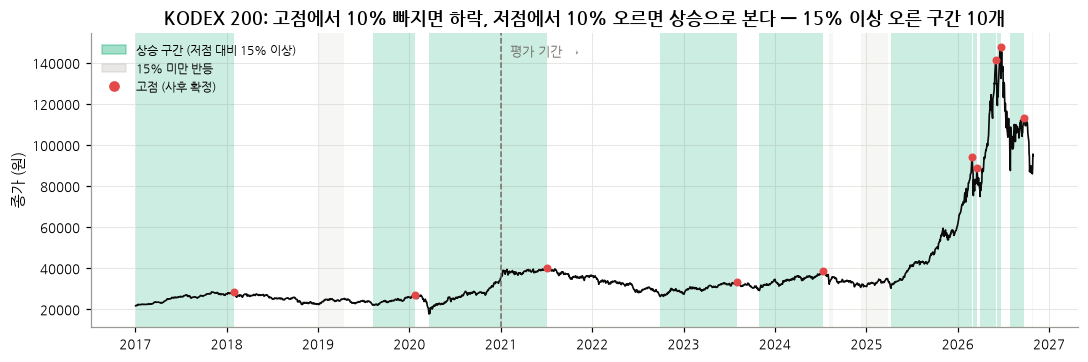

20종 상승 구간 357개 · 평가 기간 중 상승 구간 안에 있던 날 49.3%


In [3]:
# 그림 1-1: 상승 구간의 정의 — 10% 반전 기준 지그재그, 15% 이상 오른 구간만 '상승 구간'
c0 = "069500"  # KODEX 200
cl = X[c0].Close  # 종가
fig, ax = plt.subplots(figsize=(10, 3.4))  # 그림 틀
ax.plot(cl.index, cl.values, color=INK, lw=1.1)  # 종가
for L in ZZ_ALL[c0].itertuples():  # 모든 상승 파동
    big = L.gain >= LEG_MIN  # 15% 이상인가
    ax.axvspan(L.trough, L.peak, color=AQUA if big else GRAY, alpha=.22 if big else .12, lw=0)  # 구간 음영
ax.scatter(LEGS[c0].peak, LEGS[c0].peak_px, s=18, color=RED, zorder=3, label="상승 구간의 고점 (사후 확정)")  # 고점
ax.axvline(T0, color=MUTED, lw=1, ls="--")  # 평가 시작
ax.annotate("평가 기간 →", (T0, cl.max() * .97), xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=MUTED)  # 이름
_h = [mpl.patches.Patch(color=AQUA, alpha=.4), mpl.patches.Patch(color=GRAY, alpha=.3), mpl.lines.Line2D([], [], color=RED, marker="o", ls="")]  # 범례 표식
ax.legend(_h, ["상승 구간 (저점 대비 15% 이상)", "15% 미만 반등", "고점 (사후 확정)"], loc="upper left", fontsize=8)  # 범례
ax.set_ylabel("종가 (원)")  # 축 이름
_n_leg = sum(len(LEGS[c]) for c in ALL)  # 20종 상승 구간 수
_share = np.mean([Y[c].loc[T0:].mean() for c in ALL])  # 상승 구간 안 날의 비율
NUM2["legs"] = dict(n=_n_leg, share=_share, kodex=len(LEGS[c0]))  # 저장
ax.set_title(f"KODEX 200: 고점에서 10% 빠지면 하락, 저점에서 10% 오르면 상승으로 본다 — 15% 이상 오른 구간 {len(LEGS[c0])}개")  # 제목
savefig(fig, "f1_zigzag")  # 저장
print(f"20종 상승 구간 {_n_leg}개 · 평가 기간 중 상승 구간 안에 있던 날 {_share * 100:.1f}%")  # 요약

## 3. 주제 및 판단 기준

#### 가. 주제

- **일봉 자료만으로 정한 매수 · 매도 시점이 장기 보유를 이길 수 있는가**
- 장기 보유는 거래비용이 거의 없고 상승장을 놓치지 않습니다. 매매 규칙이 이기려면 하락장에서 아낀 손실이 상승장에서 놓친 수익보다 커야 합니다

#### 나. 판단 기준

'이긴다'를 세 가지로 나누어 판단합니다

| 기준 | 비교 내용 | 의미 |
|---|---|---|
| ① 총수익 | 같은 기간 누적 수익 | 가장 직관적. 현금으로 쉬는 날이 있는 규칙에 불리합니다 |
| ② 위험 1단위당 수익 | 샤프 비율 · 최대낙폭 | 고객이 견뎌야 하는 하락의 크기를 반영합니다 |
| ③ 같은 위험의 보유와 비교 | 규칙과 일간 변동성이 같도록 '보유 α + 현금 (1−α)'로 섞은 포트폴리오와의 연 수익 차 | 성과가 **덜 들고 있어서**인지 **때를 잘 골라서**인지 구분합니다 |

- 샤프 비율과 ③ 의 비교 대상 · 타이밍 가치는 다음과 같이 정의합니다 ($r^{R}$: 규칙, $r^{H}$: 보유의 일별 수익)

$$\mathrm{SR}=\sqrt{252}\,\frac{\bar{r}}{\sigma_r},\qquad \alpha=\frac{\sigma(r^{R})}{\sigma(r^{H})},\qquad \Delta_{\mathrm{timing}}=252\left(\mathbb{E}\left[\ln(1+r^{R}_t)\right]-\mathbb{E}\left[\ln(1+\alpha\, r^{H}_t)\right]\right)$$

- 현금 이자를 0으로 두면 '보유 α + 현금'의 샤프 비율은 보유와 같으므로, **② 의 샤프 비율 비교와 ③ 은 같은 검정**입니다. ③ 의 결과로 ② 의 통계적 유의성도 함께 판단합니다
- 최대낙폭은 노출을 줄이면 함께 줄어드므로, 같은 변동성 보유+현금의 낙폭과 나란히 봅니다
- 핵심 검정 네 개에는 다중 검정 보정(Holm)을 적용합니다

## 4. 분석 기준

### 4.1 자료와 설계

| 항목 | 설정 |
|---|---|
| 종목 | 국내 상장 ETF 20종 (지수 · 업종 · 테마 · 해외 · 원자재). 레버리지 · 인버스 제외 |
| 자료 | FinanceDataReader 일봉 (시가 · 고가 · 저가 · 종가 · 거래량), 2017-01-02 ~ 2026-10-29. 수정 가격으로 판단 (대표 종목을 외부 수정 주가와 대조) |
| 평가 기간 | **2021-01-04 ~ 2026-10-29 (약 5.8년)**. 2017~20년은 학습 · 지표 계산과 보조 확인(2018~20년 · 2020년 위기 구간)에 사용 |
| 체결 가정 | **종가로 판단하고 다음 날 시가에 체결**. 보유 중에는 매일 종가로 평가 |
| 거래비용 | 편도 0.1% (매수 · 매도 각각). 0% · 0.3% 민감도 확인 |
| 포트폴리오 | 종목마다 같은 금액으로 시작해 따로 운용(리밸런싱 없음). 같은 시장을 추종하는 ETF는 한 **기초지수군**으로 묶어 지수군마다 같은 비중 (17개 지수군) |
| 현금 | 이자 0 (보수적 가정). CD 금리 연 2.69%를 넣어도 5.1의 같은 위험 대비 차이는 +3.2%p로 거의 같습니다 |

- **기초지수군 동일 비중의 이유**: KODEX 200 · TIGER 200 · KODEX 코스피는 사실상 같은 시장(일간 수익 상관 0.99 수준)을, 코스닥150 ETF 두 개도 같은 지수를 추종합니다. 종목마다 같은 비중으로 묶으면 코스피 대형주를 세 번 세게 되므로 지수군 단위로 묶습니다

In [4]:
# 표 3-1: 분석 대상 ETF 20종과 계열 (같은 지수를 추종하는 ETF 는 한 계열)
_rows = []  # 종목별 행
for c in ALL:  # 20종마다
    x = X[c].loc[T0:]  # 평가 기간
    _rows.append(dict(코드=c, 종목=NAME[c], 계열=FAMILY[c], 상장일=X[c].index[0].date(), 평가기간_보유수익=x.Close.iloc[-1] / x.Open.iloc[0] - 1))  # 행
UNI = pd.DataFrame(_rows).sort_values(["계열", "코드"]).reset_index(drop=True)  # 표
UNI.to_csv(RES / "t_universe.csv", index=False, encoding="utf-8-sig")  # 저장
show(UNI.assign(평가기간_보유수익=(UNI.평가기간_보유수익 * 100).round(1)))  # 출력 (%)
NUM2["universe"] = dict(n=len(UNI), fams=UNI.계열.nunique())  # 저장
print(f"{len(UNI)}종 · {UNI.계열.nunique()}개 계열 → 계열마다 같은 비중으로 묶어 평가 (같은 지수를 여러 번 세지 않기 위함)")  # 요약

,코드,종목,기초지수군,상장일,평가기간_보유수익
0,305720,KODEX 2차전지산업,KODEX 2차전지산업,2018-09-12,-14.0
1,261220,KODEX WTI원유선물(H),KODEX WTI원유선물(H),2017-01-02,310.5
2,117700,KODEX 건설,KODEX 건설,2017-01-02,120.9
3,132030,KODEX 골드선물(H),KODEX 골드선물(H),2017-01-02,71.8
4,266360,KODEX 미디어&엔터테인먼트,KODEX 미디어&엔터테인먼트,2017-03-28,-55.2
5,244580,KODEX 바이오,KODEX 바이오,2017-01-02,-56.9
6,091160,KODEX 반도체,KODEX 반도체,2017-01-02,245.9
7,091170,KODEX 은행,KODEX 은행,2017-01-02,204.3
8,091180,KODEX 자동차,KODEX 자동차,2017-01-02,36.4
9,102970,KODEX 증권,KODEX 증권,2017-01-02,164.5


20종 · 17개 계열 → 계열마다 같은 비중으로 묶어 평가 (같은 지수를 여러 번 세지 않기 위함)


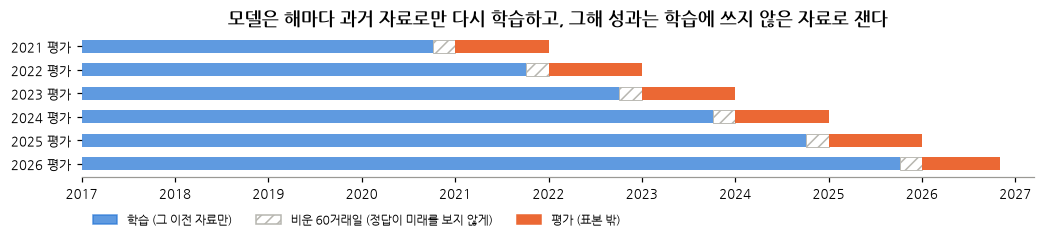

In [5]:
# 그림 3-1: 학습과 평가 일정 — 매년 그 이전 자료로만 학습하고 그해를 평가 (경계 앞 60거래일은 비움)
fig, ax = plt.subplots(figsize=(9.6, 2.6))  # 그림 틀
ax.grid(False)  # 격자선 끔
yrs = list(range(2021, 2027))  # 평가 연도
for i, yr in enumerate(yrs):  # 연도마다
    ax.barh(i, yr - 2017 - .24, left=2017, height=.55, color=BLUE, alpha=.75)  # 학습 구간
    ax.barh(i, .24, left=yr - .24, height=.55, color="white", ec=GRAY, hatch="///", lw=.6)  # 비운 60거래일
    ax.barh(i, 1 if yr < 2026 else 10 / 12, left=yr, height=.55, color=ORANGE)  # 평가 연도
ax.set_yticks(range(len(yrs)), [f"{y} 평가" for y in yrs])  # 눈금
ax.invert_yaxis()  # 위에서 아래로
ax.set_xticks(range(2017, 2028))  # 연도 눈금
ax.set_xlim(2017, 2027.2)  # 범위
_h = [mpl.patches.Patch(color=BLUE, alpha=.75), mpl.patches.Patch(facecolor="white", edgecolor=GRAY, hatch="///"), mpl.patches.Patch(color=ORANGE)]  # 범례 표식
ax.legend(_h, ["학습 (그 이전 자료만)", "비운 60거래일 (정답이 미래를 보지 않게)", "평가 (표본 밖)"], loc="lower left", fontsize=8, ncol=3, bbox_to_anchor=(0, -.42))  # 범례
for s_ in ("left", "top", "right"):  # 테두리 정리
    ax.spines[s_].set_visible(False)  # 숨김
ax.set_title("모델은 해마다 과거 자료로만 다시 학습하고, 그해 성과는 학습에 쓰지 않은 자료로 잰다")  # 제목
savefig(fig, "f3_walkforward")  # 저장

### 4.2 수익 계산 기준 — 다음 날 시가 체결

- 모든 수익은 종가로 판단하고 **다음 날 시가에 체결**한 가격으로 계산하며, 보유 중에는 매일 종가로 평가합니다.
- 흔히 쓰는 종가 기준 계산 $r_t = w_{t-1}(C_t/C_{t-1}-1)$ 은 매수일 하루의 수익을 빼고 매도 뒤 하루를 더 세어 실제 손익과 어긋납니다. 이 차이만으로 12개 전략 조합 중 11개의 순위가 바뀌었으므로(수익 −2.7 ~ −32.0%p), 종가 기준으로 계산한 기존 수치는 모두 이 기준으로 대체했습니다.

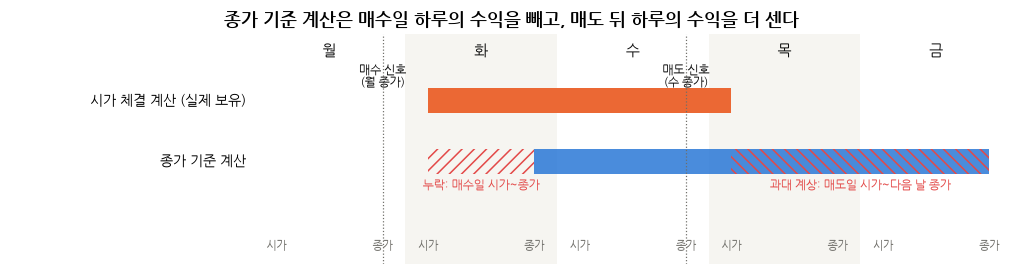

In [6]:
# 그림 3-2: 종가 기준 계산과 시가 체결 계산이 손익을 세는 기간
fig, ax = plt.subplots(figsize=(9.4, 2.6))  # 그림 틀
ax.grid(False)  # 격자선 끔
days = ["월", "화", "수", "목", "금"]  # 요일
for d_, nm in enumerate(days):  # 요일마다
    ax.axvspan(d_, d_ + 1, color="#f6f5f1" if d_ % 2 else "white", lw=0)  # 하루 칸
    ax.text(d_ + .5, 2.75, nm, ha="center", fontsize=10, color=INK)  # 요일 이름
    ax.text(d_ + .15, -.45, "시가", ha="center", fontsize=7.5, color=MUTED)  # 시가 표시
    ax.text(d_ + .85, -.45, "종가", ha="center", fontsize=7.5, color=MUTED)  # 종가 표시
O_, C_ = lambda d: d + .15, lambda d: d + .85  # 하루 안 시가 · 종가 위치
ax.barh(2, C_(3) - O_(1) - (C_(3) - O_(3)), left=O_(1), height=.42, color=ORANGE)  # 시가 체결 계산: 화 시가 → 목 시가
ax.barh(1, C_(4) - C_(1), left=C_(1), height=.42, color=BLUE, alpha=.85)  # 종가 기준 계산: 화 종가 → 금 종가
ax.barh(1, C_(1) - O_(1), left=O_(1), height=.42, fill=False, hatch="///", ec=RED, lw=0)  # 빠진 구간
ax.barh(1, C_(4) - O_(3), left=O_(3), height=.42, fill=False, hatch="\\\\\\", ec=RED, lw=0)  # 더해진 구간
ax.text(-.05, 2, "시가 체결 계산 (실제 보유)", ha="right", va="center", fontsize=9)  # 줄 이름
ax.text(-.05, 1, "종가 기준 계산", ha="right", va="center", fontsize=9)  # 줄 이름
ax.annotate("매수 신호\n(월 종가)", (C_(0), 2.25), ha="center", fontsize=8, color=INK)  # 신호
ax.annotate("매도 신호\n(수 종가)", (C_(2), 2.25), ha="center", fontsize=8, color=INK)  # 신호
ax.annotate("누락: 매수일 시가~종가", (O_(1) + .35, .55), ha="center", fontsize=8, color=RED)  # 설명
ax.annotate("과대 계상: 매도일 시가~다음 날 종가", (O_(3) + .85, .55), ha="center", fontsize=8, color=RED)  # 설명
for x_ in (C_(0), C_(2)):  # 신호 시점
    ax.axvline(x_, color=MUTED, lw=.8, ls=":")  # 점선
ax.set_xlim(-1.6, 5)  # 범위
ax.set_ylim(-.7, 3.1)  # 범위
ax.set_xticks([])  # 눈금 없음
ax.set_yticks([])  # 눈금 없음
for sp_ in ax.spines.values():  # 테두리
    sp_.set_visible(False)  # 숨김
ax.set_title("종가 기준 계산은 매수일 하루의 수익을 빼고, 매도 뒤 하루의 수익을 더 센다")  # 결론 제목
savefig(fig, "x1_timeline")  # 저장

,종목군,전략 조합,종가기준,시가체결,종가기준_MDD,시가체결_MDD,격차,종가기준_순위,시가체결_순위
1,5종,신고가돌파·전량청산,0.749,0.570,-0.231,-0.220,-0.179,3.0,1.0
3,5종,신고가돌파·부분청산·비중복원,0.635,0.487,-0.214,-0.209,-0.149,5.0,3.0
5,5종,GBM(종목별)·전량청산·신고가재진입,0.715,0.454,-0.231,-0.296,-0.261,4.0,5.0
7,5종,GBM(종목별)·부분청산·신고가재진입·비중복원,0.600,0.373,-0.214,-0.286,-0.226,6.0,6.0
9,5종,GBM(통합)·전량청산·신고가재진입,0.865,0.545,-0.196,-0.236,-0.320,1.0,2.0
11,5종,GBM(통합)·부분청산·신고가재진입·비중복원,0.763,0.472,-0.181,-0.225,-0.292,2.0,4.0
13,20종,신고가돌파·전량청산,0.843,0.623,-0.141,-0.123,-0.220,1.0,2.0
15,20종,신고가돌파·부분청산·비중복원,0.668,0.506,-0.104,-0.113,-0.162,4.0,5.0
17,20종,GBM(종목별)·전량청산·신고가재진입,0.727,0.662,-0.163,-0.152,-0.065,3.0,1.0
19,20종,GBM(종목별)·부분청산·신고가재진입·비중복원,0.558,0.532,-0.154,-0.143,-0.027,6.0,4.0


✔ 거래별 손익의 곱 = 시가 체결 누적 수익 (최대 오차 6.7e-15)


,종목군,전략 조합,거래 수,매수일_시가대비종가,매도일_시가대비다음날종가,종가기준이_더한몫
0,5종,신고가돌파·전량청산,170,0.0020,0.0036,0.0016
1,5종,GBM(통합)·전량청산·신고가재진입,232,-0.0005,0.0030,0.0035
2,20종,신고가돌파·전량청산,673,0.0004,0.0033,0.0029
3,20종,GBM(통합)·전량청산·신고가재진입,979,0.0001,0.0006,0.0005


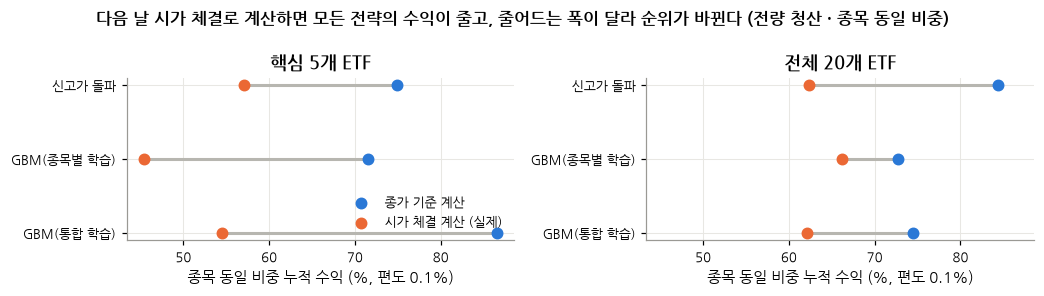

In [7]:
# 12판을 두 계산 방식으로: 종가 기준 계산 vs 다음 날 시가 체결 계산
rows = []  # 결과 행
closure = 0.0  # 닫힘 오차 최댓값
for u, (codes, bd) in BOARDS.items():  # 묶음마다
    for nm, b in bd.items():  # 판마다
        lg = {c: sim(c, b) for c in codes}  # 매매
        for bp in (0, 10):  # 비용마다
            cv = sleeve([equity(X[c], lg[c][0], T0, None, bp) for c in codes])  # 종가 기준 계산
            fl = sleeve([equity_fill(X[c], lg[c][1], T0, None, bp) for c in codes])  # 시가 체결 계산
            rows.append(dict(묶음=u, 판=nm, bp=bp, 종가기준=cv.iloc[-1] - 1, 시가체결=fl.iloc[-1] - 1, 종가기준_MDD=mdd(cv), 시가체결_MDD=mdd(fl)))  # 행 추가
            for c in codes:  # 종목마다 닫힘 확인
                tr = parse(c, lg[c][1], bp)  # 거래표
                prod = np.prod([1 + (t["ret"] if not t["open_end"] else t["mark"]) for t in tr]) if tr else 1.0  # 거래 수익의 곱
                closure = max(closure, abs(prod - equity_fill(X[c], lg[c][1], T0, None, bp).iloc[-1]))  # 오차 갱신
X1 = pd.DataFrame(rows)  # 표로
X1["차이"] = X1.시가체결 - X1.종가기준  # 체결 − 곡선
X1["종가기준_순위"] = X1.groupby(["묶음", "bp"]).종가기준.rank(ascending=False)  # 곡선 기준 순위
X1["시가체결_순위"] = X1.groupby(["묶음", "bp"]).시가체결.rank(ascending=False)  # 체결 기준 순위
X1.to_csv(RES / "x1_accounting.csv", index=False, encoding="utf-8-sig")  # 저장
show(X1[X1.bp == 10].drop(columns="bp").round(3))  # 10bp 출력
check(closure < 1e-9, f"거래별 손익의 곱 = 시가 체결 누적 수익 (최대 오차 {closure:.1e})")  # 사전 판정 1
_x = X1[X1.bp == 10]  # 10bp 만
NUM2["X1"] = dict(rows={f"{r.묶음}|{r.판}": dict(curve=r.종가기준, fill=r.시가체결, cm=r.종가기준_MDD, fm=r.시가체결_MDD, rc=r.종가기준_순위, rf=r.시가체결_순위) for r in _x.itertuples()}, closure=closure, gap=[float(_x.차이.min()), float(_x.차이.max()), float(_x.차이.mean())], rank_changed=int((_x.종가기준_순위 != _x.시가체결_순위).sum()), rank_top_changed=[u for u in UNIV if _x[(_x.묶음 == u) & (_x.종가기준_순위 == 1)].판.iloc[0] != _x[(_x.묶음 == u) & (_x.시가체결_순위 == 1)].판.iloc[0]])  # PDF 용 저장
# 차이의 원인: 곡선은 체결일 시가→종가를 빼고, 청산 체결일 시가→다음 날 종가를 더합니다
rows = []  # 분해 행
for u, (codes, bd) in BOARDS.items():  # 묶음마다
    for nm in ["베이스라인·규칙1", "GBM합동·규칙1·HI20"]:  # 대표 두 판
        ein, eout = [], []  # 빠진 수익 · 더해진 수익
        for c in codes:  # 종목마다
            x = X[c]  # 지표 표
            O, Cl = x.Open.values, x.Close.values  # 시가 · 종가
            for t in parse(c, sim(c, bd[nm])[1]):  # 거래마다
                if t["open_end"] or t["exit_i"] + 1 >= len(x):  # 끝난 거래만
                    continue  # 건너뜀
                ein.append(Cl[t["entry_i"]] / O[t["entry_i"]] - 1)  # 체결일 시가 → 종가
                eout.append(Cl[t["exit_i"] + 1] / O[t["exit_i"]] - 1)  # 청산 시가 → 다음 날 종가
        rows.append(dict(묶음=u, 판=nm, 거래=len(ein), 매수일_시가대비종가=np.mean(ein), 매도일_시가대비다음날종가=np.mean(eout), 종가기준이_더한몫=np.mean(eout) - np.mean(ein)))  # 행 추가
X1D = pd.DataFrame(rows)  # 표로
show(X1D.round(4))  # 출력
NUM2["X1_decomp"] = {f"{r.묶음}|{r.판}": dict(n=r.거래, ein=r.매수일_시가대비종가, eout=r.매도일_시가대비다음날종가, add=r.종가기준이_더한몫) for r in X1D.itertuples()}  # 저장
_p = _x[_x.판.str.contains("규칙1")].copy()  # 규칙 1 판
fig, axs = plt.subplots(1, 2, figsize=(9.6, 2.7), sharex=True)  # 두 칸
for ax, u in zip(axs, UNIV):  # 묶음마다
    g = _p[_p.묶음 == u].reset_index(drop=True)  # 그 묶음
    ys = np.arange(len(g))  # 위치
    ax.hlines(ys, g.시가체결 * 100, g.종가기준 * 100, color=GRAY, lw=2)  # 연결선
    ax.scatter(g.종가기준 * 100, ys, s=46, color=BLUE, label="종가 기준 계산", zorder=3)  # 곡선 점
    ax.scatter(g.시가체결 * 100, ys, s=46, color=ORANGE, label="시가 체결 계산 (실제)", zorder=3)  # 체결 점
    ax.set_yticks(ys, g.판.str.split("·").str[0].map({"베이스라인": "신고가 돌파", "GBM단독": "GBM(종목별 학습)", "GBM합동": "GBM(통합 학습)"}))  # 눈금
    ax.invert_yaxis()  # 위에서 아래로
    ax.set_xlabel("종목 동일 비중 누적 수익 (%, 편도 0.1%)")  # 축 이름
    ax.set_title({"5종": "핵심 5개 ETF", "20종": "전체 20개 ETF"}[u])  # 제목
axs[0].legend(loc="lower right")
fig.suptitle("다음 날 시가 체결로 계산하면 모든 전략의 수익이 줄고, 줄어드는 폭이 달라 순위가 바뀐다 (전량 청산 · 종목 동일 비중)", fontweight="bold", fontsize=11)  # 범례
savefig(fig, "x1_accounting")  # 저장
dump()  # 수치 저장

- 위 표 · 그림은 같은 매매 기록을 두 방식으로 계산한 결과입니다(종목 동일 비중 · 편도 0.1%). 거래별 손익을 곱한 값과 시가 체결 누적 수익이 일치하는지도 함께 확인했습니다.

### 4.3 기준 매매 규칙 — 20일 신고가 돌파 전략

| 단계 | 규칙 | 판단 · 체결 |
|---|---|---|
| 매수 | 종가 > 직전 20거래일 최고 종가 (20일 신고가 돌파) | 종가 판단 → 다음 날 시가 |
| 매도 | 종가 < 20일 이동평균, 또는 종가 < 보유 중 최고가 − 3 × ATR(14일) | 종가 판단 → 다음 날 시가 |
| 재진입 | 매도 뒤 다시 20일 신고가를 돌파하면 매수 | 종가 판단 → 다음 날 시가 |

- 수식으로 쓰면 다음과 같습니다 (C: 종가, H*: 보유 중 최고가, MA20: 20일 이동평균, ATR14: 14일 평균 실제 변동폭)

$$\mathrm{buy}_t:\ C_t>\max_{1\leq i\leq 20}C_{t-i},\qquad \mathrm{sell}_t:\ C_t<\mathrm{MA}_{20,t}\ \ \mathrm{or}\ \ C_t<H^{*}_t-3\,\mathrm{ATR}_{14,t}$$

- 추세 추종의 고전적 돌파 규칙(Donchian 채널)과 ATR(평균 일중 변동폭) 추적 손절을 결합한 형태입니다
- 학습이 필요 없고 파라미터가 적어, 이 보고서의 **비교 기준(벤치마크)** 으로 씁니다
- 6장의 대안은 이 규칙의 매수 신호 · 매도 규칙 · 재진입 조건을 하나씩 바꾸어 검토합니다

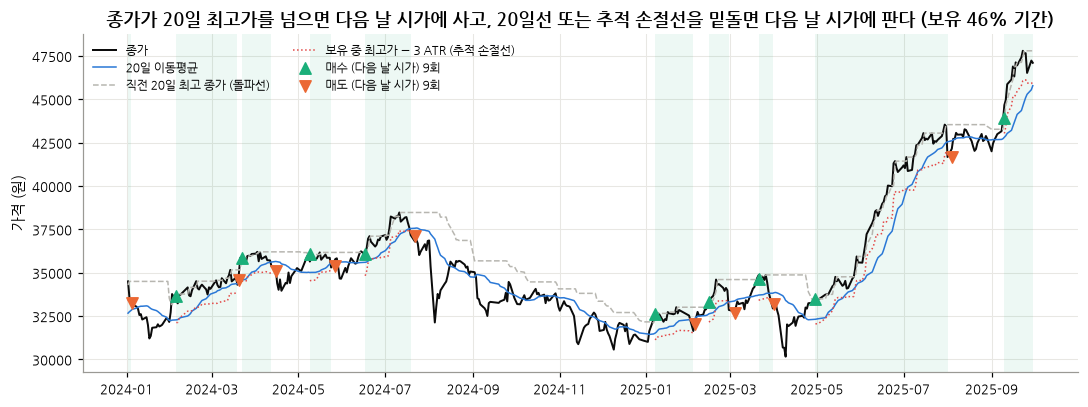

In [8]:
# 그림 4-1: 신고가 돌파 규칙의 실제 매매 — KODEX 200, 2024-01 ~ 2025-09
c0, a0, b0 = "069500", "2024-01-01", "2025-09-30"  # 종목 · 기간
x = X[c0]  # 지표 표
lg = sim(c0, BLB)[1]  # 실제 사건표 (평가 기간 전체)
seg = x.loc[a0:b0]  # 그림 구간
stop = pd.Series(np.nan, index=x.index)  # 추적 손절선 (보유 중 최고가 − 3 ATR)
_e = lg.reset_index(drop=True)  # 사건
for j in _e.index[_e.event.isin(["진입", "재매수"])]:  # 매수마다
    s_ = x.index.get_loc(_e.date[j])  # 매수일
    nx = _e[(_e.index > j) & (_e.event == "전량 청산")]  # 다음 매도
    e_ = x.index.get_loc(nx.date.iloc[0]) if len(nx) else len(x) - 1  # 매도일
    hi_ = x.High.iloc[s_:e_].cummax()  # 보유 중 최고가
    stop.iloc[s_:e_] = (hi_ - P["atr_k"] * x.ATR.iloc[s_:e_]).values  # 손절선
fig, ax = plt.subplots(figsize=(10, 3.8))  # 그림 틀
ax.plot(seg.index, seg.Close, color=INK, lw=1.3, label="종가")  # 종가
ax.plot(seg.index, seg.MA, color=BLUE, lw=1, label="20일 이동평균")  # 20일선
ax.plot(seg.index, seg.HI, color=GRAY, lw=1, ls="--", label="직전 20일 최고 종가 (돌파선)")  # 돌파선
ax.plot(seg.index, stop.loc[a0:b0], color=RED, lw=1, ls=":", label="보유 중 최고가 − 3 ATR (추적 손절선)")  # 손절선
_in = _e[_e.event.isin(["진입", "재매수"]) & _e.date.between(pd.Timestamp(a0), pd.Timestamp(b0))]  # 매수
_out = _e[(_e.event == "전량 청산") & _e.date.between(pd.Timestamp(a0), pd.Timestamp(b0))]  # 매도
ax.scatter(_in.date, _in.px, marker="^", s=55, color=AQUA, zorder=4, label=f"매수 (다음 날 시가) {len(_in)}회")  # 매수 표시
ax.scatter(_out.date, _out.px, marker="v", s=55, color=ORANGE, zorder=4, label=f"매도 (다음 날 시가) {len(_out)}회")  # 매도 표시
_held = pd.Series(0.0, index=x.index)  # 보유 표시
for t in parse(c0, lg):  # 거래마다
    _held.iloc[t["entry_i"]: t["exit_i"]] = 1  # 보유일
ax.fill_between(seg.index, seg.Close.min() * .97, seg.Close.max() * 1.02, where=_held.loc[a0:b0].values > 0, color=AQUA, alpha=.08, lw=0, step="post")  # 보유 기간
ax.set_ylim(seg.Close.min() * .97, seg.Close.max() * 1.02)  # 범위
ax.set_ylabel("가격 (원)")  # 축 이름
ax.legend(loc="upper left", fontsize=7.6, ncol=2)  # 범례
ax.set_title(f"종가가 20일 최고가를 넘으면 다음 날 시가에 사고, 20일선 또는 추적 손절선을 밑돌면 다음 날 시가에 판다 (보유 {_held.loc[a0:b0].mean() * 100:.0f}% 기간)")  # 제목
savefig(fig, "f4_rule")  # 저장

## 5. 현황 — 현행 규칙의 성과

같은 시작일 · 같은 체결 가정 · 같은 비용으로 아래 전략을 비교합니다.

- **매수 후 보유**: 평가 첫날 시가에 사서 끝까지 보유
- **200일선 추세 추종**: 종가가 200일 이동평균 위면 보유, 아래면 현금
- **20일 신고가 돌파 규칙** (4.3)
- **GBM 모델 + 같은 매도 규칙** (6.1)
- **같은 변동성의 보유+현금**: 규칙과 일간 변동성이 같도록 '보유 α + 현금 (1−α)'로 섞은 포트폴리오 (판단 기준 ③ 의 비교 대상)
- **절반 혼합**: 자금 절반은 보유, 절반은 규칙

In [9]:
# 일반 전략 곡선 (같은 시작일 · 시가 체결 · 10bp)
def hold_curve_fill(c, start=T0, end=None, bp=10):  # 첫날 시가 매수 후 보유
    x = X[c].loc[start:end]  # 구간
    return pd.Series(x.Close.values * (1 - bp / 1e4) / x.Open.values[0], index=x.index)  # 평가액
def ma200_lg(c, start=T0, end=None):  # 200일선 타이밍 사건표
    x = X[c]  # 지표 표
    sma = x.Close.rolling(200).mean()  # 200일선
    on = (x.Close > sma).values  # 종가 판단
    idx = x.index  # 날짜
    pos, log = False, []  # 보유 여부 · 사건
    for i in range(len(idx) - 1):  # 날짜순으로
        if idx[i + 1] < start or (end and idx[i + 1] > pd.Timestamp(end)):  # 체결일이 구간 밖이면
            continue  # 건너뜀
        if on[i] and not pos:  # 위로 돌파
            log.append((idx[i + 1], "진입", x.Open.values[i + 1]))  # 다음 날 시가 매수
            pos = True  # 보유
        elif not on[i] and pos:  # 아래로 이탈
            log.append((idx[i + 1], "전량 청산", x.Open.values[i + 1]))  # 다음 날 시가 매도
            pos = False  # 현금
    return pd.DataFrame(log, columns=["date", "event", "px"])  # 사건표
def rebal_curve(codes, freq, start=T0, end=None, bp=10):  # 1/N 기간 말 리밸런싱
    r = pd.DataFrame({c: X[c].Close.loc[start:end].pct_change() for c in codes}).fillna(0)  # 일별 수익
    last = set(pd.Series(r.index, index=r.index).groupby(r.index.to_period(freq)).max())  # 기간 말
    w = np.full(len(codes), 1 / len(codes))  # 비중
    val, out = 1 - bp / 1e4, []  # 진입 비용 차감 · 곡선
    for d, row in zip(r.index, r.values):  # 날짜순으로
        g = (w * row).sum()  # 오늘 수익
        val *= 1 + g  # 평가액
        w = w * (1 + row) / (1 + g)  # 비중 변화
        if d in last:  # 기간 말이면
            val *= 1 - np.abs(w - 1 / len(codes)).sum() * bp / 1e4  # 맞춘 만큼 비용
            w = np.full(len(codes), 1 / len(codes))  # 비중 복원
        out.append(val)  # 기록
    return pd.Series(out, index=r.index)  # 곡선
HOLD = {c: hold_curve_fill(c) for c in ALL}  # 보유 곡선
BLC = curves_of(bl_lg())  # 베이스라인 곡선
MA2 = curves_of({c: ma200_lg(c) for c in ALL})  # 200일선 곡선
GJC = curves_of({c: sim(c, (MODS["20종"]["합동"], "규칙1", REBUY, False))[1] for c in ALL})  # GBM 합동 곡선
rows = []  # 결과 표
PRIM = "20종 계열 균등"  # 대표 묶음
MAIN = {}  # 대표 묶음 곡선
for nm, src in [("보유", HOLD), ("200일선", MA2), ("베이스라인", BLC), ("GBM 합동", GJC)]:  # 전략마다
    for st, cv in sets_of(src).items():  # 묶음마다
        rows.append(dict(전략=nm, 묶음=st, **stats(cv)))  # 행 추가
        if st == PRIM:  # 대표 묶음이면
            MAIN[nm] = cv  # 보관
for fr, fn in [("M", "월 리밸런싱"), ("Q", "분기 리밸런싱")]:  # 기간마다
    cv = rebal_curve(ALL, fr)  # 20종 1/N
    rows.append(dict(전략=fn, 묶음="20종 1/N", **stats(cv)))  # 행 추가
_h, _b = rets(MAIN["보유"]), rets(MAIN["베이스라인"])  # 일별 수익 (첫날 포함)
ALPHA = _b.std() / _h.std()  # 실현 변동성 비
_cal = pd.concat([_b, _h * ALPHA], axis=1)  # 베이스라인 · 같은 변동성 보유+현금 일별 수익
MAIN["보유+현금 같은 변동성 보유+현금"] = (1 + _cal.iloc[:, 1]).cumprod()  # 같은 변동성 보유+현금 곡선
rows.append(dict(전략="보유+현금 같은 변동성 보유+현금", 묶음=PRIM, **stats(MAIN["보유+현금 같은 변동성 보유+현금"])))  # 행 추가
for w_ in [.5]:  # 절반 보유 + 절반 규칙
    cv = {c: w_ * HOLD[c] + (1 - w_) * BLC[c] for c in ALL}  # 슬리브 간 재조정 없음
    MIX = fam_sleeve(cv)  # 대표 묶음
    rows.append(dict(전략="절반 혼합", 묶음=PRIM, **stats(MIX)))  # 행 추가
T1 = pd.DataFrame(rows)  # 표로
T1.to_csv(RES / "c1_strategies.csv", index=False, encoding="utf-8-sig")  # 저장
show(T1.round(3))  # 출력
ann = lambda a: 252 * (np.log1p(a[:, 0]).mean() - np.log1p(a[:, 1]).mean())  # 연 로그 차
_stat = ann(_cal.values)  # 실제 값
_bs = qboot(_cal, ann)  # 재표집
_x26 = _cal[_cal.index.year < 2026]  # 2026 제외
NUM3["C1"] = dict(alpha=ALPHA, d=_stat, lo=np.percentile(_bs, 2.5), hi=np.percentile(_bs, 97.5), p=pv2(_bs), se=_bs.std(), mde=3.34 * _bs.std(), d_ex26=ann(_x26.values), rows=rows)  # 저장 (Holm 4건 · 검정력 .8)
print(f"신고가 돌파 − 같은 변동성 보유+현금: 연율 로그 수익 차 {_stat * 100:+.2f}%p [{NUM3['C1']['lo'] * 100:+.2f}, {NUM3['C1']['hi'] * 100:+.2f}] · p {NUM3['C1']['p']:.3f} · 보유 비중 α {ALPHA:.3f}")  # 출력
_m = pd.DataFrame({k: v.resample("ME").last().pct_change().dropna() for k, v in MAIN.items()})  # 월 수익
up, dn = _m["보유"] > 0, _m["보유"] < 0  # 상승 · 하락 달
# 비용 · 현금 이자 민감도 (판정 없음)
_sens = []  # 민감도 행
for bp_ in [0, 10, 30]:  # 비용마다
    hs_ = fam_sleeve({c: hold_curve_fill(c, bp=bp_) for c in ALL})  # 보유
    bs_ = fam_sleeve(curves_of(bl_lg(), bp=bp_))  # 베이스라인
    rh_, rb_ = rets(hs_), rets(bs_)  # 일별 수익
    a_ = rb_.std() / rh_.std()  # 변동성 비
    _sens.append(dict(bp=bp_, 보유=hs_.iloc[-1] - 1, 규칙=bs_.iloc[-1] - 1, d=252 * (np.log1p(rb_).mean() - np.log1p(rh_ * a_).mean())))  # 행 추가
_rf = .0269 / 252  # 현금 이자 대리 (CD 연 2.69%, briefs/03)
_pb = pd.concat({c: 0 * rets(BLC[c]) for c in ALL}, axis=1)  # 빈 틀
for c in ALL:  # 종목마다
    _pp = pd.Series(0.0, index=X[c].index)  # 보유 표시
    for t in parse(c, sim(c, BLB)[1]):  # 거래마다
        _pp.iloc[t["entry_i"]: t["exit_i"]] = 1.0  # 보유일
    _pb[c] = rets(BLC[c]) + (1 - _pp.reindex(_pb.index).fillna(0)) * _rf  # 현금일에 이자 더함
_bi = fam_sleeve({c: (1 + _pb[c]).cumprod() for c in ALL})  # 이자 포함 베이스라인
_ci = (1 + _h * ALPHA + (1 - ALPHA) * _rf).cumprod()  # 이자 포함 같은 변동성 보유+현금
NUM3["C1_sens"] = dict(cost=_sens, rf_bl=_bi.iloc[-1] - 1, rf_ca=_ci.iloc[-1] - 1, rf_d=252 * (np.log1p(rets(_bi)).mean() - np.log1p(rets(_ci)).mean()))  # 저장
_xh, _xb = MAIN["보유"][MAIN["보유"].index.year < 2026], MAIN["베이스라인"][MAIN["베이스라인"].index.year < 2026]  # 2026 제외 곡선
NUM3["C1_ex26"] = dict(hold=stats(_xh), bl=stats(_xb))  # 저장
_fg = {"코스피 대형주 지수군": [c for c in ALL if FAMILY[c] == "코스피대형주지수군"], "코스닥150 지수군": [c for c in ALL if FAMILY[c] == "코스닥150지수군"]}  # 큰 계열
_fg["그 외 15개 지수군"] = [c for c in ALL if FAMILY[c] not in ("코스피대형주지수군", "코스닥150지수군")]  # 나머지
NUM3["C1_family"] = [dict(묶음=k, hold=stats(sleeve([HOLD[c] for c in v])), bl=stats(sleeve([BLC[c] for c in v])), gbm=stats(sleeve([GJC[c] for c in v]))) for k, v in _fg.items()]  # 계열별
NUM3["C1_capture"] = {k: dict(up=_m.loc[up, k].mean() / _m.loc[up, "보유"].mean(), dn=_m.loc[dn, k].mean() / _m.loc[dn, "보유"].mean()) for k in ["베이스라인", "200일선", "GBM 합동"]}  # 시장 참여율
_pos = {}  # 평균 노출
for nm, lgs in [("베이스라인", bl_lg()), ("GBM 합동", {c: sim(c, (MODS["20종"]["합동"], "규칙1", REBUY, False))[1] for c in ALL}), ("200일선", {c: ma200_lg(c) for c in ALL})]:  # 전략마다
    ex = []  # 종목별 노출
    for c in ALL:  # 종목마다
        p_ = pd.Series(0.0, index=X[c].index)  # 보유 표시
        for t in parse(c, lgs[c]):  # 거래마다
            p_.iloc[t["entry_i"]: t["exit_i"] + 1] = 1.0  # 보유일
        ex.append(p_.loc[T0:].mean())  # 평균
    _pos[nm] = np.mean(ex)  # 저장
NUM3["C1_exposure"] = _pos  # 저장
# 2018–20 부호 확인 (같은 개봉에서 한 번)
_st, _en = pd.Timestamp("2018-01-02"), "2020-12-30"  # 기간
_cod = [c for c in ALL if X[c].index[0] <= _st]  # 그때 있던 종목
_b1 = fam_sleeve(curves_of(bl_lg(_st, _en, codes=_cod), _st, _en))  # 베이스라인
_h1 = fam_sleeve({c: hold_curve_fill(c, _st, _en) for c in _cod})  # 보유
_a1 = _b1.pct_change().std() / _h1.pct_change().std()  # 그 기간 변동성 비
NUM3["C1_old"] = dict(n=len(_cod), d=252 * (np.log1p(_b1.pct_change().dropna()).mean() - np.log1p(_h1.pct_change().dropna() * _a1).mean()), bl=stats(_b1), hold=stats(_h1), alpha=_a1)  # 저장
# 5대 위기 창
EVENTS = {"2020.3 코로나": "2020-03-19", "2022 금리인상": "2022-06-16", "2024.8 블랙먼데이": "2024-08-05", "2024.12 비상계엄": "2024-12-04", "2025.4 관세쇼크": "2025-04-07"}  # 5대 위기 구간 (기준일 −30 ~ +60거래일)
rows = []  # 창별 행
_ix = X["069500"].index  # 달력
for ev, dt in EVENTS.items():  # 창마다
    k = _ix.get_indexer([pd.Timestamp(dt)], method="bfill")[0]  # 기준일 위치
    a, b_ = _ix[max(k - 30, 0)], _ix[min(k + 60, len(_ix) - 1)]  # D−30 ~ D+60
    cs = [c for c in ALL if X[c].index[0] <= a]  # 그때 있던 종목
    h_ = fam_sleeve({c: hold_curve_fill(c, a, b_) for c in cs})  # 보유
    b1_ = fam_sleeve(curves_of(bl_lg(a, b_, codes=cs), a, b_))  # 베이스라인
    rows.append(dict(창=ev, 보유=h_.iloc[-1] - 1, 보유MDD=mdd(h_), 베이스라인=b1_.iloc[-1] - 1, 베이스MDD=mdd(b1_)))  # 행 추가
TW = pd.DataFrame(rows)  # 표로
TW.to_csv(RES / "c1_windows.csv", index=False, encoding="utf-8-sig")  # 저장
show(TW.round(3))  # 출력
NUM3["C1_win"] = rows  # 저장
# 항등식 관문: 보유 대비 격차 = 현금 구간 놓친 수익 + 비용
rows, err = [], 0.0  # 결과 · 오차
for c in ALL:  # 종목마다
    x = X[c].loc[T0:]  # 구간
    tr = parse(c, sim(c, BLB)[1], 10)  # 거래
    O0, Cend = x.Open.values[0], x.Close.values[-1]  # 첫 시가 · 마지막 종가
    ix = X[c].index  # 날짜
    Op = X[c].Open.values  # 시가
    prev, up_, dn_, nb, ns = O0, 0.0, 0.0, 0, 0  # 직전 매도가 · 놓친 상승 · 피한 하락 · 매수 · 매도 수
    for t in tr:  # 거래마다
        gap = np.log(Op[t["entry_i"]] / prev)  # 현금 구간 로그 수익
        up_, dn_ = up_ + max(gap, 0), dn_ + min(gap, 0)  # 상승 · 하락으로 분리
        nb += 1  # 매수 수
        if t["open_end"]:  # 끝까지 보유면
            prev = None  # 현금 구간 없음
        else:  # 닫힌 거래면
            ns += 1  # 매도 수
            prev = Op[t["exit_i"]]  # 매도가
    if prev is not None:  # 마지막이 현금이면
        gap = np.log(Cend / prev)  # 끝까지 놓친 구간
        up_, dn_ = up_ + max(gap, 0), dn_ + min(gap, 0)  # 분리
    cost = (nb + ns - 1) * -np.log(1 - K)  # 보유의 진입 비용 1회를 뺀 추가 비용
    lhs = np.log(HOLD[c].iloc[-1]) - np.log(BLC[c].iloc[-1])  # 왼쪽: 보유 대비 격차
    err = max(err, abs(lhs - (up_ + dn_ + cost)))  # 오차 갱신
    rows.append(dict(코드=c, 종목=NAME[c], 격차=lhs, 놓친상승=up_, 피한하락=dn_, 비용=cost, 거래=nb))  # 행 추가
TI = pd.DataFrame(rows)  # 표로
TI.to_csv(RES / "c1_identity.csv", index=False, encoding="utf-8-sig")  # 저장
show(TI.round(3))  # 출력
check(err < 1e-9, f"항등식 관문: 격차 = 놓친 상승 + 피한 하락 + 비용 (최대 오차 {err:.1e})")  # 관문
_fa = TI.assign(f=[FAMILY[c] for c in TI.코드]).groupby("f")[["격차", "놓친상승", "피한하락", "비용"]].mean().mean()  # 계열 균등 평균
NUM3["C1_id"] = dict(err=err, gap=_fa.격차, up=_fa.놓친상승, dn=_fa.피한하락, cost=_fa.비용, pos=int((TI.놓친상승 + TI.피한하락 > 0).sum()), pos_cost=int((TI.격차 > 0).sum()), n=len(TI), port=float(np.log(MAIN["보유"].iloc[-1] / MAIN["베이스라인"].iloc[-1])), lo=float(TI.격차.min()), hi=float(TI.격차.max()), med=float(TI.격차.median()), kospi=[float(TI.격차[TI.코드 == c].iloc[0]) for c in ["069500", "102110", "226490"]])  # 저장
dump()  # 수치 저장

,전략,종목군,누적수익,최대낙폭,샤프,연변동성,최악5% 21일수익
0,매수 후 보유,20종 지수군 동일 비중,0.902,-0.313,0.624,0.221,-0.121
1,매수 후 보유,20종 종목 동일 비중,0.915,-0.313,0.616,0.229,-0.124
2,매수 후 보유,5종 지수군 동일 비중,0.695,-0.398,0.460,0.301,-0.157
3,매수 후 보유,5종 종목 동일 비중,0.869,-0.399,0.519,0.299,-0.157
4,200일선,20종 지수군 동일 비중,0.701,-0.276,0.644,0.168,-0.093
5,200일선,20종 종목 동일 비중,0.716,-0.273,0.632,0.175,-0.096
6,200일선,5종 지수군 동일 비중,0.533,-0.348,0.438,0.237,-0.127
7,200일선,5종 종목 동일 비중,0.697,-0.360,0.507,0.242,-0.130
8,신고가돌파,20종 지수군 동일 비중,0.619,-0.116,0.941,0.095,-0.036
9,신고가돌파,20종 종목 동일 비중,0.623,-0.123,0.920,0.098,-0.039


신고가 돌파 − 같은 변동성 보유+현금: 연율 로그 수익 차 +3.02%p [-1.68, +8.31] · p 0.238 · 보유 비중 α 0.430


,위기 구간,매수 후 보유,보유 최대낙폭,신고가돌파,신고가돌파 최대낙폭
0,2020.3 코로나,0.018,-0.358,0.117,-0.070
1,2022 금리인상,-0.097,-0.150,-0.017,-0.032
2,2024.8 블랙먼데이,-0.032,-0.135,-0.050,-0.064
3,2024.12 비상계엄,0.001,-0.094,-0.035,-0.043
4,2025.4 관세쇼크,0.166,-0.137,0.156,-0.032


,코드,종목,보유대비 격차(로그),현금시 놓친 상승,현금시 피한 하락,추가 비용,거래 수
0,069500,KODEX 200,0.250,0.951,-0.766,0.065,33
1,102110,TIGER 200,0.278,0.968,-0.755,0.065,33
2,226490,KODEX 코스피,0.144,0.799,-0.714,0.059,30
3,229200,KODEX 코스닥150,-0.080,0.977,-1.131,0.075,38
4,232080,TIGER 코스닥150,0.003,1.035,-1.103,0.071,36
5,091160,KODEX 반도체,0.814,1.907,-1.166,0.073,37
6,091180,KODEX 자동차,0.430,1.336,-0.978,0.071,36
7,091170,KODEX 은행,0.936,1.366,-0.515,0.085,43
8,102970,KODEX 증권,0.266,1.286,-1.085,0.065,33
9,117700,KODEX 건설,0.176,1.123,-1.010,0.063,32


✔ 항등식 관문: 격차 = 놓친 상승 + 피한 하락 + 비용 (최대 오차 1.1e-15)


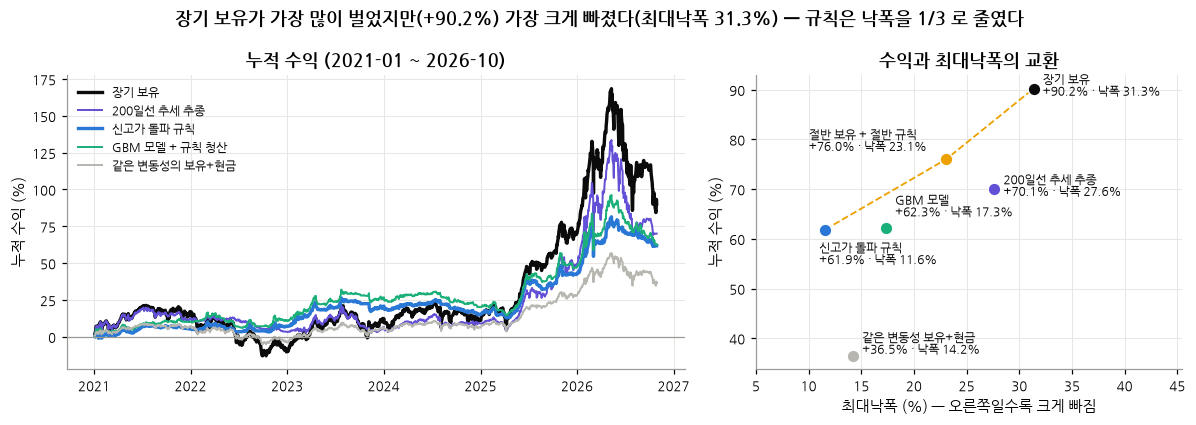

In [10]:
# 그림 5-1: 장기 보유와 비교 — 누적 수익과 '수익 × 최대낙폭'
_lab = {"보유": "장기 보유", "200일선": "200일선 추세 추종", "베이스라인": "신고가 돌파 규칙", "GBM 합동": "GBM 모델 + 규칙 청산", "보유+현금 같은 변동성 보유+현금": "같은 변동성의 보유+현금"}  # 표시 이름
_col = {"보유": INK, "200일선": VIOLET, "베이스라인": BLUE, "GBM 합동": AQUA, "보유+현금 같은 변동성 보유+현금": GRAY}  # 전략 색
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(width_ratios=[1.45, 1]))  # 두 칸
for k, cv in MAIN.items():  # 전략마다
    axs[0].plot(cv.index, (cv - 1) * 100, color=_col.get(k, MUTED), lw=2.2 if k in ("보유", "베이스라인") else 1.3, label=_lab.get(k, k))  # 누적 수익
axs[0].axhline(0, color="#9a9994", lw=.8)  # 0 선
axs[0].set_ylabel("누적 수익 (%)")  # 축 이름
axs[0].legend(loc="upper left", fontsize=8)  # 범례
axs[0].set_title("누적 수익 (2021-01 ~ 2026-10)")  # 제목
_T = T1[T1.묶음 == PRIM].set_index("전략")  # 대표 묶음 표
_pts = [("보유", "장기 보유"), ("절반 혼합", "절반 보유 + 절반 규칙"), ("베이스라인", "신고가 돌파 규칙"), ("200일선", "200일선 추세 추종"), ("GBM 합동", "GBM 모델"), ("보유+현금 같은 변동성 보유+현금", "같은 변동성 보유+현금")]  # 점
for k, nm in _pts:  # 전략마다
    r_, m_ = _T.loc[k, "ret"] * 100, -_T.loc[k, "mdd"] * 100  # 수익 · 낙폭
    axs[1].scatter(m_, r_, s=70, color=_col.get(k, YELLOW), zorder=3, edgecolor="white", lw=1)  # 점
    _off = {"GBM 합동": (6, 8), "베이스라인": (-4, -22), "보유+현금 같은 변동성 보유+현금": (6, 2), "절반 혼합": (-90, 6)}.get(k, (6, -4))  # 겹치지 않게
    axs[1].annotate(f"{nm}\n{r_:+.1f}% · 낙폭 {m_:.1f}%", (m_, r_), xytext=_off, textcoords="offset points", fontsize=7.6)  # 이름
_xs = [-_T.loc[k, "mdd"] * 100 for k in ("베이스라인", "절반 혼합", "보유")]  # 노출 선택 선
_ys = [_T.loc[k, "ret"] * 100 for k in ("베이스라인", "절반 혼합", "보유")]  # 노출 선택 선
axs[1].plot(_xs, _ys, color=YELLOW, lw=1.2, ls="--", zorder=2)  # 규칙 ↔ 보유 사이 선택지
axs[1].set_xlabel("최대낙폭 (%) — 오른쪽일수록 크게 빠짐")  # 축 이름
axs[1].set_ylabel("누적 수익 (%)")  # 축 이름
axs[1].set_xlim(5, max(_xs) * 1.45)  # 범위
axs[1].set_title("수익과 최대낙폭의 교환")  # 제목
fig.suptitle(f"장기 보유가 가장 많이 벌었지만({_T.loc['보유', 'ret'] * 100:+.1f}%) 가장 크게 빠졌다(최대낙폭 {-_T.loc['보유', 'mdd'] * 100:.1f}%) — 규칙은 낙폭을 1/3 로 줄였다", fontweight="bold", fontsize=11.5)  # 결론 제목
savefig(fig, "f5_strategies")  # 저장

### 5.1 결과

| 전략 (20종 · 지수군 동일 비중) | 누적 수익 | 최대낙폭 | 샤프 비율 |
|---|---|---|---|
| 매수 후 보유 | +90.2% | 31.3% | 0.62 |
| 절반 보유 + 절반 규칙 | +76.0% | 23.1% | 0.74 |
| 200일선 추세 추종 | +70.1% | 27.6% | 0.64 |
| GBM 모델(통합 학습) + 같은 매도 규칙 | +62.3% | 17.3% | 0.85 |
| **20일 신고가 돌파 규칙** | **+61.9%** | **11.6%** | **0.94** |
| 같은 변동성의 보유+현금 (보유 43% + 현금 57%) | +36.5% | 14.2% | 0.62 |

*20종 · 지수군 동일 비중 · 다음 날 시가 체결 · 편도 0.1% · 현금 이자 0 · 2021-01-04 ~ 2026-10-29. GBM은 매수 신호만 다르고 매도 규칙은 같습니다. 종목별 학습(+66.2%, 종목 동일 비중)이 더 높으나 20종을 한 모델로 운용하는 통합 학습을 대표로 씀.*

#### 판단 기준별 결과

- **① 총수익: 보유 우세.** 규칙은 보유보다 28.3%p 낮습니다
- **② 위험 1단위당 수익: 점추정으로 규칙 우위, 통계적으로는 미확인.** 샤프 비율 0.94 (보유 0.62), 최대낙폭 11.6% (보유 31.3%, 같은 변동성 보유+현금 14.2%). 같은 변동성 보유+현금 대비로 보면 낙폭의 타이밍 몫은 2.6%p 이고 나머지는 노출 축소의 효과입니다. 5대 위기 구간(2020 코로나[평가 기간 밖] · 2022 금리 인상 · 2024.8 급락 · 2024.12 계엄 · 2025.4 관세) 모두에서 규칙의 낙폭이 작았으나, 구간 수익은 2승 3패입니다
- **③ 같은 위험의 보유와 비교: 통계적으로 유의하지 않습니다.** 연율 로그 수익 차 +3.0%p 이나 95% 신뢰구간 [−1.7, +8.3] 이 0을 포함함(Holm 보정 p 0.71). 거래비용 0.3% 에서는 +0.7%p로 축소되고, 현금 이자(CD 2.69%)를 넣으면 +3.2%p입니다

#### 문제 상황

- 현행 규칙의 성과는 **수익 일부를 내주고 낙폭을 줄인 것**이며, 그 대부분은 평균 38%의 기간만 주식을 보유한(노출 축소) 데서 나옵니다
- 이 표본(5.8년)으로 가려낼 수 있는 최소 차이는 연 7~9%p 수준으로, ③ 의 우위가 '없다'가 아니라 '이 기간으로는 가릴 수 없다'는 상태입니다

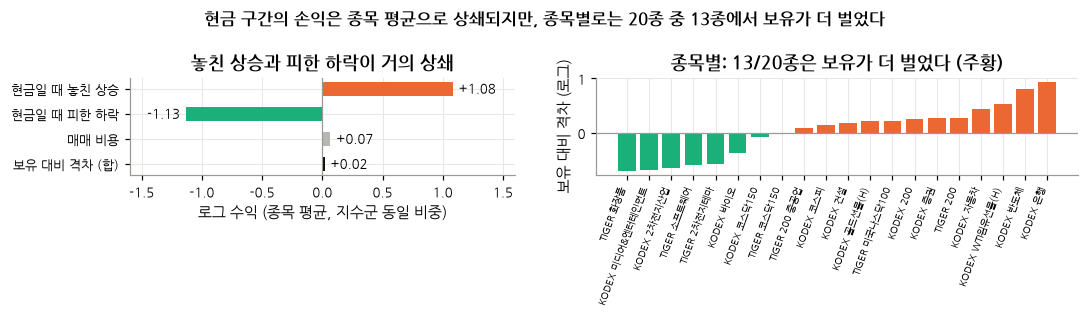

In [11]:
# 그림 5-2: 현금으로 있던 동안 무엇을 놓치고 무엇을 피했나 (종목 평균, 로그 수익)
_i = NUM3["C1_id"]  # 분해 값
fig, axs = plt.subplots(1, 2, figsize=(10, 2.9), gridspec_kw=dict(width_ratios=[1, 1.25]))  # 두 칸
_nm = ["현금일 때 놓친 상승", "현금일 때 피한 하락", "매매 비용", "보유 대비 격차 (합)"]  # 항목
_v = [_i["up"], _i["dn"], _i["cost"], _i["gap"]]  # 값
axs[0].barh(_nm, _v, color=[ORANGE, AQUA, GRAY, INK], height=.55)  # 막대
for y_, v_ in enumerate(_v):  # 값 표시
    axs[0].annotate(f"{v_:+.2f}", (v_, y_), xytext=(4 if v_ >= 0 else -4, 0), textcoords="offset points", ha="left" if v_ >= 0 else "right", va="center", fontsize=8.5)  # 값
axs[0].axvline(0, color="#9a9994", lw=.8)  # 0 선
axs[0].invert_yaxis()  # 위에서 아래로
axs[0].set_xlim(-1.6, 1.6)  # 범위
axs[0].set_xlabel("로그 수익 (종목 평균, 지수군 동일 비중)")  # 축 이름
axs[0].set_title("놓친 상승과 피한 하락이 거의 상쇄")  # 제목
_ti = TI.sort_values("격차")  # 종목별
axs[1].bar(range(len(_ti)), _ti.격차, color=[ORANGE if v > 0 else AQUA for v in _ti.격차])  # 종목별 격차
axs[1].axhline(0, color="#9a9994", lw=.8)  # 0 선
axs[1].set_xticks(range(len(_ti)), _ti.종목, rotation=70, ha="right", fontsize=6.5)  # 눈금
axs[1].set_ylabel("보유 대비 격차 (로그)")  # 축 이름
axs[1].set_title(f"종목별: {int((_ti.격차 > 0).sum())}/{len(_ti)}종은 보유가 더 벌었다 (주황)")  # 제목
fig.suptitle("현금 구간의 손익은 종목 평균으로 상쇄되지만, 종목별로는 20종 중 13종에서 보유가 더 벌었다", fontweight="bold", fontsize=11)  # 결론 제목
savefig(fig, "f5_identity")  # 저장

### 5.2 현금 보유 구간의 손익 분해

- 규칙이 현금으로 있던 구간의 손익을 종목별로 정확히 분해하면(누적 로그 수익, 종목 평균) **놓친 상승(+1.08)과 피한 하락(−1.13)이 거의 같습니다**. 종목 평균으로는 현금 구간이 손실도 이득도 아니었습니다
- 그러나 종목별로는 20종 중 13종에서 보유가 더 벌었고, 격차는 은행 · 반도체 · 원유 · 자동차처럼 크게 오른 일부 종목에 몰려 있습니다. 포트폴리오 수익은 이런 종목의 몫이 커서 보유에 뒤졌습니다

## 6. 검토한 방안과 확인 결과

현행 규칙의 매수 신호 · 고점 근처 매수 · 매도 규칙 · 재진입 조건을 하나씩 바꾸어 검토합니다. 각 방안은 **확인한 것 → 근거** 순서로 적습니다.

### 6.1 상승 국면을 판별해 매수 시점을 정하는 방안

> **확인한 것** 기계학습 모델(GBM)은 사후 정의한 상승 국면을 잘 가리지만(AUC 0.816), 그 판별로 수익 나는 날을 고르지는 못했습니다(AUC 0.515). 국면 판단과 매수 시점은 별개의 문제입니다. → **질의 1 · 2: 상승 국면 판단 기준과 매수 시점 기준**

#### 가. 검토 내용

- 기술적 지표 13개(5 · 20 · 60일 수익률, 이동평균 이격도, RSI, MACD, 변동성 등)로 그래디언트 부스팅 모델(GBM)을 학습해 '현재가 상승 구간인가'를 예측합니다
- 매매 규칙: 점수가 0.6 이상으로 올라선 날(종가 판단) 다음 날 시가에 매수. 매도는 4.3과 같고, 매도 뒤 점수가 0.4 이하로 내려가기 전까지는 20일 신고가 돌파 시 재진입. 점수가 0.4 이하가 되면 신호 해제(이중 임계값). 매년 그 이전 자료로만 재학습하고 학습과 평가 사이에 60거래일을 비웁니다
- 상승 구간을 잘 맞히는 모델이라면 그 모델이 고른 날의 수익도 높아야 하므로, 정답을 하나 더 두어 채점합니다
    - **상승 구간 라벨**: 그날이 상승 구간(2장) 안인가
    - **거래 성공 라벨**: 다음 날 시가에 매수해 20거래일 안에 '진입가 + ATR% 2배'에 먼저 닿으면 성공, '− 2배'에 먼저 닿으면 실패, 둘 다 아니면 기한 종가의 비용 차감 후 손익으로 판정 (삼중 장벽법)
- 모델이 실제로 산 날을 **같은 종목 · 연도 · 건수 · 미보유일 · 20일선 위아래 구성을 맞춰 무작위로 뽑은 날**(1,000회)과 비교합니다

In [12]:
# 거래 기회 라벨 계산 (벡터 연산)

COST2 = .002  # 왕복 비용 20bp

def tb_label(O, H, L, C, atr_pct, up=2.0, dn=2.0, T=20, cost=COST2):  # 트리플 베리어 라벨

    n = len(C)  # 길이
    ep = np.r_[O[1:], np.nan]  # 진입가 = 다음 날 시가
    ok = (np.arange(n) + T <= n - 1) & ~np.isnan(atr_pct) & ~np.isnan(ep)  # 시한이 자료 안이고 ATR 이 있는 날
    pad = lambda a: np.r_[a, np.full(T + 1, np.nan)]  # 끝을 결측으로 채움

    wH, wL = swv_(pad(H), T)[1:n + 1], swv_(pad(L), T)[1:n + 1]  # i+1 일부터 T 일 고가 · 저가
    
    hit_u = wH >= (ep * (1 + up * atr_pct))[:, None]  # 익절선 닿음
    hit_d = wL <= (ep * (1 - dn * atr_pct))[:, None]  # 손절선 닿음

    fu = np.where(hit_u.any(1), hit_u.argmax(1), 10**6)  # 첫 익절일
    fd = np.where(hit_d.any(1), hit_d.argmax(1), 10**6)  # 첫 손절일

    c_t = np.full(n, np.nan)  # 시한 종가
    c_t[ok] = C[np.arange(n)[ok] + T]  # 값 채움

    res = np.where(fu < fd, 1.0, np.where(fd <= fu, np.where(fd < 10**6, 0.0, ((c_t / ep - 1 - cost) > 0).astype(float)), np.nan))  # 같은 날 둘 다면 손절 · 없으면 시한 수익 부호
    res[~ok] = np.nan  # 창 밖은 결측

    return res  # 라벨

from numpy.lib.stride_tricks import sliding_window_view as swv_  # 창 계산 도구

def h_label(O, H=10, cost=COST2):  # 고정 보유 라벨
    n = len(O)  # 길이
    r = np.full(n, np.nan)  # 결과
    r[:n - H - 1] = O[H + 1:] / O[1:n - H] - 1 - cost  # i+1 시가 → i+1+H 시가 수익
    out = (r > 0).astype(float)  # 양수면 1
    out[np.isnan(r)] = np.nan  # 결측 유지
    return out  # 라벨
    
_rows = []  # 종목별 표
for c in ALL:  # 20종마다
    x = X[c]  # 지표 표
    d = pd.DataFrame(index=x.index)  # 빈 표
    atr = (x.ATR / x.Close).where(x.MA.notna()).values  # 신호일 ATR% (지표가 생긴 뒤만)
    a = (x.Open.values, x.High.values, x.Low.values, x.Close.values, atr)  # 입력 묶음
    d["Y_TB"] = tb_label(*a)  # 주 정의
    d["Y_TB1"] = tb_label(*a, up=1, dn=1)  # 민감도: 1배
    d["Y_TB3"] = tb_label(*a, up=3, dn=3)  # 민감도: 3배
    d["Y_TB_T10"] = tb_label(*a, T=10)  # 민감도: 시한 10일
    d["Y_TB_T40"] = tb_label(*a, T=40)  # 민감도: 시한 40일
    d["Y_TB31"] = tb_label(*a, up=3, dn=1)  # 민감도: 비대칭
    d["Y_H10"] = h_label(x.Open.values)  # 고정 보유
    d["code"] = c  # 코드
    d["i"] = np.arange(len(x))  # 위치
    pk = coords(c)  # 좌표
    d["Y"], d["k"], d["dd"], d["to_peak"], d["kind"], d["provisional"] = pk.Y.values, pk.k.values, pk.dd.values, pk.to_peak.values, pk.kind.values, pk.provisional.values  # 좌표 붙이기
    pp = np.full(len(x), np.nan)  # 자기 급등 구간의 고점 종가
    for L in LEGS[c].itertuples():  # 구간마다
        pp[(x.index > L.trough) & (x.index <= L.peak)] = L.peak_px  # 고점 종가
    d["peak_close"] = pp  # 열 추가
    d["Y_PEAK"] = np.where(d.Y == 1, (pp > np.r_[x.Open.values[1:], np.nan]).astype(float), np.nan)  # 사후 고점 > 진입가
    d["above"] = (x.Close > x.MA).values  # 20일선 위
    d["atr_pct"] = atr  # ATR%
    _rows.append(d.reset_index().rename(columns={"Date": "date", "index": "date"}))  # 날짜를 열로

_x = X["069500"]  # 라벨 손계산 대상

_O, _H, _L, _Cl = _x.Open.values, _x.High.values, _x.Low.values, _x.Close.values  # 가격 배열

_at = (_x.ATR / _x.Close).where(_x.MA.notna()).values  # ATR%

_vec = tb_label(_O, _H, _L, _Cl, _at)  # 벡터 계산 결과
_bad = 0  # 불일치 수

for _i in range(0, len(_x) - 21, 7):  # 7일 간격으로 표본을 골라
    if np.isnan(_at[_i]):  # ATR 이 없으면
        continue  # 건너뜀
    _ep = _O[_i + 1]  # 진입가
    _res = None  # 손계산 결과
    for _j in range(_i + 1, _i + 21):  # 시한 20일 동안 하루씩
        if _L[_j] <= _ep * (1 - 2 * _at[_i]):  # 손절선 먼저 확인 (같은 날이면 손절)
            _res = 0.0  # 손절
            break  # 끝
        if _H[_j] >= _ep * (1 + 2 * _at[_i]):  # 익절선 확인
            _res = 1.0  # 익절
            break  # 끝
    if _res is None:  # 장벽에 안 닿았으면
        _res = float(_Cl[_i + 20] / _ep - 1 - COST2 > 0)  # 시한 종가 수익 부호
    _bad += int(_res != _vec[_i])  # 다르면 셈
check(_bad == 0, f"거래 성공 라벨 점검: 벡터 계산 = 하루씩 따라간 계산 (KODEX 200 표본, 불일치 {_bad})")  # 라벨 코드 점검

LB = pd.concat(_rows, ignore_index=True)  # 합치기

_f = forced_panel("규칙1")[["code", "i", "ret"]]  # 규칙 1 강제 거래 수익

LB = LB.merge(_f, on=["code", "i"], how="left")  # 붙이기

LB["Y_RULE"] = np.where(LB.ret.notna(), ((LB.ret - COST2) > 0).astype(float), np.nan)  # 규칙 라벨
LB["period"] = np.where(LB.date < SPLIT, "2021 전", "2021 후")  # 기간
LABELS = ["Y_TB", "Y_H10", "Y_RULE", "Y_TB1", "Y_TB3", "Y_TB_T10", "Y_TB_T40", "Y_TB31"]  # 라벨 목록

rows = []  # 결과 행
for lab in LABELS:  # 라벨마다
    for pr in ["2021 전", "2021 후"]:  # 기간마다
        q = LB[(LB.period == pr) & LB[lab].notna() & (~LB.provisional)]  # 유효 행
        p1, p0 = q[q.Y == 1][lab].mean(), q[q.Y == 0][lab].mean()  # 두 조건부 확률
        rows.append(dict(라벨=lab, 기간=pr, n=len(q), 기저율=q[lab].mean(), P_Y1=p1, P_Y0=p0, 차이=p1 - p0))  # 행 추가
X3A = pd.DataFrame(rows)  # 표로
X3A.to_csv(RES / "x3_cond.csv", index=False, encoding="utf-8-sig")  # 저장


show(X3A.round(3))  # 출력

✔ 거래 성공 라벨 점검: 벡터 계산 = 하루씩 따라간 계산 (KODEX 200 표본, 불일치 0)


,라벨,기간,건수,전체 성공률,상승구간 안 성공률,상승구간 밖 성공률,격차
0,거래성공,2021 전,18352,0.552,0.727,0.329,0.398
1,거래성공,2021 후,28120,0.507,0.709,0.307,0.402
2,10일보유,2021 전,18732,0.549,0.705,0.352,0.353
3,10일보유,2021 후,28300,0.508,0.684,0.335,0.349
4,청산규칙수익,2021 전,18352,0.415,0.514,0.290,0.224
5,청산규칙수익,2021 후,28467,0.389,0.488,0.292,0.196
6,거래성공1,2021 전,18352,0.524,0.633,0.385,0.248
7,거래성공1,2021 후,28120,0.506,0.643,0.369,0.274
8,거래성공3,2021 전,18352,0.561,0.749,0.321,0.428
9,거래성공3,2021 후,28120,0.513,0.717,0.310,0.407


In [13]:
_q = LB[(LB.period == "2021 후") & LB.Y_TB.notna() & (~LB.provisional)]  # 2021 후 기간
_n = len(_q)  # 전체 행 수

NUM2["X3_cells"] = dict(y1t1=((_q.Y == 1) & (_q.Y_TB == 1)).sum() / _n, y1t0=((_q.Y == 1) & (_q.Y_TB == 0)).sum() / _n, y0t1=((_q.Y == 0) & (_q.Y_TB == 1)).sum() / _n, y0t0=((_q.Y == 0) & (_q.Y_TB == 0)).sum() / _n, n=_n)  # 네 칸 비율
NUM2["X3_peak"] = dict(share=float(LB[(LB.period == "2021 후") & LB.Y_PEAK.notna()].Y_PEAK.mean()))  # 사후 고점 라벨의 양성 비율
NUM2["X3_cond"] = {f"{r.라벨}|{r.기간}": dict(n=r.n, base=r.기저율, p1=r.P_Y1, p0=r.P_Y0, d=r.차이) for r in X3A.itertuples()}  # 저장

# 위치별 거래 기회 비율 (2021 후)
BANDS = {"고점 21거래일 이상 전": lambda d: (d.Y == 1) & (d.to_peak > 20), "고점 4~20거래일 전": lambda d: (d.Y == 1) & d.to_peak.between(4, 20), "고점 직전 (0~3거래일 전)": lambda d: (d.Y == 1) & (d.to_peak <= 3), "고점 직후 (10거래일 · −3% 이내)": lambda d: (d.k <= 10) & (d.dd > -.03) & (d.Y == 0), "고점 대비 −5% 이내": lambda d: (d.dd >= -.05) & (d.Y == 0), "그 밖의 고점 이후": lambda d: d.k.notna() & (d.dd < -.05) & (d.Y == 0)}  # 위치 띠

rows = []  # 결과 행
for nm, fn in BANDS.items():  # 띠마다
    for pr in ["2021 전", "2021 후"]:  # 기간마다
        s = LB[(LB.period == pr) & (~LB.provisional) & fn(LB)]  # 띠 행
        rows.append(dict(위치=nm, 기간=pr, n=int(s.Y_TB.notna().sum()), Y_TB=s.Y_TB.mean(), Y_H10=s.Y_H10.mean(), Y_RULE=s.Y_RULE.mean()))  # 행 추가

X3B = pd.DataFrame(rows)  # 표로
X3B.to_csv(RES / "x3_bands.csv", index=False, encoding="utf-8-sig")  # 저장
show(X3B.round(3))  # 출력
NUM2["X3_bands"] = {f"{r.위치}|{r.기간}": dict(n=r.n, tb=r.Y_TB, h10=r.Y_H10, rule=r.Y_RULE) for r in X3B.itertuples()}  # 저장
dump()  # 수치 저장

,위치,기간,건수,거래성공,10일보유 성공,청산규칙 수익
0,고점 21거래일 이상 전,2021 전,8185,0.735,0.722,0.540
1,고점 21거래일 이상 전,2021 후,9474,0.735,0.701,0.514
2,고점 4~20거래일 전,2021 전,1712,0.804,0.765,0.495
3,고점 4~20거래일 전,2021 후,3551,0.783,0.788,0.531
4,고점 직전 (0~3거래일 전),2021 전,393,0.234,0.074,0.048
5,고점 직전 (0~3거래일 전),2021 후,991,0.197,0.153,0.090
6,고점 직후 (10거래일 · −3% 이내),2021 전,355,0.039,0.037,0.045
7,고점 직후 (10거래일 · −3% 이내),2021 후,642,0.047,0.091,0.073
8,고점 대비 −5% 이내,2021 전,1027,0.106,0.124,0.094
9,고점 대비 −5% 이내,2021 후,2313,0.133,0.155,0.129


,종목군,모델,지표,실제,무작위 평균,하한,상한,표준편차,백분위,건수,무작위 대비,무작위 대비 초과,최소검출효과
0,5종,신고가돌파,거래성공,0.5119,0.5276,0.4641,0.5952,0.0347,0.294,168,범위 내,-0.0157,0.0970
1,5종,신고가돌파,10일보유,0.6250,0.5214,0.4524,0.5833,0.0344,0.997,168,상회,0.1036,0.0962
2,5종,신고가돌파,청산규칙수익,0.4286,0.3018,0.2440,0.3631,0.0316,1.000,168,상회,0.1267,0.0883
3,5종,신고가돌파,평균수익,0.0163,0.0074,-0.0021,0.0175,0.0050,0.960,168,범위 내,0.0089,0.0139
4,5종,GBM(종목별),거래성공,0.4355,0.5283,0.4731,0.5914,0.0316,0.000,186,하회,-0.0928,0.0885
5,5종,GBM(종목별),10일보유,0.4946,0.5177,0.4516,0.5806,0.0327,0.211,186,범위 내,-0.0230,0.0916
6,5종,GBM(종목별),청산규칙수익,0.3763,0.3407,0.2742,0.4032,0.0330,0.839,186,범위 내,0.0356,0.0924
7,5종,GBM(종목별),평균수익,-0.0018,0.0053,-0.0023,0.0137,0.0041,0.033,186,범위 내,-0.0071,0.0115
8,5종,GBM(통합),거래성공,0.5792,0.5484,0.4863,0.6175,0.0339,0.800,183,범위 내,0.0308,0.0950
9,5종,GBM(통합),10일보유,0.6284,0.5677,0.5082,0.6339,0.0317,0.968,183,범위 내,0.0607,0.0888


,종목군,모델,정답,AUC,F1,정밀도,재현율,상시매수 F1
0,5종,신고가돌파,Y,NaN,0.403,0.824,0.267,0.650
1,5종,신고가돌파,거래성공,NaN,0.285,0.594,0.188,0.672
2,5종,GBM(종목별),Y,0.807,0.752,0.745,0.760,0.650
3,5종,GBM(종목별),거래성공,0.543,0.532,0.535,0.529,0.672
4,5종,GBM(통합),Y,0.800,0.707,0.762,0.659,0.650
5,5종,GBM(통합),거래성공,0.520,0.490,0.535,0.451,0.672
6,20종,신고가돌파,Y,NaN,0.398,0.875,0.258,0.652
7,20종,신고가돌파,거래성공,NaN,0.253,0.564,0.163,0.672
8,20종,GBM(종목별),Y,0.770,0.706,0.684,0.730,0.652
9,20종,GBM(종목별),거래성공,0.530,0.539,0.528,0.550,0.672


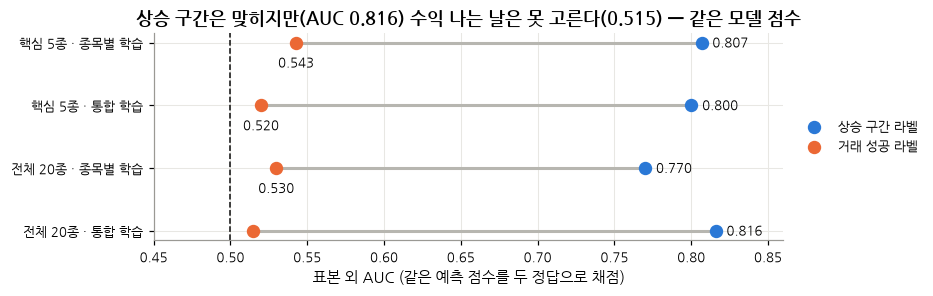

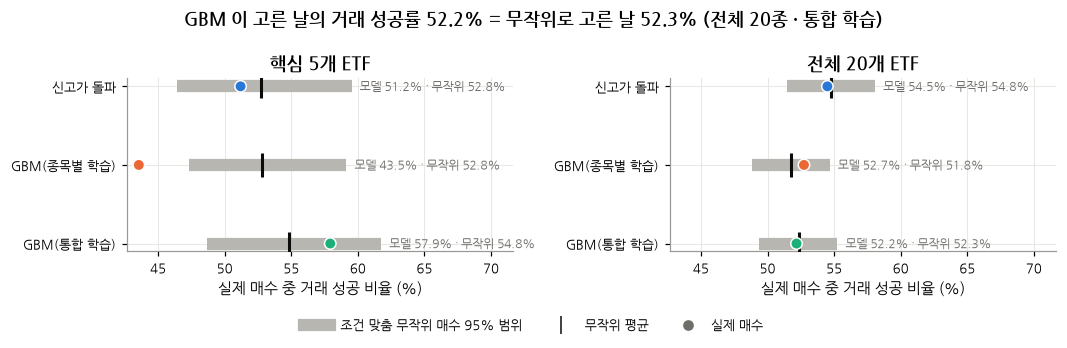

In [14]:
# 조건 맞춤 무작위 매수와 비교: 거래 성공 비율 · 건당 수익 · 두 라벨의 AUC
PN = LB[(LB.date >= T0) & (~LB.provisional) & LB.Y_TB.notna() & LB.ret.notna()].reset_index(drop=True)  # 2021+ 유효 패널
PN["yr"] = PN.date.dt.year  # 연도
POS = pd.Series(np.arange(len(PN)), index=pd.MultiIndex.from_arrays([PN.code, PN.i]))  # 위치 사전

def null_n2s(codes, m, rb, pred, sets, panel=None, pos=None, B=1000, seed=0, ev=("진입",)):  # 실제 진입과 무작위 진입 비교
    panel = PN if panel is None else panel  # 패널 기본값
    pos = POS if pos is None else pos  # 위치 사전 기본값
    acts, blocked = [], {}  # 실제 진입 위치 · 보유 표시
    for c in codes:  # 종목마다
        lv, lg = sim(c, (m, "규칙1", rb, False))  # 매매
        bl = np.zeros(len(X[c]), bool)  # 보유 표시
        for t in parse(c, lg):  # 거래마다
            bl[t["entry_i"]: t["exit_i"] + (1 if t["open_end"] else 0)] = True  # 체결일 ~ 청산 체결 전날
        blocked[c] = bl  # 저장
        for i in fired(c, lg[lg.event.isin(ev)]):  # 체결 진입마다
            if (c, i) in pos.index:  # 패널에 있으면
                acts.append(pos[(c, i)])  # 위치 저장

    acts = np.array(acts)  # 배열로
    code, yr, above, ii = panel.code.values, panel.yr.values, panel.above.values, panel.i.values  # 빠른 접근
    elig = pred & np.array([(c in blocked) and not blocked[c][i] for c, i in zip(code, ii)])  # 후보일
    rng = np.random.default_rng(seed)  # 난수
    vals = {k: np.zeros(B) for k in sets}  # 귀무 합계
    cell = pd.DataFrame(dict(a=acts, c=code[acts], y=yr[acts], s=above[acts]))  # 실제 진입의 칸
    for (c, y_, st), g in cell.groupby(["c", "y", "s"]):  # 칸마다
        pool = np.where((code == c) & (yr == y_) & elig & (above == st))[0]  # 같은 칸 후보
        k = len(g)  # 건수
        if len(pool) < k:  # 모자라면
            pool = np.where((code == c) & (yr == y_) & elig)[0]  # 같은 종목 · 연도 미보유일 전체
        idx = np.argsort(rng.random((B, len(pool))), axis=1)[:, :k]  # 비복원 추출
        for nm, v in sets.items():  # 집합마다
            vals[nm] += v[pool[idx]].sum(axis=1)  # 합계 누적
    n = len(acts)  # 실제 건수
    return {nm: dict(real=v[acts].sum() / n, null=(vals[nm] / n).mean(), lo=np.percentile(vals[nm] / n, 2.5), hi=np.percentile(vals[nm] / n, 97.5), sd=(vals[nm] / n).std(), pct=((vals[nm] / n) < v[acts].sum() / n).mean(), n=n) for nm, v in sets.items()}  # 요약

def pred_of(u, mn):  # 모델이 예측을 낸 날 표시
    if mn == "베이스라인":  # 베이스라인은
        return np.ones(len(PN), bool)  # 전부
    pr = pd.concat([gbm_prob([c], [c]) for c in UNIV[u]]) if mn == "GBM단독" else gbm_prob(UNIV[u], UNIV[u])  # 예측 표
    ok = pd.MultiIndex.from_arrays([pr.code, pr.index])[pr.p.notna()]  # 예측 있는 행
    return pd.MultiIndex.from_arrays([PN.code, PN.date]).isin(ok)  # 패널 위치로
SETS = dict(Y_TB=PN.Y_TB.values, Y_H10=PN.Y_H10.fillna(0).values, Y_RULE=PN.Y_RULE.values, 평균수익=PN.ret.values)  # 비교 집합

rows = []  # 결과 행
for u in UNIV:  # 묶음마다
    for mn in ["베이스라인", "GBM단독", "GBM합동"]:  # 모델마다
        rb = None if mn == "베이스라인" else REBUY  # 재매수 조건
        for k, d in null_n2s(UNIV[u], MODELS[u][mn], rb, pred_of(u, mn), SETS).items():  # 집합마다
            rows.append(dict(묶음=u, 모델=mn, 집합=k, **d))  # 행 추가

X3N = pd.DataFrame(rows)  # 표로

X3N["판정"] = np.where(X3N.real > X3N.hi, "위", np.where(X3N.real < X3N.lo, "아래", "안"))  # 범위 판정
X3N["초과"] = X3N.real - X3N.null  # 귀무 대비 초과
X3N["MDE"] = 2.8 * X3N.sd  # 최소 검출 효과 근사 (유의 5% · 검정력 80%, 진입이 고정된 라벨이라 쓸 수 있음)
X3N.to_csv(RES / "x3_null.csv", index=False, encoding="utf-8-sig")  # 저장

show(X3N.round(4))  # 출력
NUM2["X3_null"] = {f"{r.묶음}|{r.모델}|{r.집합}": dict(real=r.real, null=r.null, lo=r.lo, hi=r.hi, n=r.n, v=r.판정, ex=r.초과, mde=r.MDE, pct=r.pct) for r in X3N.itertuples()}  # 저장

# 같은 모델을 두 정답으로 채점: F1 과 AUC
def state_score(codes, m, col):  # 상태 vs 라벨의 F1 과 매일 켬 기준선
    tp, fp, fn, ons = 0, 0, 0, []  # 칸 합
    base = []  # 종목별 양성률
    for c in codes:  # 종목마다
        q = LB[(LB.code == c) & (LB.date >= T0) & LB[col].notna()]  # 유효 행
        s = m["state"][c].reindex(q.date).fillna(0).values.astype(int)  # 상태
        y = q[col].values.astype(int)  # 라벨
        tp += int(((s == 1) & (y == 1)).sum())  # TP
        fp += int(((s == 1) & (y == 0)).sum())  # FP
        fn += int(((s == 0) & (y == 1)).sum())  # FN
        base.append(y.mean())  # 양성률
    base = np.array(base)  # 배열로
    return dict(F1=2 * tp / max(2 * tp + fp + fn, 1), 정밀도=tp / max(tp + fp, 1), 재현율=tp / max(tp + fn, 1), 매일켬F1=(2 * base / (1 + base)).mean())  # 요약
rows = []  # 결과 행

for u in UNIV:  # 묶음마다
    for mn in ["베이스라인", "GBM단독", "GBM합동"]:  # 모델마다
        for col in ["Y", "Y_TB"]:  # 두 정답
            r = state_score(UNIV[u], MODELS[u][mn], col)  # 점수
            au = np.nan  # AUC 기본값
            if mn != "베이스라인":  # GBM 만 점수가 있음
                pr = pd.concat([gbm_prob([c], [c]) for c in UNIV[u]]) if mn == "GBM단독" else gbm_prob(UNIV[u], UNIV[u])  # 예측
                j = pd.DataFrame(dict(code=pr.code.values, date=pr.index, p=pr.p.values)).merge(LB[["code", "date", col]], on=["code", "date"])  # 라벨 붙이기
                au = auc(j[col].values, j.p.values)  # AUC
            rows.append(dict(묶음=u, 모델=mn, 정답=col, AUC=au, **r))  # 행 추가

X3S = pd.DataFrame(rows)  # 표로
X3S.to_csv(RES / "x3_scores.csv", index=False, encoding="utf-8-sig")  # 저장
show(X3S.round(3))  # 출력
NUM2["X3_scores"] = {f"{r.묶음}|{r.모델}|{r.정답}": dict(auc=r.AUC, f1=r.F1, prec=r.정밀도, rec=r.재현율, base=r.매일켬F1) for r in X3S.itertuples()}  # 저장
# ── 그림 1: 같은 모델, 두 정답 — 국면은 맞히고 거래 기회는 못 맞힌다 ──
_a = X3S[X3S.모델 != "베이스라인"].copy()  # GBM 네 판
_a["판"] = _a.묶음 + " · " + _a.모델  # 판 이름
_order = list(dict.fromkeys(_a.판))  # 순서 고정
_au = _a.set_index(["판", "정답"]).AUC  # 조회용
fig, ax = plt.subplots(figsize=(8.6, 2.8))  # 그림 틀
for i_, pn in enumerate(_order):  # 판마다
    y_, t_ = _au[(pn, "Y")], _au[(pn, "Y_TB")]  # 두 AUC
    ax.hlines(i_, t_, y_, color=GRAY, lw=2)  # 잇는 선
    ax.scatter(y_, i_, s=60, color=BLUE, zorder=3, label="상승 구간 라벨" if i_ == 0 else None)  # 국면
    ax.scatter(t_, i_, s=60, color=ORANGE, zorder=3, label="거래 성공 라벨" if i_ == 0 else None)  # 거래 기회
    ax.annotate(f"{y_:.3f}", (y_ + .007, i_), va="center", fontsize=8.5)  # 값
    ax.annotate(f"{t_:.3f}", (t_, i_ + .32), va="center", ha="center", fontsize=8.5)  # 값
ax.axvline(.5, color=INK, lw=1, ls="--")  # 무작위
ax.annotate("무작위 0.5", (.497, -.55), ha="right", fontsize=8.5, color=MUTED)  # 이름
ax.set_yticks(range(len(_order)), [o.replace("5종 · ", "핵심 5종 · ").replace("20종 · ", "전체 20종 · ").replace("GBM단독", "종목별 학습").replace("GBM합동", "통합 학습") for o in _order])  # 눈금
ax.invert_yaxis()  # 위에서 아래로
ax.set_xlim(.45, .86)  # 범위
ax.set_xlabel("표본 외 AUC (같은 예측 점수를 두 정답으로 채점)")  # 축 이름
ax.set_title(f"상승 구간은 맞히지만(AUC {_au[('20종 · GBM합동', 'Y')]:.3f}) 수익 나는 날은 못 고른다({_au[('20종 · GBM합동', 'Y_TB')]:.3f}) — 같은 모델 점수")  # 결론 제목
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5))  # 범례
savefig(fig, "two_labels")  # 저장

# ── 그림 2: 모델이 고른 날 vs 무작위로 고른 날의 거래 성공률 ──
_v = X3N[X3N.집합 == "Y_TB"]  # 그림 대상
_j = _v[(_v.묶음 == "20종") & (_v.모델 == "GBM합동")].iloc[0]  # 대표 판
fig, axs = plt.subplots(1, 2, figsize=(9.8, 2.8), sharex=True)  # 두 칸
for ax, u in zip(axs, UNIV):  # 묶음마다
    g = _v[_v.묶음 == u].set_index("모델").reindex(["베이스라인", "GBM단독", "GBM합동"])  # 모델 순서 고정
    ys = np.arange(3)  # 위치
    ax.hlines(ys, g.lo * 100, g.hi * 100, color=GRAY, lw=8)  # 무작위 95% 범위
    ax.scatter(g.null * 100, ys, marker="|", s=260, color=INK, zorder=3)  # 무작위 평균
    ax.scatter(g.real * 100, ys, s=56, color=[MODEL_COLOR[m] for m in g.index], zorder=4, edgecolor="white", lw=1)  # 실제
    for y_, (r_, n_) in enumerate(zip(g.real, g.null)):  # 값 표시
        ax.annotate(f"모델 {r_ * 100:.1f}% · 무작위 {n_ * 100:.1f}%", (g.hi.iloc[y_] * 100 + .6, y_), va="center", fontsize=8, color=MUTED)  # 값
    ax.set_yticks(ys, [{"베이스라인": "신고가 돌파", "GBM단독": "GBM(종목별 학습)", "GBM합동": "GBM(통합 학습)"}[m] for m in g.index])  # 눈금
    ax.invert_yaxis()  # 위에서 아래로
    ax.set_xlabel("실제 매수 중 거래 성공 비율 (%)")  # 축 이름
    ax.set_title({"5종": "핵심 5개 ETF", "20종": "전체 20개 ETF"}[u])  # 제목
axs[0].set_xlim(right=axs[0].get_xlim()[1] + 9)  # 값 글자 자리
_h = [mpl.lines.Line2D([], [], color=GRAY, lw=8), mpl.lines.Line2D([], [], color=INK, marker="|", ls="", ms=12), mpl.lines.Line2D([], [], color=MUTED, marker="o", ls="")]  # 범례 표식
fig.legend(_h, ["조건 맞춤 무작위 매수 95% 범위", "무작위 평균", "실제 매수"], loc="lower center", ncol=3, bbox_to_anchor=(.5, -.1))  # 범례
fig.suptitle(f"GBM 이 고른 날의 거래 성공률 {_j.real * 100:.1f}% = 무작위로 고른 날 {_j.null * 100:.1f}% (전체 20종 · 통합 학습)", fontweight="bold", fontsize=11.5)  # 결론 제목
savefig(fig, "x3_null")  # 저장
dump()  # 수치 저장

In [15]:
# 상승 구간 라벨의 미래 정보 점검: 매년 학습 시점까지의 가격만으로 라벨을 다시 만들어 학습 (확정되지 않은 구간은 학습에서 제외)
def label_asof(c, cut):  # cut 직전까지의 가격만으로 만든 상승 구간 라벨 (확정 안 된 날은 결측)
    cl = X[c].Close.loc[:cut - pd.Timedelta(days=1)]  # 그때까지의 종가
    zz = zigzag(cl)  # 지그재그
    y = pd.Series(0.0, index=cl.index)  # 기본 0
    last_conf = cl.index[0]  # 마지막으로 확정된 고점
    for L in zz.itertuples():  # 상승 파동마다
        conf = bool((cl.loc[L.peak:] <= L.peak_px * (1 - ZZ_TH)).any())  # 고점 뒤 10% 하락이 나왔으면 확정
        m = (cl.index > L.trough) & (cl.index <= L.peak)  # 파동 구간
        if conf:  # 확정된 파동
            y[m] = 1.0 if L.gain >= LEG_MIN else 0.0  # 15% 이상이면 상승 구간
            last_conf = max(last_conf, L.peak)  # 확정 고점 갱신
    y[y.index > last_conf] = np.nan  # 마지막 확정 고점 뒤는 아직 모름
    return y  # 라벨
def wf_asof(codes, tag="ASOF"):  # 시점 라벨로 학습한 walk-forward 예측
    fn = CACHE / f"p_{tag}_{len(codes)}.parquet"  # 저장 위치
    if fn.exists():  # 이미 있으면
        return pd.read_parquet(fn)  # 읽기
    out = []  # 연도별 예측
    for yr in range(TEST_START, int(FT.year.max()) + 1):  # 평가 연도마다
        cut = pd.Timestamp(f"{yr}-01-01")  # 평가 시작일
        tr = FT[(FT.year < yr) & FT.code.isin(codes)].copy()  # 학습 자료
        tr = tr[tr.index <= tr.index.max() - pd.tseries.offsets.BDay(60)]  # 60영업일 공백 (기존과 같음)
        ys = {c: label_asof(c, cut) for c in codes}  # 종목별 시점 라벨
        tr["y_asof"] = [ys[c].get(d, np.nan) for c, d in zip(tr.code.values, tr.index)]  # 행마다 라벨
        tr = tr[tr.y_asof.notna()]  # 확정된 행만
        te = FT[(FT.year == yr) & FT.code.isin(codes)]  # 평가 자료
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=200, random_state=SEED, early_stopping=False)  # 같은 설정
        m.fit(tr[FEATURES], tr.y_asof.astype(int))  # 학습
        out.append(pd.DataFrame({"p": m.predict_proba(te[FEATURES])[:, 1], "code": te.code}, index=te.index))  # 예측
        print(yr, "학습 행", len(tr), "· 라벨 1 비율", round(tr.y_asof.mean(), 3), flush=True)  # 진행
    r = pd.concat(out)  # 합치기
    r.to_parquet(fn)  # 저장
    return r  # 반환
PA = wf_asof(ALL)  # 시점 라벨 모델 (20종 통합)
PF = gbm_prob(ALL, ALL)  # 기존 모델
def _auc_on(pr, col):  # 예측 점수의 AUC (평가 기간 라벨)
    j = pd.DataFrame(dict(code=pr.code.values, date=pr.index, p=pr.p.values)).merge(LB[["code", "date", col]], on=["code", "date"]).dropna(subset=[col, "p"])  # 라벨 붙이기
    return auc(j[col].values, j.p.values)  # AUC
LEAK = pd.DataFrame([dict(모델=nm, 상승구간_AUC=_auc_on(pr, "Y"), 거래성공_AUC=_auc_on(pr, "Y_TB")) for nm, pr in [("전체 기간 라벨로 학습 (기존)", PF), ("학습 시점까지의 가격으로 만든 라벨로 학습", PA)]])  # 비교표
show(LEAK.round(3))  # 출력
NUM2["leak"] = LEAK.to_dict("records")  # 저장

,모델,상승구간_AUC,거래성공_AUC
0,전체 기간 라벨로 학습 (기존),0.816,0.515
1,학습 시점까지의 가격으로 만든 라벨로 학습,0.818,0.516


#### 나. 근거

- 같은 GBM 점수가 상승 구간 라벨에는 **AUC 0.816**, 거래 성공 라벨에는 **AUC 0.515**입니다 (20종 통합 학습 · 0.5 = 무작위). 종목별 · 통합 학습, 5종 · 20종 모두 상승 구간 0.77~0.81, 거래 성공 0.52~0.54입니다
- 상승 구간 라벨은 전체 기간 가격으로 만들어지므로, 매년 **학습 시점까지의 가격만으로 다시 만든 라벨**로 학습해도 AUC는 0.818 / 0.516으로 같습니다 → 라벨에 미래 정보가 섞여 결과가 부풀려지지는 않았습니다
- 모델이 실제로 산 날의 거래 성공 비율(52.2%)은 조건을 맞춰 무작위로 고른 날(52.3%)과 같습니다. 핵심 5종 종목별 학습 모델은 오히려 무작위보다 낮음(43.5% vs 범위 47.3~59.1%)
- 상승 구간 안의 날도 29%는 거래로 실패하고, 밖의 날도 31%는 성공합니다. 고점까지 0~3거래일 남은 날의 성공률은 20%에 그칩니다
- 기준 규칙도 거래 성공 비율로는 무작위와 같으나, 규칙대로 청산했을 때의 이익 거래 비율(41.8%)은 무작위 범위 상단(38.2%)을 넘습니다. 건당 평균 수익은 범위 상단에 근접합니다(+1.84% vs +1.86%). 규칙의 가치는 '좋은 날을 고르는 것'보다 '나쁜 흐름에서 빨리 나오는 것'에서 올 가능성이 있으나, 매도 시점의 가치 자체는 통계적으로 확인되지 않았습니다(6.3)

대조군 0초


,섞는 방식,평균,하한,상한,섞은경로 상승구간안 성공률,섞은경로 밖 성공률,실제,무작위 대비
0,일봉 동기,0.3881,0.3471,0.4257,0.7155,0.3274,0.4,범위 내
1,20일 블록 동기,0.4049,0.3723,0.4395,0.7103,0.3054,0.4,범위 내


,심은 추세 φ,평균,검출률
0,0.05,0.433,0.62
1,0.10,0.469,1.00
2,0.20,0.528,1.00
3,0.40,0.586,1.00


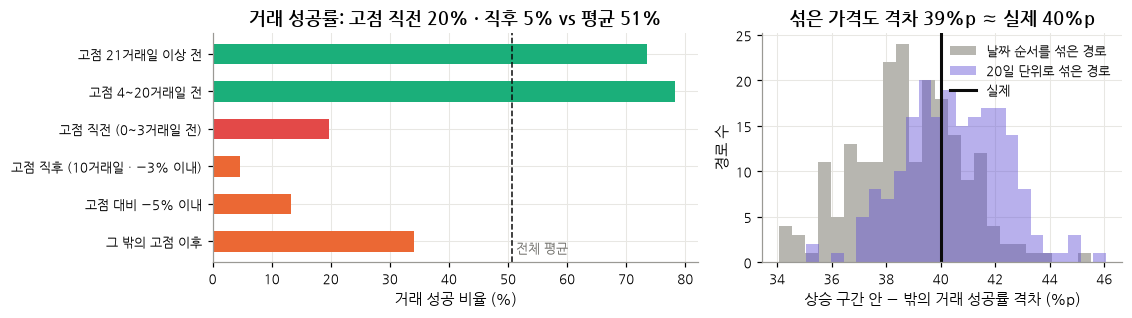

In [16]:
# 동기 섞기 대조군과 검정력

_dates = X["069500"].loc[T0:].index  # 2021+ 공통 날짜

assert all(X[c].loc[T0:].index.equals(_dates) for c in ALL), "종목마다 날짜가 다름"  # 공통 날짜 확인

_bars = {}  # 종목별 일봉 비율
for c in ALL:  # 20종마다
    x = X[c]  # 지표 표
    pc = x.Close.shift()  # 전일 종가
    m = x.index >= T0  # 2021+
    _bars[c] = np.c_[(x.Open / pc)[m], (x.High / pc)[m], (x.Low / pc)[m], (x.Close / pc)[m]]  # 비율 배열

def path_delta(order=None, phi=0.0, seed=0):  # 한 경로의 Δ. order=None 이면 실제 순서
    n1, n, s1, s = 0, 0, 0.0, 0.0  # Y=1 수 · 전체 수 · Y=1 양성 · 전체 양성
    for c in ALL:  # 20종마다
        ra = _bars[c] if order is None else _bars[c][order]  # 순서 적용
        lr = np.log(ra[:, 3])  # 로그 수익
        if phi:  # 추세 지속성을 심을 때
            sig = lr.std()  # 일 변동성
            past = pd.Series(lr).rolling(20).mean().shift().fillna(0).values  # 과거 20일 평균 수익
            add = phi * np.sign(past) * sig  # 과거 방향으로 일 변동성의 phi 배를 더함
            ra = ra * np.exp(add)[:, None]  # 네 가격 비율을 함께 이동
        cl = 10000 * np.cumprod(ra[:, 3])  # 새 종가
        pv = np.r_[10000, cl[:-1]]  # 새 전일 종가
        O, H, L = ra[:, 0] * pv, ra[:, 1] * pv, ra[:, 2] * pv  # 새 시 · 고 · 저
        s_cl = pd.Series(cl, index=_dates)  # 종가 시리즈
        zz_ = zigzag(s_cl)  # 지그재그
        y = np.zeros(len(cl), int)  # 정답
        for l in zz_[zz_.gain >= LEG_MIN].itertuples():  # 급등 구간마다
            y[(_dates > l.trough) & (_dates <= l.peak)] = 1  # 구간 표시
        tr = pd.concat([pd.Series(H - L), pd.Series(np.abs(H - np.r_[np.nan, cl[:-1]])), pd.Series(np.abs(L - np.r_[np.nan, cl[:-1]]))], axis=1).max(axis=1)  # 변동폭
        atr = (tr.ewm(alpha=1 / 14, adjust=False).mean() / cl).values.copy()  # ATR% (쓰기 가능한 복사본)
        atr[:19] = np.nan  # 지표가 생기기 전은 제외
        t = tb_label(O, H, L, cl, atr)  # 거래 기회 라벨
        ok = ~np.isnan(t)  # 유효 행
        n1 += int((y[ok] == 1).sum())  # Y=1 수 누적
        n += int(ok.sum())  # 전체 수 누적
        s1 += t[ok & (y == 1)].sum()  # Y=1 양성 누적
        s += t[ok].sum()  # 전체 양성 누적
    return s1 / n1 - (s - s1) / (n - n1), s1 / n1, (s - s1) / (n - n1)  # Δ · P(T|Y=1) · P(T|Y=0)

def sync_order(rng, block=1):  # 날짜 동기 순서: 모든 종목에 같은 순서 적용
    m = len(_bars[ALL[0]])  # 날짜 수
    if block == 1:  # 일봉 섞기
        return rng.permutation(m)  # 전체 순서
    st = np.arange(0, m, block)  # 블록 시작
    return np.concatenate([np.arange(a, min(a + block, m)) for a in rng.permutation(st)])  # 블록 순서

_fn = RES / "cache" / "x3_shuffle.parquet"  # 저장 위치
t0 = time.time()  # 시간 측정

if _fn.exists():  # 이미 계산했으면
    SH3 = pd.read_parquet(_fn)  # 읽기
else:  # 처음이면
    rows = []  # 결과 행
    for blk, tag in [(1, "일봉 동기"), (20, "20일 블록 동기")]:  # 섞기 방식마다
        for r in range(200):  # 200경로
            d, a, b_ = path_delta(sync_order(np.random.default_rng([0, r, blk]), blk))  # 한 경로 계산
            rows.append(dict(방식=tag, rep=r, phi=0.0, d=d, p1=a, p0=b_))  # 행 추가
    for ph in [.05, .10, .20, .40]:  # 심는 추세 세기마다
        for r in range(50):  # 50경로
            d, a, b_ = path_delta(sync_order(np.random.default_rng([1, r, int(ph * 100)]), 1), ph)  # 추세를 심은 경로
            rows.append(dict(방식="주입", rep=r, phi=ph, d=d, p1=a, p0=b_))  # 행 추가
    SH3 = pd.DataFrame(rows)  # 표로
    SH3.to_parquet(_fn)  # 저장
print(f"대조군 {time.time() - t0:.0f}초")  # 소요 시간

REAL_D = path_delta()  # 같은 조건(2021+ 만 잘라 재계산)의 실제 값
_s = {t: SH3[SH3.방식 == t] for t in ["일봉 동기", "20일 블록 동기"]}  # 방식별

X3C = pd.DataFrame([dict(방식=t, 평균=g.d.mean(), 하한=g.d.quantile(.025), 상한=g.d.quantile(.975), P1평균=g.p1.mean(), P0평균=g.p0.mean(), 실제=REAL_D[0], 판정="위" if REAL_D[0] > g.d.quantile(.975) else ("아래" if REAL_D[0] < g.d.quantile(.025) else "안")) for t, g in _s.items()])  # 비교표
X3C.to_csv(RES / "x3_control.csv", index=False, encoding="utf-8-sig")  # 저장
show(X3C.round(4))  # 출력

_ub = _s["일봉 동기"].d.quantile(.975)  # 일봉 대조군 상한
PW = SH3[SH3.방식 == "주입"].groupby("phi").d.agg(평균="mean", 검출률=lambda v: (v > _ub).mean()).reset_index()  # 검출률
show(PW.round(3))  # 출력

PW.to_csv(RES / "x3_power.csv", index=False, encoding="utf-8-sig")  # 저장
NUM2["X3_control"] = dict(real=REAL_D[0], real_p1=REAL_D[1], real_p0=REAL_D[2], rows={r.방식: dict(m=r.평균, lo=r.하한, hi=r.상한, p1=r.P1평균, p0=r.P0평균, v=r.판정) for r in X3C.itertuples()}, power={str(r.phi): dict(m=r.평균, det=r.검출률) for r in PW.itertuples()})  # 저장

_t = X3B[X3B.기간 == "2021 후"].set_index("위치")  # 2021 후 위치표

# ======

fig, axs = plt.subplots(1, 2, figsize=(10.4, 3), gridspec_kw=dict(width_ratios=[1.35, 1]))  # 두 칸
ys = np.arange(len(_t))  # 위치
_cols = [AQUA if "거래일 이상 전" in i or "4~20" in i else (RED if "직전" in i else ORANGE) for i in _t.index]  # 위치별 색
axs[0].barh(ys, _t.Y_TB * 100, color=_cols, height=.55)  # 막대
axs[0].axvline(NUM2["X3_cond"]["Y_TB|2021 후"]["base"] * 100, color=INK, lw=1, ls="--")  # 기저율 선
axs[0].annotate("전체 평균", (NUM2["X3_cond"]["Y_TB|2021 후"]["base"] * 100 + .6, len(_t) - .7), fontsize=8.5, color=MUTED)  # 이름
axs[0].set_yticks(ys, _t.index)  # 눈금
axs[0].invert_yaxis()  # 위에서 아래로
axs[0].set_xlabel("거래 성공 비율 (%)")  # 축 이름
axs[0].set_title(f"거래 성공률: 고점 직전 {_t.Y_TB.iloc[2] * 100:.0f}% · 직후 {_t.Y_TB.iloc[3] * 100:.0f}% vs 평균 {NUM2['X3_cond']['Y_TB|2021 후']['base'] * 100:.0f}%")  # 제목
axs[1].hist(_s["일봉 동기"].d * 100, bins=24, color=GRAY, label="날짜 순서를 섞은 경로")  # 대조 분포
axs[1].hist(_s["20일 블록 동기"].d * 100, bins=24, color=VIOLET, alpha=.45, label="20일 단위로 섞은 경로")  # 대조 분포
axs[1].axvline(REAL_D[0] * 100, color=INK, lw=2, label="실제")  # 실제 값
axs[1].set_xlabel("상승 구간 안 − 밖의 거래 성공률 격차 (%p)")  # 축 이름
axs[1].set_ylabel("경로 수")  # 축 이름
axs[1].set_title(f"섞은 가격도 격차 {_s['일봉 동기'].d.mean() * 100:.0f}%p ≈ 실제 {REAL_D[0] * 100:.0f}%p")  # 제목
axs[1].legend()  # 범례
savefig(fig, "x3_bands")  # 저장
dump()  # 수치 저장

#### 다. 보충: 상승 구간 라벨과 거래 성공 라벨이 겹치는 이유

- 상승 구간 라벨은 미래 상승을 보고 사후에 정한 것이므로, 시장에 패턴이 없어도 상승 구간 안의 날 뒤에는 가격이 오를 수밖에 없습니다
- 가격의 날짜 순서를 무작위로 섞은 가상 경로(전 종목 같은 순서, 200개)에서도 두 라벨의 성공률 격차(약 40%p)가 그대로 나옵니다. 섞은 경로에 약한 추세 지속성(과거 20일 방향으로 일 변동성의 10%만큼 기울임)을 심으면 이 검정이 50경로 모두에서 잡아내므로 검정력은 충분합니다
- 따라서 두 라벨의 겹침은 시장의 성질이 아니라 정의에서 나오며, '상승 구간을 잘 맞힌다'는 사실을 '수익 나는 날을 안다'는 근거로 쓸 수 없습니다

#### 라. 보충: 수익 나는 날을 직접 학습하는 방안 — 보류

- 입력 · 모델 · 학습 방식은 그대로 두고 학습 정답만 거래 성공 라벨로 바꿈 (학습 · 평가 사이 60거래일 공백)
- 학습 효과는 **정답을 시간축으로 무작위로 밀어 학습한 대조 모델 20개**와 비교합니다

In [17]:
# 학습표에 Y_TB 를 붙이고 walk-forward 학습
_lb = LB[["code", "date", "Y_TB"]].rename(columns={"date": "Date"})  # 붙일 라벨
FT2 = FT[FT.code.isin(ALL)].rename_axis("Date").reset_index()  # 20종 학습표 (날짜를 열로)
FT2 = FT2.merge(_lb, on=["code", "Date"], how="left").set_index("Date")  # 라벨 병합
FT2["year"] = FT2.index.year  # 연도 열
for yr in range(TEST_START, int(FT2.year.max()) + 1):  # 평가 연도마다
    tr_ = FT2[FT2.year < yr]  # 학습 자료
    cut = tr_.index.max() - pd.tseries.offsets.BDay(60)  # 경계
    last = tr_[tr_.index <= cut].index.max()  # 학습 마지막 날
    ix_ = X["069500"].index  # 거래일 달력
    assert ix_[min(ix_.get_loc(last) + 21, len(ix_) - 1)] < pd.Timestamp(f"{yr}-01-01"), yr  # 그 라벨이 평가 시작 전에 확정됨
check(True, "학습 시점 점검: 학습 마지막 날의 거래 성공 라벨은 모두 평가 시작 전에 확정")  # 사전 조건
t0 = time.time()  # 시간 측정
PY = gbm_prob(ALL, ALL)  # 기존 모델 M_Y (20종 합동)
PT = gbm_prob(ALL, ALL, target="Y_TB", ft=FT2, tag="TB")  # 새 모델 M_T (20종 합동)
print(f"20종 합동 학습 {time.time() - t0:.0f}초")  # 소요 시간
def join_lab(pr, lb=LB):  # 예측에 라벨 붙이기
    return pd.DataFrame(dict(code=pr.code.values, date=pr.index, p=pr.p.values)).merge(lb[["code", "date", "Y_TB"]], on=["code", "date"]).dropna(subset=["Y_TB", "p"])  # 유효 행
def delta_auc(pa, pb, lb=LB, B=500):  # ΔAUC (M_T − M_Y) 와 분기 묶음 구간
    a, b_ = join_lab(pa, lb), join_lab(pb, lb)  # 라벨 붙이기
    j = a.merge(b_, on=["code", "date", "Y_TB"], suffixes=("_t", "_y"))  # 같은 행으로 맞춤
    q = j.date.dt.to_period("Q").values  # 분기
    u = pd.unique(q)  # 분기 목록
    gi = [np.where(q == k)[0] for k in u]  # 분기별 위치
    rng = np.random.default_rng(0)  # 난수
    yy, pt_, py_ = j.Y_TB.values, j.p_t.values, j.p_y.values  # 배열
    s = []  # 재표집 값
    for _ in range(B):  # 재표집마다
        ii = np.concatenate([gi[p] for p in rng.integers(0, len(u), len(u))])  # 분기 복원 추출
        s.append(auc(yy[ii], pt_[ii]) - auc(yy[ii], py_[ii]))  # ΔAUC
    by_code = j.groupby("code").apply(lambda g: auc(g.Y_TB.values, g.p_t.values) - auc(g.Y_TB.values, g.p_y.values))  # 종목 안 ΔAUC
    return dict(auc_t=auc(yy, pt_), auc_y=auc(yy, py_), d=auc(yy, pt_) - auc(yy, py_), lo=np.percentile(s, 2.5), hi=np.percentile(s, 97.5), within=by_code.mean(), n=len(j), pos=float((by_code > 0).mean()))  # 요약
R20 = delta_auc(PT, PY)  # 20종 결과
P5Y = gbm_prob(S1, S1)  # 5종 합동 M_Y
P5T = gbm_prob(S1, S1, target="Y_TB", ft=FT2, tag="TB")  # 5종 합동 M_T
R5 = delta_auc(P5T, P5Y)  # 5종 결과
# 대조군: 라벨을 종목 안에서 원형 이동해 학습
_fn = RES / "cache" / "x4_control.csv"  # 저장 위치
if _fn.exists():  # 이미 있으면
    CT4 = pd.read_csv(_fn)  # 읽기
else:  # 처음이면
    rows = []  # 결과 행
    for r in range(20):  # 20회
        rng = np.random.default_rng([4, r])  # 난수
        f_ = FT2.copy()  # 복사
        f_["ctrl"] = np.nan  # 대조 라벨 열
        for c in ALL:  # 종목마다
            m = (f_.code == c).values  # 그 종목 행
            v = f_.loc[m, "Y_TB"].values  # 라벨
            f_.loc[m, "ctrl"] = np.roll(v, int(rng.integers(60, max(61, len(v) - 60))))  # 원형 이동
        pc = gbm_prob(ALL, ALL, target="ctrl", ft=f_, tag=f"CTRL{r}")  # 학습
        rows.append(dict(rep=r, auc=auc(join_lab(pc).Y_TB.values, join_lab(pc).p.values)))  # 실제 라벨로 채점
        print("대조", r, round(rows[-1]["auc"], 4), f"{time.time() - t0:.0f}초", flush=True)  # 진행 표시
    CT4 = pd.DataFrame(rows)  # 표로
    CT4.to_csv(_fn, index=False)  # 저장
show(CT4.auc.describe().round(4))  # 대조군 요약
NUM2["X4"] = dict(r20=R20, r5=R5, ctrl=dict(m=CT4.auc.mean(), lo=CT4.auc.quantile(.025), hi=CT4.auc.quantile(.975), max=CT4.auc.max()))  # 저장
dump()  # 수치 저장

✔ 학습 시점 점검: 학습 마지막 날의 거래 성공 라벨은 모두 평가 시작 전에 확정
20종 합동 학습 0초


,auc
count,20.0000
mean,0.4956
std,0.0152
min,0.4703
25%,0.4881
50%,0.4952
75%,0.5016
max,0.5248


,모델,수익,MDD,매수 건수,매수허용일 비율,F1(상승구간),건당 평균수익,무작위 평균,무작위 하한,무작위 상한,거래성공 비율,무작위 거래성공,무작위 상한(거래성공),고점−5%이내 매수,고점직전 매수,상승구간밖 매수
0,상승 구간 학습 모델,0.6214,-0.1796,782,0.5021,0.7328,0.0128,0.0103,0.0058,0.0148,0.5217,0.5234,0.5525,0.1125,0.0396,0.3760
1,수익일 학습 모델 · 0.6/0.4,0.6175,-0.1110,361,0.6290,0.5974,0.0116,0.0051,-0.0000,0.0106,0.5180,0.5059,0.5513,0.0748,0.0249,0.5125
2,수익일 학습 모델 · 매수 비율 맞춤,0.5548,-0.1756,1382,0.5667,0.5562,0.0094,0.0056,0.0031,0.0082,0.5123,0.5086,0.5318,0.0651,0.0137,0.5912


무작위 대비 건당 수익 우위 (매수 비율 맞춤 · 보정 전): 통과


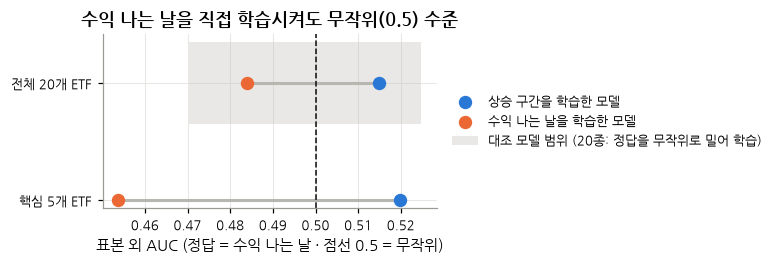

In [18]:
# 매매로 옮겨 보기: 임계 두 판 (a) 0.6/0.4 고정 (b) 학습 구간 켜짐률 맞춤
def thresholds_matched(train, ft):  # 해마다 M_T 임계를 M_Y 의 학습 구간 켜짐률에 맞춤 (과거 자료만 사용)
    fn = CACHE / f"thr_{hashlib.md5(json.dumps(sorted(train)).encode()).hexdigest()[:10]}.json"  # 저장 위치
    if fn.exists():  # 있으면
        return json.loads(fn.read_text())  # 읽기
    out = {}  # 연도별 임계
    for yr in range(TEST_START, int(ft.year.max()) + 1):  # 평가 연도마다
        tr = ft[(ft.year < yr) & ft.code.isin(train)]  # 학습 자료
        tr = tr[tr.index <= tr.index.max() - pd.tseries.offsets.BDay(60)]  # 경계
        tr = tr[tr.Y_TB.notna()]  # 라벨 있는 행
        kw = dict(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=200, random_state=SEED)  # 같은 설정
        p_y = HistGradientBoostingClassifier(**kw).fit(tr[FEATURES], tr.y.astype(int)).predict_proba(tr[FEATURES])[:, 1]  # M_Y 학습 구간 점수
        p_t = HistGradientBoostingClassifier(**kw).fit(tr[FEATURES], tr.Y_TB.astype(int)).predict_proba(tr[FEATURES])[:, 1]  # M_T 학습 구간 점수
        out[str(yr)] = [float(np.quantile(p_t, 1 - (p_y >= GBM_ON).mean())), float(np.quantile(p_t, 1 - (p_y >= GBM_OFF).mean()))]  # 같은 켜짐률이 되는 on · off
    fn.write_text(json.dumps(out))  # 저장
    return out  # 반환
THR = thresholds_matched(ALL, FT2)  # 연도별 임계
pass  # 출력
def hyst_year(pr, thr):  # 연도별 임계로 상태 계산
    st = {}  # 종목별 상태
    for c in pr.code.unique():  # 종목마다
        p = pr[pr.code == c].p  # 점수
        s, v_ = [], 0  # 상태 목록 · 현재 상태
        for d, val in p.items():  # 날짜순으로
            on, off = thr[str(d.year)]  # 그해 임계
            if v_ == 0 and val >= on:  # 켜짐 조건
                v_ = 1  # 켬
            elif v_ == 1 and val <= off:  # 꺼짐 조건
                v_ = 0  # 끔
            s.append(v_)  # 기록
        st[c] = pd.Series(s, index=p.index).reindex(X[c].index).fillna(0)  # 날짜 맞춤
    return dict(name="M_T", entry={c: onset(v) for c, v in st.items()}, state=st, start=pr.index.min())  # 모델 묶음
M_Y = MODELS["20종"]["GBM합동"]  # 기존 모델
M_Ta = make_model(PT, GBM_ON, GBM_OFF, "M_T")  # (a) 0.6/0.4 고정
M_Tb = hyst_year(PT, THR)  # (b) 켜짐률 맞춤
_pred = pred_of("20종", "GBM합동")  # 예측이 있는 날
_S = dict(Y_TB=PN.Y_TB.values, 평균수익=PN.ret.values, P2=((PN.dd >= -.05) & (PN.Y == 0)).values.astype(float), M3=((PN.Y == 1) & (PN.to_peak <= 3)).values.astype(float), Y0=(PN.Y == 0).values.astype(float))  # 비교 집합
rows = []  # 결과 행
for nm, m in [("상승 구간 학습 모델", M_Y), ("수익일 학습 모델 · 0.6/0.4", M_Ta), ("수익일 학습 모델 · 매수 비율 맞춤", M_Tb)]:  # 모델마다
    lgs = {c: sim(c, (m, "규칙1", REBUY, False))[1] for c in ALL}  # 매매
    cv = fill_curve(ALL, None, 10, lgs)  # 체결 곡선
    f = f1_table(ALL, m)  # F1
    on_rate = np.mean([m["state"][c].reindex(X[c].index[X[c].index >= T0]).fillna(0).mean() for c in ALL])  # 켜짐률
    nl = null_n2s(ALL, m, REBUY, _pred, _S)  # 귀무 비교
    rows.append(dict(모델=nm, 수익=cv.iloc[-1] - 1, MDD=mdd(cv), 진입=nl["평균수익"]["n"], 켜짐률=on_rate, F1_Y=f["F1"], 평균수익=nl["평균수익"]["real"], 귀무=nl["평균수익"]["null"], 귀무하한=nl["평균수익"]["lo"], 귀무상한=nl["평균수익"]["hi"], Y_TB비율=nl["Y_TB"]["real"], Y_TB귀무=nl["Y_TB"]["null"], Y_TB상한=nl["Y_TB"]["hi"], P2=nl["P2"]["real"], M3=nl["M3"]["real"], Y0=nl["Y0"]["real"]))  # 행 추가
X4T = pd.DataFrame(rows)  # 표로
X4T.to_csv(RES / "x4_trading.csv", index=False, encoding="utf-8-sig")  # 저장
show(X4T.round(4))  # 출력
NUM2["X4_trading"] = {r["모델"]: {k: v for k, v in r.items() if k != "모델"} for r in rows}  # 저장
_u = rows[2]  # 켜짐률 맞춘 판
NUM2["X4"]["verdict_learn"] = "통과" if (R20["lo"] > 0 and R20["auc_t"] > NUM2["X4"]["ctrl"]["hi"]) else "미통과"  # 사전 판정: 학습 가능 (20종)
NUM2["X4"]["verdict_use"] = "통과" if _u["평균수익"] > _u["귀무상한"] else "미통과"  # 사전 판정: 쓸모
print("무작위 대비 건당 수익 우위 (매수 비율 맞춤 · 보정 전):", NUM2["X4"]["verdict_use"])  # 출력
fig, ax = plt.subplots(figsize=(7.2, 2.5))  # 그림 틀
_l = ["전체 20개 ETF", "핵심 5개 ETF"]  # 유니버스 이름
_vy, _vt = [R20["auc_y"], R5["auc_y"]], [R20["auc_t"], R5["auc_t"]]  # 두 모델의 AUC
ys = np.arange(2)  # 위치
ax.hlines(ys, _vt, _vy, color=GRAY, lw=2)  # 두 점을 잇는 선
ax.scatter(_vy, ys, s=60, color=BLUE, zorder=3, label="상승 구간을 학습한 모델")  # 기존 모델
ax.scatter(_vt, ys, s=60, color=ORANGE, zorder=3, label="수익 나는 날을 학습한 모델")  # 새 모델
ax.fill_between([CT4.auc.min(), CT4.auc.max()], -.35, .35, color=GRAY, alpha=.3, lw=0, label="대조 모델 범위 (20종: 정답을 무작위로 밀어 학습)")  # 대조 범위
ax.axvline(.5, color=INK, lw=1, ls="--")  # 무작위 선
ax.set_yticks(ys, _l)  # 눈금
ax.invert_yaxis()  # 위에서 아래로
ax.set_xlabel("표본 외 AUC (정답 = 수익 나는 날 · 점선 0.5 = 무작위)")  # 축 이름
ax.set_title("수익 나는 날을 직접 학습시켜도 무작위(0.5) 수준")  # 제목
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5))  # 범례
savefig(fig, "x4_auc")  # 저장
dump()  # 수치 저장

| 20개 ETF · 통합 학습 | 상승 구간 학습 모델 | 수익일 학습 모델 |
|---|---|---|
| 거래 성공 라벨 표본 외 AUC | 0.515 | 0.484 |
| 대조 모델 20개 (정답을 무작위로 밀어 학습) | 평균 0.496 · 범위 0.47 ~ 0.52 | |

- 수익일 학습 모델의 AUC는 오히려 낮고(차이 −0.031 [−0.054, −0.007]) 대조 모델과 같은 범위입니다. 핵심 5개 ETF도 0.454 vs 0.520으로 같은 방향 → **예측력 개선 확인되지 않습니다**
- 누적 수익(20종 · 종목 동일 비중): 상승 구간 모델 +62.1%, 수익일 모델(0.6/0.4) +61.7%, 수익일 모델(매수 허용일 비율을 맞춤) +55.5%
- 예외: 수익일 모델 두 변형 모두 **매수 건당 평균 수익**이 조건 맞춤 무작위 매수의 95% 범위 상단을 넘음(+1.16% vs +1.06%, +0.94% vs +0.82%). 다중 검정 보정 전이고 AUC · 누적 수익으로는 확인되지 않아 **보류(추가 검증 과제)** 로 둡니다
- 13개 기술적 지표로는 '20일 안의 방향'을 안정적으로 예측할 정보가 부족한 것으로 판단됩니다. 같은 입력으로 상승 구간은 잘 판별하므로 모델 구조보다 **입력 정보의 한계**일 가능성이 큽니다 → 질의 2 · 3

#### 마. 보충: 임계값 0.6 / 0.4 조정 — 현행 유지

- 진입 임계값 6개(0.50 ~ 0.75) × 해제 임계값 4개(0.30 ~ 0.50) = 24개 조합을 계산합니다
- 24개 중 최고를 고르면 우연만으로도 좋아 보이므로, 그 선택 효과까지 반영한 **다중비교 보정 p값** 이 0.05 미만일 때만 우위로 판단합니다

,진입임계값,해제임계값,수익,MDD,F1,매수 건수,재진입 조건,신호유지(일),평균현금비중,재진입까지(일)
0,0.50,0.30,0.522,-0.246,0.757,192,68,16.069,0.564,16.588
1,0.50,0.40,0.537,-0.246,0.754,225,56,11.635,0.547,14.960
2,0.50,0.45,0.523,-0.251,0.751,245,51,9.671,0.539,14.055
3,0.50,0.50,0.536,-0.255,0.747,264,42,8.382,0.534,13.502
4,0.55,0.30,0.420,-0.301,0.755,184,66,16.620,0.573,17.498
5,0.55,0.40,0.438,-0.294,0.751,212,55,12.541,0.559,16.050
6,0.55,0.45,0.447,-0.300,0.745,228,50,10.548,0.553,15.275
7,0.55,0.50,0.446,-0.301,0.742,245,42,9.159,0.550,14.734
8,0.60,0.30,0.447,-0.297,0.757,165,63,18.197,0.592,19.776
9,0.60,0.40,0.454,-0.296,0.752,191,52,13.565,0.579,18.214


,진입임계값,해제임계값,수익,MDD,F1,매수 건수,재진입 조건,신호유지(일),평균현금비중,재진입까지(일)
0,0.50,0.30,0.719,-0.165,0.748,773,280,20.781,0.563,16.258
1,0.50,0.40,0.664,-0.175,0.743,997,219,13.831,0.543,13.725
2,0.50,0.45,0.665,-0.175,0.738,1128,180,11.264,0.528,12.490
3,0.50,0.50,0.630,-0.176,0.734,1291,151,9.124,0.511,11.065
4,0.55,0.30,0.706,-0.164,0.746,702,265,22.185,0.575,17.891
5,0.55,0.40,0.647,-0.169,0.738,882,205,15.248,0.559,15.611
6,0.55,0.45,0.658,-0.166,0.733,991,168,12.548,0.548,14.401
7,0.55,0.50,0.625,-0.168,0.729,1114,141,10.341,0.534,13.045
8,0.60,0.30,0.686,-0.172,0.743,639,250,23.616,0.589,19.834
9,0.60,0.40,0.621,-0.180,0.733,792,192,16.461,0.577,17.651


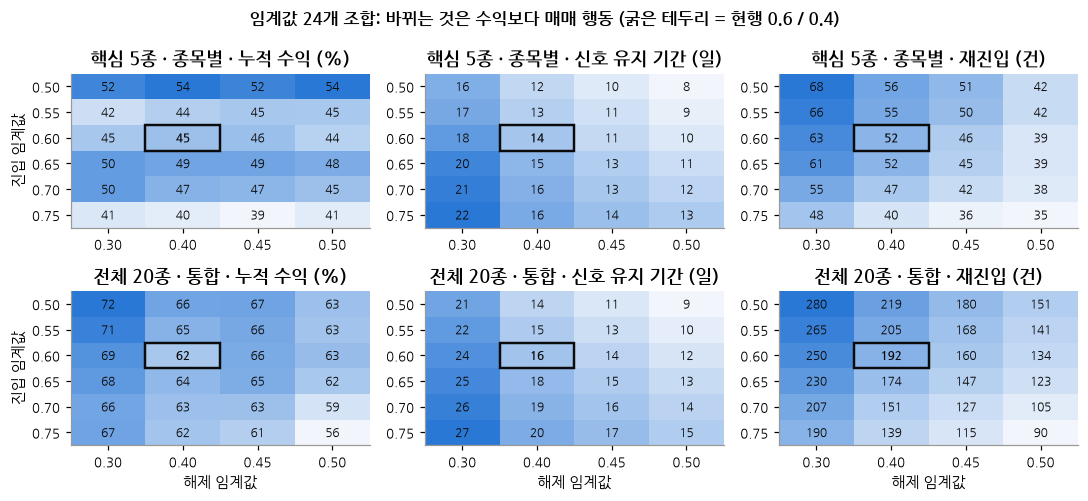

In [19]:
# 격자 계산
ON5, OFF5 = [.50, .55, .60, .65, .70, .75], [.30, .40, .45, .50]  # 사전에 정한 격자 24칸
def grid(u, train):  # 한 묶음의 격자 전체
    codes = UNIV[u]  # 대상
    rows, curves = [], {}  # 결과 · 곡선
    for on in ON5:  # 켜짐마다
        for off in OFF5:  # 꺼짐마다
            m = model_for(codes, train, on, off)  # 임계 적용
            lgs = {c: sim(c, (m, "규칙1", REBUY, False))[1] for c in codes}  # 매매
            cv = fill_curve(codes, None, 10, lgs)  # 체결 곡선
            curves[(on, off)] = cv  # 저장
            dur, nen, nre, wait = [], 0, 0, []  # 지속 · 진입 · 재매수 · 재진입 대기
            cash = []  # 현금 비중
            for c in codes:  # 종목마다
                s = m["state"][c].reindex(X[c].index[X[c].index >= T0]).fillna(0).astype(int).values  # 상태
                edge = np.flatnonzero(np.diff(np.r_[0, s, 0]))  # 상태 변화 위치
                dur += list(edge[1::2] - edge[::2])  # 켜진 구간 길이
                e = lgs[c]  # 사건
                nen += int((e.event == "진입").sum())  # 진입 수
                nre += int((e.event == "재매수").sum())  # 재매수 수
                ix = X[c].index  # 날짜
                ex_ = ix.get_indexer(pd.to_datetime(e[e.event == "전량 청산"].date))  # 청산 위치
                bu_ = ix.get_indexer(pd.to_datetime(e[e.event.isin(["진입", "재매수"])].date))  # 매수 위치
                for a in ex_:  # 청산마다
                    nx = bu_[bu_ > a]  # 다음 매수
                    if len(nx):  # 있으면
                        wait.append(nx[0] - a)  # 대기 일수
                pos = pd.Series(0.0, index=ix)  # 보유 표시
                for t in parse(c, e):  # 거래마다
                    pos.iloc[t["entry_i"]: t["exit_i"] + 1] = 1.0  # 보유일
                cash.append(1 - pos.loc[T0:].mean())  # 현금 비중
            f = f1_table(codes, m)  # F1
            rows.append(dict(on=on, off=off, 수익=cv.iloc[-1] - 1, MDD=mdd(cv), F1=f["F1"], 진입=nen, 재매수=nre, 신호지속=np.mean(dur), 현금비중=np.mean(cash), 재진입대기=np.mean(wait) if wait else np.nan))  # 행 추가
    return pd.DataFrame(rows), curves  # 반환
X5, RC = {}, {}  # 결과 · 검정
for u, tr_ in [("5종", "단독"), ("20종", "합동")]:  # 사전에 정한 두 모델
    g, cvs = grid(u, tr_)  # 격자 계산
    g.to_csv(RES / f"x5_grid_{u}.csv", index=False, encoding="utf-8-sig")  # 저장
    X5[u] = g  # 보관
    d_ = pd.concat({k: v.pct_change().fillna(0) for k, v in cvs.items()}, axis=1)  # 조합별 일별 수익
    keys = list(cvs)  # 조합 목록
    b0 = keys.index((.60, .40))  # 기준값 위치
    def _tot(a):  # 조합별 로그 총수익
        return np.log1p(a).sum(axis=0)  # 합
    real = _tot(d_.values)  # 실제
    boots = quarter_boot(d_, lambda a: _tot(a), B=2000)  # 재표집
    dd_ = boots - boots[:, [b0]]  # 기준값 대비 차
    rd = real - real[b0]  # 실제 차
    stat = (dd_ - rd).max(axis=1)  # 가운데로 옮긴 최대 통계
    bi = int(np.argmax(rd))  # 최고 조합
    pv = float((stat >= rd.max()).mean())  # 보정 p 값
    no_h = keys.index((.50, .50))  # 이력 없는 칸
    RC[u] = dict(best=keys[bi], best_ret=g.수익.max(), base_ret=g[(g.on == .6) & (g.off == .4)].수익.iloc[0], p=pv, verdict="기준값보다 낫다" if pv < .05 else "격자 안에서 구별 안 됨", no_h=paired_ci(cvs[(.50, .50)], cvs[(.60, .40)]), lo=g.수익.min(), hi=g.수익.max(), pct=float((g.수익 < g[(g.on == .6) & (g.off == .4)].수익.iloc[0]).mean()), mdd_lo=g.MDD.min(), mdd_hi=g.MDD.max(), f1_lo=g.F1.min(), f1_hi=g.F1.max(), best_f1=g.loc[g.F1.idxmax(), ["on", "off"]].tolist(), best_ret_cell=g.loc[g.수익.idxmax(), ["on", "off"]].tolist(), corr_f1_ret=float(g[["F1", "수익"]].corr(method="spearman").iloc[0, 1]))  # 요약
    show(g.round(3))  # 표 출력
    _mono = g.groupby("on").apply(lambda t: t.sort_values("off").신호지속.is_monotonic_decreasing).mean()  # off 를 올리면 지속이 줄어드는 비율
    _mono2 = g.groupby("on").apply(lambda t: t.sort_values("off").재매수.is_monotonic_decreasing).mean()  # off 를 올리면 재매수가 줄어드는 비율
    RC[u]["mono_dur"], RC[u]["mono_rebuy"] = float(_mono), float(_mono2)  # 저장
    RC[u]["base"] = g[(g.on == .6) & (g.off == .4)].iloc[0].to_dict()  # 기준값 행
    RC[u]["noh"] = g[(g.on == .5) & (g.off == .5)].iloc[0].to_dict()  # 이력 없는 행
NUM2["X5"] = RC  # 저장
fig, axs = plt.subplots(2, 3, figsize=(10, 4.6))  # 여섯 칸
for r_, u in enumerate(["5종", "20종"]):  # 묶음마다
    g = X5[u]  # 격자
    for c_, (col, tt, mul, fmt_) in enumerate([("수익", "누적 수익 (%)", 100, "{:.0f}"), ("신호지속", "신호 유지 기간 (일)", 1, "{:.0f}"), ("재매수", "재진입 (건)", 1, "{:.0f}")]):  # 지표마다
        pv_ = g.pivot(index="on", columns="off", values=col) * mul  # 표
        ax = axs[r_, c_]  # 칸
        ax.grid(False)  # 격자선 끔
        ax.imshow(pv_.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", ["#f2f6fc", "#2a78d6"]), aspect="auto")  # 단일 색상 농도
        for i_, a_ in enumerate(pv_.index):  # 행마다
            for j_, b__ in enumerate(pv_.columns):  # 열마다
                hl = (a_ == .6 and b__ == .4)  # 기준값 칸
                ax.text(j_, i_, fmt_.format(pv_.iloc[i_, j_]), ha="center", va="center", fontsize=8, fontweight="bold" if hl else "normal", color=INK)  # 값 표시
                if hl:  # 기준값이면
                    ax.add_patch(plt.Rectangle((j_ - .5, i_ - .5), 1, 1, fill=False, ec=INK, lw=1.6))  # 테두리
        ax.set_xticks(range(len(pv_.columns)), [f"{v:.2f}" for v in pv_.columns])  # 꺼짐 눈금
        ax.set_yticks(range(len(pv_.index)), [f"{v:.2f}" for v in pv_.index])  # 켜짐 눈금
        ax.set_title(f"{ {'5종': '핵심 5종 · 종목별', '20종': '전체 20종 · 통합'}[u]} · {tt}")  # 제목
        if r_ == 1:  # 아래 줄이면
            ax.set_xlabel("해제 임계값")  # 축 이름
        if c_ == 0:  # 왼쪽 줄이면
            ax.set_ylabel("진입 임계값")  # 축 이름
fig.suptitle("임계값 24개 조합: 바뀌는 것은 수익보다 매매 행동 (굵은 테두리 = 현행 0.6 / 0.4)", fontweight="bold", fontsize=11)
savefig(fig, "x5_grid")  # 저장
dump()  # 수치 저장

| 모델 (종목 동일 비중 · 편도 0.1%) | 현행 0.6 / 0.4 | 24개 조합 최고 (조합) | 24개 조합 범위 | 다중비교 보정 p |
|---|---|---|---|---|
| 핵심 5개 ETF · 종목별 학습 | +45.4% | +53.7% (0.50 / 0.40) | +39.4 ~ +53.7% | 0.64 |
| 20개 ETF · 통합 학습 | +62.1% | +71.9% (0.50 / 0.30) | +56.4 ~ +71.9% | 0.35 |

- 두 모델 모두 최고 조합이 현행 값과 통계적으로 구별되지 않습니다 (24개 중 최고를 고른 선택 효과를 반영한 결과)
- 20개 ETF 에서는 현행 값이 하위권(현행보다 낮은 조합 17%)이고 낮은 진입 임계값(0.50)이 대체로 높습니다 → 다음 자료로 재확인할 후보이나 지금 바꿀 근거는 아닙니다
- 임계값이 확실히 바꾸는 것은 **매매 빈도**입니다. 해제 임계값을 올리면 모든 진입 임계값에서 신호 유지 기간이 짧아지고 재진입이 줄어듭니다

### 6.2 고점 근처 매수를 피하는 방안

> **확인한 것** 큰 손실은 고점 직전 추격 매수에서 나오지만, 검토한 과열 지표(이격도 · RSI)로는 대부분 걸러지지 않습니다(61건 중 6건). → **질의 3: 추격 매수를 거르는 기준**

#### 가. 검토 내용

- 매수 신호가 상승 구간 밖에서 나면 손실로 이어집니다. 어느 위치의 매수가 가장 비싼지, 그 위치를 **그날 알 수 있는 정보**로 피할 수 있는지 검토합니다
- 모든 거래일에 한 번씩 가상으로 매수하고 같은 매도 규칙으로 팔았을 때의 손익을, 확정된 고점 기준 위치(고점 후 경과일 · 고점 대비 등락률)로 나누어 봅니다
- 고점은 사후에 확정되므로 이 위치는 **원인 진단 도구**이며 실시간 신호가 아닙니다

46832 행 · 0초


,표본,지표,건수,평균,중앙값,손실 거래 비율,손실 합,날짜 비중,손실 기여도
0,2021 전,A k≤10·dd>−3%,355,-0.0373,-0.0293,0.9437,-13.3571,0.0452,0.1322
1,2021 전,고점 뒤 전체,7849,-0.0082,-0.0063,0.6594,-101.0550,1.0000,1.0000
2,2021 전,D k≥61·dd≤−10%,3473,-0.0048,-0.0044,0.6300,-33.1522,0.4425,0.3281
3,2021 전,Y=1,8735,0.0188,0.0016,0.4638,-81.6321,NaN,NaN
4,2021 전,전체,16982,0.0056,-0.0029,0.5588,-188.9518,NaN,NaN
5,2021 후,A k≤10·dd>−3%,660,-0.0316,-0.0291,0.9061,-21.2800,0.0463,0.1027
6,2021 후,고점 뒤 전체,14243,-0.0097,-0.0080,0.6612,-207.1473,1.0000,1.0000
7,2021 후,D k≥61·dd≤−10%,4552,-0.0072,-0.0062,0.6417,-52.3039,0.3196,0.2525
8,2021 후,Y=1,15594,0.0283,0.0021,0.4678,-171.3757,NaN,NaN
9,2021 후,전체,29837,0.0102,-0.0037,0.5601,-378.5230,NaN,NaN


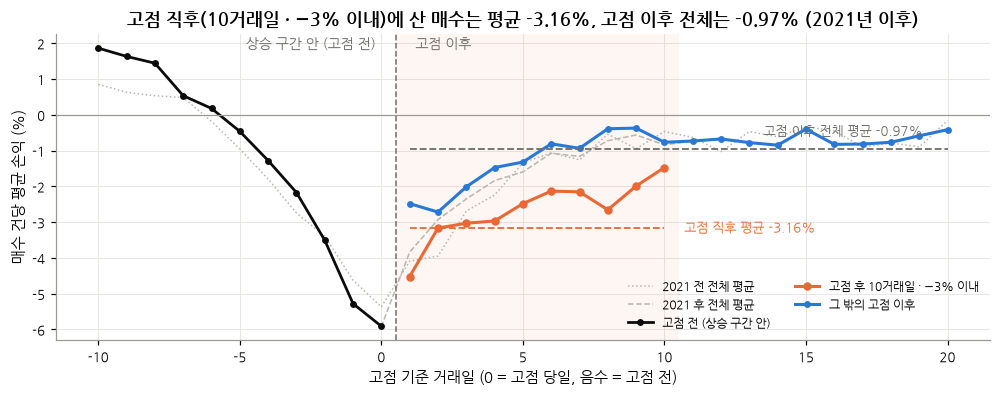

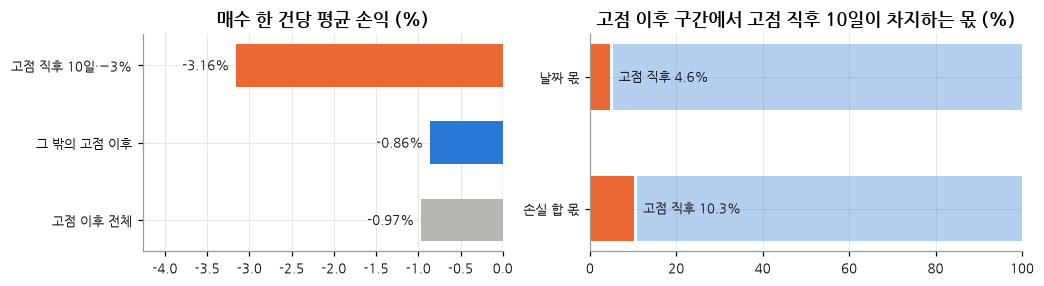

In [20]:
# 모든 날 강제 진입 패널
t0 = time.time()  # 시간 측정
FP_ = forced_panel("규칙1")  # 규칙 1 패널
print(len(FP_), f"행 · {time.time() - t0:.0f}초")  # 규모
F = FP_[(~FP_.provisional) & FP_.ret.notna()].copy()  # 미확정 · 미청산 제외
REG = {"A k≤10·dd>−3%": lambda d: d.in_zone & (d.k <= 10) & (d.dd > -.03), "고점 뒤 전체": lambda d: d.in_zone, "D k≥61·dd≤−10%": lambda d: d.in_zone & (d.k >= 61) & (d.dd <= -.10), "Y=1": lambda d: d.Y == 1, "전체": lambda d: pd.Series(True, index=d.index)}  # 비교 집합
rows = []  # 결과 행

for sp in ["2021 전", "2021 후"]:  # 표본마다
    q = F[F.split == sp]  # 표본
    zt = q[q.in_zone]  # 구역 전체
    for nm, fn in REG.items():  # 집합마다
        s = q[fn(q)]  # 집합 행
        rows.append(dict(표본=sp, 집합=nm, n=len(s), 평균=s.ret.mean(), 중앙값=s.ret.median(), 손실비율=(s.ret < 0).mean(), 손실합=s.ret.clip(upper=0).sum(), 일수몫=len(s) / len(zt) if nm not in ("Y=1", "전체") else np.nan, 손실몫=s.ret.clip(upper=0).sum() / zt.ret.clip(upper=0).sum() if nm not in ("Y=1", "전체") else np.nan))  # 행 추가

CT = pd.DataFrame(rows)  # 표로
CT.to_csv(RES / "panel_c_regions.csv", index=False, encoding="utf-8-sig")  # 저장
show(CT.round(4))  # 출력

_c = CT.set_index(["표본", "집합"])  # 조회용

NUM["C"] = {f"{a}|{b}": {k: float(v) for k, v in _c.loc[(a, b)].items()} for a, b in _c.index}  # PDF 용 저장

_ar = []  # 고점 전후 표
for sp in ["2021 전", "2021 후"]:  # 표본마다
    q = F[F.split == sp]  # 표본
    pre = q[(q.Y == 1) & q.to_peak.between(0, 10)].groupby("to_peak").ret.mean()  # 고점 앞 (0 = 당일)
    post = q[q.in_zone & (q.k <= 20)].groupby("k").ret.mean()  # 고점 뒤
    _ar.append(pd.concat([pd.Series(pre.values, index=-pre.index.astype(int)), pd.Series(post.values, index=post.index.astype(int))]).sort_index().rename(sp))  # −n 은 고점 전
AR = pd.concat(_ar, axis=1)  # 표로

NUM["C_peak"] = {str(k): dict(sel=AR.loc[k, "2021 전"], conf=AR.loc[k, "2021 후"]) for k in [-1, 0, 1]}  # PDF 용 저장

# ── 그림 1: 고점 전후 손익 곡선 — 위험구간 vs 일반구간 (2021 후가 주 표본, 2021 전 · 후 전체는 옅은 검증선) ──
q = F[F.split == "2021 후"]  # 주 표본
risk_m = q.in_zone & (q.k <= 10) & (q.dd > -.03)  # 고점 직후 (고점 뒤 10거래일 · 고점 대비 −3% 이내)
post = q[q.in_zone & (q.k <= 20)]  # 고점 뒤 20거래일
risk_k = post[risk_m.loc[post.index]].groupby("k").ret.mean()  # 위험구간 k 별 평균
gen_k = post[~risk_m.loc[post.index]].groupby("k").ret.mean()  # 일반구간 k 별 평균
pre_k = q[(q.Y == 1) & q.to_peak.between(0, 10)].groupby("to_peak").ret.mean()  # 고점 전 (0 = 고점 당일)
zt = q[q.in_zone]  # 고점 뒤 구역 전체
m_risk, m_gen, m_all = zt[risk_m.loc[zt.index]].ret.mean(), zt[~risk_m.loc[zt.index]].ret.mean(), zt.ret.mean()  # 세 평균
NUM["C_split"] = dict(risk=m_risk, gen=m_gen, all=m_all)  # 저장
fig, ax = plt.subplots(figsize=(9.2, 3.7))  # 그림 틀
for sp, ls in [("2021 전", ":"), ("2021 후", "--")]:  # 검증용 보조선
    ax.plot(AR.index, AR[sp] * 100, color=GRAY, lw=1, ls=ls, label=f"{sp} 전체 평균")  # 옅은 선
ax.axvspan(.5, 10.5, color=ORANGE, alpha=.06, lw=0)  # 위험구간이 놓일 수 있는 날 (k≤10)
ax.plot(-pre_k.index.astype(int), pre_k.values * 100, color=INK, marker="o", ms=3.5, lw=1.8, label="고점 전 (상승 구간 안)")  # 고점 전
ax.plot(risk_k.index.astype(int), risk_k.values * 100, color=ORANGE, marker="o", ms=4.5, label="고점 후 10거래일 · −3% 이내")  # 위험구간
ax.plot(gen_k.index.astype(int), gen_k.values * 100, color=BLUE, marker="o", ms=3.5, label="그 밖의 고점 이후")  # 일반구간
ax.hlines(m_risk * 100, 1, 10, color=ORANGE, lw=1.2, ls="--")  # 위험구간 평균선
ax.annotate(f"고점 직후 평균 {m_risk * 100:.2f}%", (10.7, m_risk * 100), color=ORANGE, fontsize=8.5, va="center")  # 값
ax.hlines(m_all * 100, 1, 20, color=MUTED, lw=1.2, ls="--")  # 고점 이후 전체 평균선
ax.annotate(f"고점 이후 전체 평균 {m_all * 100:.2f}%", (13.5, m_all * 100 + .4), color=MUTED, fontsize=8.5)  # 값
ax.axvline(.5, color=MUTED, lw=1, ls="--")  # Y 경계
ax.axhline(0, color="#9a9994", lw=.8)  # 0 선
_top_y = max(AR.max().max(), pre_k.max()) * 100  # 주석 높이
ax.annotate("상승 구간 안 (고점 전)", (-.2, _top_y), ha="right", fontsize=9, color=MUTED)  # 왼쪽 설명
ax.annotate("고점 이후", (1.2, _top_y), fontsize=9, color=MUTED)  # 오른쪽 설명
ax.set_xlabel("고점 기준 거래일 (0 = 고점 당일, 음수 = 고점 전)")  # 축 이름
ax.set_ylabel("매수 건당 평균 손익 (%)")  # 축 이름
ax.set_title(f"고점 직후(10거래일 · −3% 이내)에 산 매수는 평균 {m_risk * 100:.2f}%, 고점 이후 전체는 {m_all * 100:.2f}% (2021년 이후)")  # 결론 제목
ax.legend(loc="lower right", ncol=2, fontsize=8)  # 범례
savefig(fig, "c_peak")  # 저장

# ── 그림 2: 건당 손실 vs 손실 합의 몫 ──
_d = CT[CT.표본 == "2021 후"].set_index("집합")  # 2021 후 표
share_days = _d.loc["A k≤10·dd>−3%", "일수몫"]  # 위험구간의 날짜 몫
share_loss = _d.loc["A k≤10·dd>−3%", "손실몫"]  # 위험구간의 손실 합 몫
fig, axs = plt.subplots(1, 2, figsize=(9.6, 2.7), gridspec_kw=dict(width_ratios=[1, 1.2]))  # 두 칸
_names, _vals, _cols = ["고점 직후 10일·−3%", "그 밖의 고점 이후", "고점 이후 전체"], [m_risk, m_gen, m_all], [ORANGE, BLUE, GRAY]  # 세 막대
axs[0].barh(_names, np.array(_vals) * 100, color=_cols, height=.55)  # 건당 평균
for y_, v_ in enumerate(_vals):  # 값 표시
    axs[0].annotate(f"{v_ * 100:.2f}%", (v_ * 100 - .08, y_), ha="right", va="center", fontsize=8.5, color=INK)  # 막대 끝 값
axs[0].invert_yaxis()  # 위에서 아래로
axs[0].axvline(0, color="#9a9994", lw=.8)  # 0 선
axs[0].set_xlim(min(_vals) * 100 * 1.35, 0)  # 값 글자 자리
axs[0].set_title("매수 한 건당 평균 손익 (%)")  # 제목
for y_, (lab, a_) in enumerate([("날짜 몫", share_days), ("손실 합 몫", share_loss)]):  # 두 줄
    axs[1].barh(y_, a_ * 100, color=ORANGE, height=.5)  # 위험구간 몫
    axs[1].barh(y_, 100 - a_ * 100 - .6, left=a_ * 100 + .6, color=BLUE, alpha=.35, height=.5)  # 일반구간 몫 (틈 두기)
    axs[1].annotate(f"고점 직후 {a_ * 100:.1f}%", (a_ * 100 + 2, y_), va="center", fontsize=8.5, color=INK)  # 값
axs[1].set_yticks([0, 1], ["날짜 몫", "손실 합 몫"])  # 눈금
axs[1].invert_yaxis()  # 위에서 아래로
axs[1].set_xlim(0, 100)  # 0–100%
axs[1].set_title("고점 이후 구간에서 고점 직후 10일이 차지하는 몫 (%)")  # 제목
savefig(fig, "c_mean_sum")  # 저장

#### 나. 근거 ① — 고점 직전 · 당일 · 직후의 매수가 가장 비쌈

- 고점 후 10거래일 이내 · 고점 대비 −3% 이내에 산 매수는 평균 **−3.16%** 로, 고점 이후 구간 전체 평균(−0.97%)의 3배 이상 손실입니다 (2021년 이후 · 모든 거래일 가상 매수). 가장 나쁜 날은 고점 당일(−5.9%)과 그 전날(−5.3%)입니다
- 다만 이 구간은 날짜가 적어(고점 이후 날짜의 4.6%) 전체 손실에서 차지하는 몫은 10%입니다 → 건당 가장 위험한 곳과 전체 손실을 가장 많이 만드는 곳은 다릅니다
- 손실은 고점을 경계로 끊기지 않고 **고점 직전부터 이미 커집니다**. 상승 구간 라벨로는 '맞힌' 매수가 실제로는 가장 비싼 매수일 수 있습니다

In [21]:
# Y=1 손실 분해: 막차 · 보유 5일 이하 · 나머지
_t = []  # 거래표
for c in ALL:  # 종목마다
    d_ = coords(c)  # 좌표
    for t in parse(c, sim(c, BLB)[1], 10):  # 거래마다
        if t["open_end"]:  # 닫힌 거래만
            continue  # 건너뜀
        s_ = d_.iloc[t["sig_i"]]  # 신호일 좌표
        _t.append(dict(code=c, ret=t["ret"], Y=s_.Y, to_peak=s_.to_peak, k=s_.k, dd=s_.dd, kind=s_.kind, days=t["exit_i"] - t["entry_i"]))  # 행 추가
TT = pd.DataFrame(_t)  # 표로
TT.to_csv(RES / "c2_trades.csv", index=False, encoding="utf-8-sig")  # 저장
_y1 = TT[TT.Y == 1]  # 맞힌 거래
_c_ = np.where(_y1.to_peak <= 3, "막차", np.where(_y1.days <= 5, "휩소(보유 5일 이하)", "나머지"))  # 분류
_dc = _y1.assign(c=_c_).groupby("c").ret.agg(n="size", 평균="mean", 손실합=lambda s: s.clip(upper=0).sum(), 순합="sum", 승률=lambda s: (s > 0).mean())  # 요약
show(_dc.round(3))  # 출력
NUM3["C2_loss"] = dict(y1=_dc.to_dict("index"), y1_loss=float(_y1.ret.clip(upper=0).sum()), y1_net=float(_y1.ret.sum()), y0_loss=float(TT[TT.Y == 0].ret.clip(upper=0).sum()), y0_net=float(TT[TT.Y == 0].ret.sum()), n1=len(_y1), n0=int((TT.Y == 0).sum()))  # 저장
dump()  # 수치 저장

,건수,평균,손실 합,순합,승률
c,,,,,
그 밖,384,0.054,-3.267,20.890,0.677
고점직전(3일내),61,-0.057,-3.499,-3.469,0.016
5일내 손절,56,-0.034,-1.940,-1.921,0.036


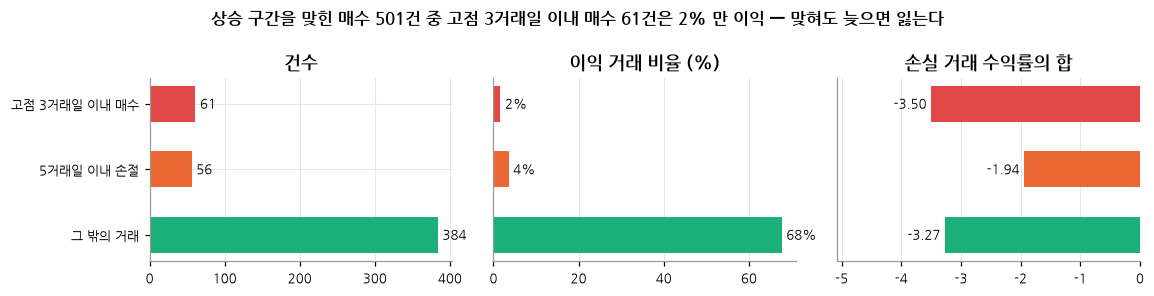

In [22]:
# 그림 7-1: 상승 구간 안에서 산 거래의 손실은 어디서 나왔나 — 고점 직전 매수 · 짧은 거래 · 나머지
_d = _dc.reindex(["막차", "휩소(보유 5일 이하)", "나머지"])  # 순서 고정
_d.index = ["고점 3거래일 이내 매수", "5거래일 이내 손절", "그 밖의 거래"]  # 표시 이름
fig, axs = plt.subplots(1, 3, figsize=(10.6, 2.7))  # 세 칸
_cc = [RED, ORANGE, AQUA]  # 색
axs[0].barh(_d.index, _d.n, color=_cc, height=.55)  # 건수
axs[0].set_title("건수")  # 제목
axs[1].barh(_d.index, _d.승률 * 100, color=_cc, height=.55)  # 승률
axs[1].set_title("이익 거래 비율 (%)")  # 제목
axs[2].barh(_d.index, _d.손실합, color=_cc, height=.55)  # 손실 합 (거래 수익률의 합)
axs[2].set_title("손실 거래 수익률의 합")
axs[2].set_xlim(_d.손실합.min() * 1.45, 0)  # 값 글자 자리  # 제목
for ax, col, f_, mul in [(axs[0], "n", "{:.0f}", 1), (axs[1], "승률", "{:.0%}", 100), (axs[2], "손실합", "{:.2f}", 1)]:  # 값 표시
    for y_, v_ in enumerate(_d[col]):  # 행마다
        ax.annotate(f_.format(v_), (v_ * mul, y_), xytext=(3 if v_ >= 0 else -3, 0), textcoords="offset points", ha="left" if v_ >= 0 else "right", va="center", fontsize=8.5)  # 값
    ax.invert_yaxis()  # 위에서 아래로
for ax in axs[1:]:  # 오른쪽 두 칸
    ax.set_yticks([])  # 눈금 숨김
_m = _d.loc["고점 3거래일 이내 매수"]  # 고점 직전 매수
fig.suptitle(f"상승 구간을 맞힌 매수 {int(_d.n.sum())}건 중 고점 3거래일 이내 매수 {int(_m.n)}건은 {_m.승률 * 100:.0f}% 만 이익 — 맞혀도 늦으면 잃는다", fontweight="bold", fontsize=11)  # 결론 제목
savefig(fig, "f7_loss")  # 저장

#### 다. 근거 ② — 맞혀도 늦으면 손실

- 기준 규칙의 실제 거래 중 상승 구간 안에서 산 거래 501건을 셋으로 나눔: 고점 3거래일 이내 매수 · 5거래일 안에 손절된 거래 · 그 밖의 거래
- **고점 3거래일 이내 매수 61건 중 이익 거래는 2%** 에 불과합니다. 5거래일 안에 손절된 56건과 합치면, 상승 구간을 맞힌 거래의 손실 거래 수익률 합의 62%를 차지합니다
- 신고가 돌파는 정의상 고점 근처에서 사는 규칙이므로, 이 비용은 규칙 구조에서 나오는 것입니다

In [23]:
# 동기 섞은 경로 공통 도구 (C2 매도 위치 · C4 막차)
_dates = X["069500"].loc[T0:].index  # 2021+ 공통 날짜
_bars = {}  # 종목별 일봉 비율
for c in ALL:  # 20종마다
    x = X[c]  # 지표 표
    pc = x.Close.shift()  # 전일 종가
    m = x.index >= T0  # 2021+
    _bars[c] = np.c_[(x.Open / pc)[m], (x.High / pc)[m], (x.Low / pc)[m], (x.Close / pc)[m]]  # 비율 배열
def sync_order(rng, block=20):  # 날짜 동기 블록 순서
    n = len(_dates)  # 날짜 수
    st = np.arange(0, n, block)  # 블록 시작
    return np.concatenate([np.arange(a, min(a + block, n)) for a in rng.permutation(st)])  # 블록 순서
def path_panel(order=None):  # 경로 하나의 좌표 · 점수 · 베이스라인 매도 위치
    rows, exits = [], []  # 날짜 행 · 매도 행
    for c in ALL:  # 20종마다
        ra = _bars[c] if order is None else _bars[c][order]  # 순서 적용
        cl = 10000 * np.cumprod(ra[:, 3])  # 새 종가
        pv = np.r_[10000, cl[:-1]]  # 새 전일 종가
        d0 = pd.DataFrame(dict(Open=ra[:, 0] * pv, High=ra[:, 1] * pv, Low=ra[:, 2] * pv, Close=cl, Volume=0.0), index=_dates)  # 일봉
        x = indicators(d0)  # 지표
        zz_ = zigzag(x.Close)  # 지그재그
        lg_ = zz_[zz_.gain >= LEG_MIN]  # 급등 구간
        n = len(x)  # 길이
        tp, kk, dd_ = np.full(n, np.nan), np.full(n, np.nan), np.full(n, np.nan)  # 고점까지 · 고점 뒤 · 낙폭
        pk_all = x.index.get_indexer(lg_.peak)  # 고점 위치
        tr_all = x.index.get_indexer(lg_.trough)  # 저점 위치
        for a, b_ in zip(tr_all, pk_all):  # 구간마다
            tp[a + 1: b_ + 1] = b_ - np.arange(a + 1, b_ + 1)  # 남은 날
            nx = tr_all[tr_all > b_]  # 다음 저점
            e_ = (nx[0] if len(nx) else n - 1)  # 구역 끝
            s_ = np.arange(b_ + 1, e_ + 1)  # 구역 날짜
            kk[s_], dd_[s_] = s_ - b_, cl[s_] / cl[b_] - 1  # 좌표 기록
        r = np.log(cl / pv)  # 로그 수익
        sg = pd.Series(r).ewm(halflife=20).std().shift().values  # 과거 변동성
        z = pd.Series(r / sg).rolling(20).max().values  # 최근 20일 단발 급등 크기
        rows.append(pd.DataFrame(dict(code=c, tp=tp, s=np.maximum(x.DISP.values / 115, x.RSI.values / 70), z=z), index=_dates))  # 날짜 행
        st = baseline_state(x)  # 베이스라인 상태
        lg = simulate(x, onset(st), st, RULES["규칙1"], None, False)[1]  # 매매
        ex_ = x.index.get_indexer(pd.to_datetime(lg[lg.event == "전량 청산"].date)) - 1  # 매도 판단일
        exits.append(pd.DataFrame(dict(tp=tp[ex_], k=kk[ex_], dd=dd_[ex_])))  # 매도 위치
    return pd.concat(rows), pd.concat(exits)  # 반환
def path_stats(order=None):  # 경로 하나의 통계
    d, ex = path_panel(order)  # 패널
    q = d[(d.tp >= 0) & (d.tp <= 20)]  # Y=1 안 고점 전 0–20일
    y = (q.tp <= 3).values  # 막차 여부
    n_ = len(ex)  # 매도 수
    return dict(auc_s=auc(y, q.s.values), auc_z=auc(y, q.z.values), ex_pre=(ex.tp <= 5).sum() / n_, ex_post5=((ex.k >= 1) & (ex.k <= 5)).sum() / n_, ex_post20=((ex.k >= 1) & (ex.k <= 20)).sum() / n_, ex_near=((ex.k >= 1) & (ex.dd >= -.05)).sum() / n_, n=n_)  # 요약
t0 = time.time()  # 시간 측정
_fn = CACHE / "c4_shuffle.parquet"  # 저장 위치
if _fn.exists():  # 이미 있으면
    SH4 = pd.read_parquet(_fn)  # 읽기
else:  # 처음이면
    SH4 = pd.DataFrame([path_stats(sync_order(np.random.default_rng([3, r]))) for r in range(200)])  # 200경로
    SH4.to_parquet(_fn)  # 저장
print(f"섞은 경로 {time.time() - t0:.0f}초")  # 소요 시간
REALP = path_stats()  # 같은 조건의 실제 값 (2021+ 만 잘라 재계산)
NUM3["path_real"] = REALP  # 저장
NUM3["path_null"] = {k: dict(m=SH4[k].mean(), lo=SH4[k].quantile(.025), hi=SH4[k].quantile(.975)) for k in SH4.columns}  # 저장
show(pd.DataFrame(NUM3["path_null"]).T.assign(실제=pd.Series(REALP)).round(3))  # 출력
# 내준 폭: 보유 중 최고가 대비 매도가
_gb = []  # 거래별
for c in ALL:  # 종목마다
    H_, O_, A_, C_ = X[c].High.values, X[c].Open.values, X[c].ATR.values, X[c].Close.values  # 가격 · ATR
    for t in parse(c, sim(c, BLB)[1]):  # 거래마다
        if t["open_end"]:  # 닫힌 거래만
            continue  # 건너뜀
        hi_ = H_[t["entry_i"]: t["exit_i"]].max() if t["exit_i"] > t["entry_i"] else H_[t["entry_i"]]  # 보유 중 최고가
        _gb.append(dict(gb=O_[t["exit_i"]] / hi_ - 1, gb_atr=(hi_ - O_[t["exit_i"]]) / A_[t["exit_i"] - 1], mfe=hi_ / O_[t["entry_i"]] - 1, ret=t["ret"], days=t["exit_i"] - t["entry_i"]))  # 행 추가
_g = pd.DataFrame(_gb)  # 표로
NUM3["C2_give"] = dict(gb=_g.gb.mean(), gb_atr=_g.gb_atr.median(), mfe=_g.mfe.mean(), ret=_g.ret.mean(), days=_g.days.median(), capture=(_g.ret.sum() / _g.mfe.sum()))  # 저장
dump()  # 수치 저장

섞은 경로 0초


,m,하한,상한,실제
auc_s,0.701,0.663,0.734,0.689
auc_z,0.588,0.545,0.633,0.567
ex_pre,0.024,0.013,0.036,0.015
ex_post5,0.230,0.200,0.263,0.219
ex_post20,0.351,0.316,0.398,0.341
ex_near,0.140,0.110,0.182,0.124
n,690.610,652.975,724.025,659.000


In [24]:
# 과열 지표가 고점 직전 매수를 가리는가: 실제 자료의 AUC · 월 블록 구간 · 2017–20 확인
def real_panel(start, end):  # 전체 자료 라벨의 Y=1 패널
    fr = []  # 종목별
    for c in ALL:  # 종목마다
        x = X[c]  # 지표 표
        d_ = coords(c)  # 좌표
        r = np.log(x.Close).diff()  # 로그 수익
        z = (r / r.ewm(halflife=20).std().shift()).rolling(20).max()  # 단발 급등 크기
        f = pd.DataFrame(dict(code=c, tp=d_.to_peak.values, s=np.maximum(x.DISP / 115, x.RSI / 70).values, z=z.values), index=x.index)  # 표
        fr.append(f.loc[start:end])  # 기간
    q = pd.concat(fr)  # 합치기
    return q[(q.tp >= 0) & (q.tp <= 20)].dropna(subset=["s"])  # 고점 전 0–20일
QN = real_panel("2021-01-01", None)  # 2021+
QO = real_panel("2017-01-01", "2020-12-31")  # 2017–20
A_new, A_old, Az_new = auc((QN.tp <= 3).values, QN.s.values), auc((QO.tp <= 3).values, QO.s.values), auc((QN.tp <= 3).values, QN.z.values)  # AUC
_mon = QN.index.to_period("M")  # 월
_gi = [np.where(_mon == k)[0] for k in _mon.unique()]  # 월별 위치
_rg = np.random.default_rng(0)  # 난수
_y4, _s4 = (QN.tp <= 3).values, QN.s.values  # 배열
_ba = []  # 재표집 값
for _ in range(1000):  # 1000회
    ii = np.concatenate([_gi[p] for p in _rg.integers(0, len(_gi), len(_gi))])  # 월 복원 추출
    if _y4[ii].sum() > 0:  # 양성이 있으면
        _ba.append(auc(_y4[ii], _s4[ii]))  # AUC
_ba = np.array(_ba)  # 배열
_med, _hi = SH4.auc_s.median(), SH4.auc_s.quantile(.975)  # 섞기 중앙값 · 상한
_p4 = float((SH4.auc_s >= REALP["auc_s"]).mean() * 1 + 1 / len(SH4))  # 섞기 기준 단측 p (보수)
NUM3["C4"] = dict(auc=A_new, auc_trunc=REALP["auc_s"], auc_old=A_old, lo=np.percentile(_ba, 2.5), hi=np.percentile(_ba, 97.5), sh_med=_med, sh_lo=SH4.auc_s.quantile(.025), sh_hi=_hi, p=min(1, _p4), n_pos=int(_y4.sum()), n_neg=int((~_y4).sum()), z_auc=Az_new, z_trunc=REALP["auc_z"], z_med=SH4.auc_z.median(), z_lo=SH4.auc_z.quantile(.025), z_hi=SH4.auc_z.quantile(.975))  # 저장
# 체결 신호일 기준 해당 건수
_hot, _nsig, _lc, _hl = 0, 0, 0, 0  # 과열 · 신호 · 막차 · 과열 ∩ 막차
for c in ALL:  # 종목마다
    d_ = coords(c)  # 좌표
    x = X[c]  # 지표 표
    for i in fired(c, sim(c, BLB)[1]):  # 체결 신호마다
        _nsig += 1  # 신호 수
        h_ = x.RSI.values[i] >= 70 or x.DISP.values[i] >= 115  # 과열 여부
        l_ = d_.Y.values[i] == 1 and d_.to_peak.values[i] <= 3  # 막차 여부
        _hot, _lc, _hl = _hot + h_, _lc + l_, _hl + (h_ and l_)  # 누적
NUM3["C4_sig"] = dict(n=_nsig, hot=int(_hot), last=int(_lc), both=int(_hl))  # 저장
dump()  # 수치 저장

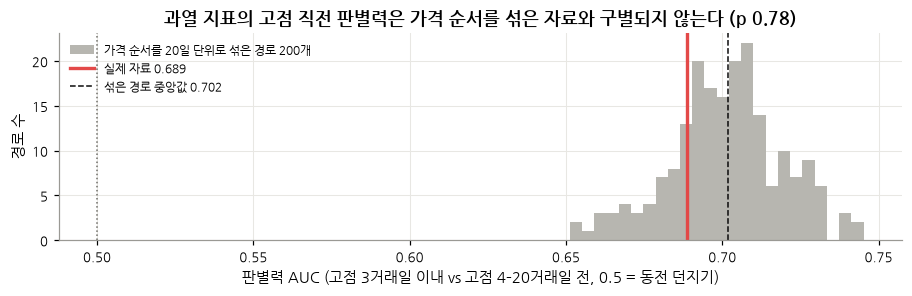

In [25]:
# 그림 7-2: 과열 지표(이격도 · RSI)로 고점 직전 매수를 가릴 수 있나 — 실제 자료 vs 가격 순서를 섞은 자료
_c = NUM3["C4"]  # 결과
fig, ax = plt.subplots(figsize=(8.4, 2.8))  # 그림 틀
ax.hist(SH4.auc_s, bins=24, color=GRAY, label="가격 순서를 20일 단위로 섞은 경로 200개")  # 대조 분포
ax.axvline(_c["auc_trunc"], color=RED, lw=2.2, label=f"실제 자료 {_c['auc_trunc']:.3f}")  # 실제
ax.axvline(_c["sh_med"], color=INK, lw=1, ls="--", label=f"섞은 경로 중앙값 {_c['sh_med']:.3f}")  # 중앙값
ax.axvline(.5, color=MUTED, lw=1, ls=":")  # 무작위
ax.set_xlabel("판별력 AUC (고점 3거래일 이내 vs 고점 4–20거래일 전, 0.5 = 동전 던지기)")  # 축 이름
ax.set_ylabel("경로 수")  # 축 이름
ax.legend(loc="upper left", fontsize=8)  # 범례
ax.set_title(f"과열 지표의 고점 직전 판별력은 가격 순서를 섞은 자료와 구별되지 않는다 (p {_c['p']:.2f})")  # 결론 제목
savefig(fig, "f7_overheat")  # 저장

#### 라. 근거 ③ — 그날의 과열 지표로는 가려지지 않습니다

- 이격도(20일선 대비 115%) 또는 RSI(70) 이상을 과열로 보면, 기준 규칙의 실제 매수 674건 중 고점 3거래일 이내 매수 61건 가운데 **과열에 걸린 것은 6건(10%)** 뿐입니다
- 거꾸로 과열 신호 26건 가운데 고점 직전 매수는 6건(23%)으로 전체 비율(9%)의 약 2.5배입니다. 정밀도는 있으나 놓치는 비율이 90%여서 필터로 쓰기는 어렵습니다
- 과열 점수가 '고점 3거래일 이내'와 '고점 4~20거래일 전'을 가리는 판별력(AUC 0.689)은 가격 순서를 섞은 가상 경로(중앙값 0.702)와 구별되지 않음(p 0.78). 이 정도 판별력은 시장의 성질이 아니라 정의에서 나오는 기계적 결과입니다

### 6.3 매도 규칙을 바꾸는 방안

> **확인한 것** 대안 4종 모두 현행(20일선 또는 3 ATR 이탈)보다 낫다는 근거가 없어 현행 규칙을 유지합니다. → **질의 4: 청산 기준**

#### 가. 검토 내용

매수(20일 신고가 돌파)는 그대로 두고 매도만 바꿉니다

| 매도 규칙 | 내용 |
|---|---|
| **현행** | 종가 < 20일 이동평균, 또는 종가 < 보유 중 최고가 − 3 ATR |
| 3 ATR 이탈만 | 20일선 매도를 빼고 추적 손절만 적용 |
| 60일선 | 20일선 대신 60일 이동평균 |
| 20일선 이틀 확인 | 이틀 연속 20일선 아래일 때만 매도 |
| ±2 ATR · 20일 | 익절 · 손절 · 보유기한 고정 |

- 판단 기준은 **샤프 비율의 차이**이며, 2026년(급등장)을 빼도, 2018~20년을 따로 봐도 같은 방향이어야 우위로 봅니다
- 실제 매도 시점이 **같은 보유 기간 분포로 무작위로 판 경우**보다 나은지도 확인합니다

In [26]:
# 청산 비교
MODES = {"기본 청산(20일선·3ATR)": "ma_atr", "20일선 제거": "atr_only", "60일선 (관찰)": "ma60", "이틀 확인 (관찰)": "ma_2d", "장벽 ±2ATR 20일 (관찰)": "barrier"}  # 비교할 매도 규칙
CVS, rows = {}, []  # 곡선 · 결과
for nm, md_ in MODES.items():  # 청산마다
    lg = bl_lg(mode=md_)  # 사건표
    cv = curves_of(lg)  # 곡선
    CVS[nm] = fam_sleeve(cv)  # 대표 묶음
    ex_ = []  # 노출
    tr_all = []  # 거래
    for c in ALL:  # 종목마다
        p_ = pd.Series(0.0, index=X[c].index)  # 보유 표시
        d_ = coords(c)  # 좌표
        for t in parse(c, lg[c], 10):  # 거래마다
            p_.iloc[t["entry_i"]: t["exit_i"] + 1] = 1.0  # 보유일
            if not t["open_end"]:  # 닫힌 거래면
                s_ = d_.iloc[t["sig_i"]]  # 신호일 좌표
                tr_all.append(dict(ret=t["ret"], Y=s_.Y, tp=s_.to_peak, k=s_.k, dd=s_.dd))  # 행 추가
        ex_.append(p_.loc[T0:].mean())  # 평균
    tt = pd.DataFrame(tr_all)  # 거래표
    sets_ = sets_of(cv)  # 네 묶음
    rows.append(dict(청산=nm, 거래=len(tt), 노출=np.mean(ex_), 막차=tt[(tt.Y == 1) & (tt.tp <= 3)].ret.mean(), 고점전4_20=tt[(tt.Y == 1) & tt.tp.between(4, 20)].ret.mean(), P1=tt[(tt.k <= 10) & (tt.dd > -.03) & (tt.Y == 0)].ret.mean(), 막차손실합=tt[(tt.Y == 1) & (tt.tp <= 3)].ret.clip(upper=0).sum(), 평균수익=tt.ret.mean(), 묶음20_1N=sets_["20종 1/N"].iloc[-1] - 1, 묶음5_균등=sets_["5종 계열 균등"].iloc[-1] - 1, **stats(CVS[nm])))  # 행 추가
T3 = pd.DataFrame(rows)  # 표로
T3.to_csv(RES / "c3_exits.csv", index=False, encoding="utf-8-sig")  # 저장
show(T3.round(3))  # 출력
_keys = list(MODES)  # 청산 이름
_D = pd.concat({k: rets(CVS[k]) for k in _keys}, axis=1)  # 일별 수익
_i1, _i0 = _keys.index("20일선 제거"), _keys.index("기본 청산(20일선·3ATR)")  # 위치
_dsr = lambda a: sr_(a[:, _i1]) - sr_(a[:, _i0])  # ΔSR
_bs3 = qboot(_D, _dsr)  # 재표집
def es21_d(a):  # ES21 차 (20일선 제거 − 기본 청산(20일선·3ATR))
    def es(r):  # 21일 겹침 수익 하위 5% 평균
        q_ = pd.Series(1 + r).cumprod().pct_change(21).dropna()  # 21일 수익
        return q_[q_ <= q_.quantile(.05)].mean()  # 꼬리 평균
    return es(a[:, _i1]) - es(a[:, _i0])  # 차
_es = qboot(_D, es21_d, B=500)  # ES21 재표집
_x26_ = _D[_D.index.year < 2026]  # 2026 제외
_dsr_x = _dsr(_x26_.values)  # 2026 제외 ΔSR
_o0 = {m: fam_sleeve(curves_of(bl_lg(_st, _en, m, _cod), _st, _en)) for m in ["ma_atr", "atr_only"]}  # 2018–20
_dsr_old = stats(_o0["atr_only"])["sr"] - stats(_o0["ma_atr"])["sr"]  # 2018–20 ΔSR
# 최대 통계: 관찰 행을 고를 수 있는지
def _maxs(a):  # 기본 청산(20일선·3ATR) 대비 ΔSR 전부
    return sr_(a) - sr_(a[:, [_i0]])  # 차
_real = _maxs(_D.values)  # 실제
_bm = qboot(_D, _maxs, B=1000)  # 재표집
_pmax = float((((_bm - _real)).max(axis=1) >= _real.max()).mean())  # 보정 p
NUM3["C3"] = dict(d=_dsr(_D.values), lo=np.percentile(_bs3, 2.5), hi=np.percentile(_bs3, 97.5), p=pv2(_bs3), se=_bs3.std(), mde=3.34 * _bs3.std(), d_ex26=_dsr_x, d_old=_dsr_old, old_n=len(_cod), old=dict(base=stats(_o0["ma_atr"]), alt=stats(_o0["atr_only"])), es_d=es21_d(_D.values), es_lo=np.percentile(_es, 2.5), es_hi=np.percentile(_es, 97.5), pmax=_pmax, real={k: v for k, v in zip(_keys, _real)}, rows=rows)  # 저장
dump()  # 수치 저장

,매도 규칙,거래 수,평균 노출,고점직전 매수,고점4~20일전 매수 평균,고점직후10일 매수 평균,고점직전 손실합,건당 평균수익,20종 동일비중 수익,5종 지수군균등 수익,누적수익,최대낙폭,샤프,연변동성,최악5% 21일수익
0,기본 청산(20일선·3ATR),673,0.381,-0.057,0.022,NaN,-3.499,0.016,0.623,0.451,0.619,-0.116,0.941,0.095,-0.036
1,20일선 제거,531,0.462,-0.079,0.015,NaN,-3.239,0.019,0.573,0.254,0.603,-0.127,0.829,0.108,-0.043
2,60일선 (관찰),769,0.396,-0.056,0.008,NaN,-3.661,0.011,0.439,0.211,0.451,-0.154,0.725,0.097,-0.040
3,이틀 확인 (관찰),618,0.414,-0.064,0.019,NaN,-3.648,0.018,0.622,0.371,0.638,-0.127,0.922,0.100,-0.037
4,장벽 ±2ATR 20일 (관찰),932,0.341,-0.054,0.030,NaN,-6.698,0.006,0.309,0.269,0.286,-0.102,0.658,0.072,-0.036


In [27]:
# 청산 시점 무작위화: 같은 종목 실제 보유일을 복원 추출 (시가 체결 계산)
_rng = np.random.default_rng(0)  # 난수
DREAL = {}  # 종목별 일별 초과
_ex = []  # 노출 기록
for c in ALL:  # 종목마다
    x = X[c]  # 지표 표
    tr = parse(c, sim(c, BLB)[1])  # 거래
    n = len(x)  # 길이
    O_, C_ = x.Open.values, x.Close.values  # 가격
    r_cc = np.r_[0, C_[1:] / C_[:-1] - 1]  # 종가→종가
    r_oc = C_ / O_ - 1  # 체결일 시가→종가
    r_co = np.r_[0, O_[1:] / C_[:-1] - 1]  # 매도일 전일 종가→시가
    ent = np.array([t["entry_i"] for t in tr])  # 진입 위치
    ln_ = np.array([t["exit_i"] - t["entry_i"] for t in tr])  # 보유 길이
    opn = np.array([t["open_end"] for t in tr])  # 미청산 여부
    nxt = np.r_[ent[1:], n - 1]  # 다음 진입 위치
    def path(lens):  # 보유 길이 → 일별 수익 · 포지션
        a_, p_ = np.zeros(n), np.zeros(n)  # 수익 · 포지션
        for e_, l_, m_, o_ in zip(ent, lens, nxt, opn):  # 거래마다
            x_ = min(e_ + l_, m_)  # 매도 체결일 (다음 진입 전까지)
            a_[e_] += r_oc[e_]  # 체결일
            a_[e_ + 1: x_] += r_cc[e_ + 1: x_]  # 보유일
            if x_ > e_ and not (o_ and x_ == n - 1):  # 청산이 있으면
                a_[x_] += r_co[x_]  # 매도일 전일 종가→시가
            p_[e_: x_] = 1  # 포지션
        return a_, p_  # 반환
    ar, pr_ = path(ln_)  # 실제
    closed = ln_[~opn]  # 닫힌 거래의 길이
    am, pm = np.zeros(n), np.zeros(n)  # 무작위 평균
    for _ in range(500):  # 500회
        a2, p2 = path(_rng.choice(closed, len(ent)))  # 복원 추출
        am, pm = am + a2 / 500, pm + p2 / 500  # 누적
    mk = x.index >= T0  # 평가 구간
    gap = (pr_ - pm)[mk]  # 노출 차
    DREAL[c] = pd.Series((ar - am)[mk] - gap.mean() * r_cc[mk].mean(), index=x.index[mk])  # 노출 중립
    _ex.append((pr_[mk].mean(), pm[mk].mean()))  # 노출 기록
_df = pd.DataFrame(DREAL)  # 종목별
_fam = _df.T.groupby([FAMILY[c] for c in _df.columns]).mean().T.mean(axis=1).to_frame("d")  # 계열 균등
_ann = lambda a: 252 * a[:, 0].mean()  # 연율
_bs2 = qboot(_fam, _ann)  # 재표집
NUM3["C2"] = dict(d=_ann(_fam.values), lo=np.percentile(_bs2, 2.5), hi=np.percentile(_bs2, 97.5), p=pv2(_bs2), se=_bs2.std(), mde=3.34 * _bs2.std(), d_ex26=_ann(_fam[_fam.index.year < 2026].values), expo_real=np.mean([a for a, _ in _ex]), expo_rand=np.mean([b for _, b in _ex]))  # 저장
# 매도 뒤 20일: 실제 매도일 vs 같은 거래 보유일 중 임의의 날
_rows = []  # 거래별
_rng = np.random.default_rng(1)  # 난수
for c in ALL:  # 종목마다
    O_, C_ = X[c].Open.values, X[c].Close.values  # 가격
    ix = X[c].index  # 날짜
    for t in parse(c, sim(c, BLB)[1]):  # 거래마다
        if t["open_end"] or t["exit_i"] + 20 >= len(C_) or t["exit_i"] - t["entry_i"] < 1:  # 끝난 거래만
            continue  # 건너뜀
        x_ = t["exit_i"]  # 매도 체결일
        us = np.arange(t["entry_i"], x_)  # 보유일
        a = np.log(C_[x_ + 20] / O_[x_])  # 실제 매도 뒤 20일
        b_ = np.mean(np.log(C_[us + 21] / O_[us + 1]))  # 임의 매도일 평균
        _cd = coords(c).iloc[x_ - 1]  # 매도 판단일 좌표
        _rows.append(dict(code=c, month=ix[x_].to_period("M"), real=a, rand=b_, days=x_ - t["entry_i"], post5=(_cd.k >= 1) and (_cd.k <= 5)))  # 행 추가
_e = pd.DataFrame(_rows)  # 표로
_gm = _e.groupby("month").agg(real=("real", "sum"), rand=("rand", "sum"), n=("real", "size"))  # 월 묶음
_rg = np.random.default_rng(0)  # 난수
_idx = _rg.integers(0, len(_gm), (2000, len(_gm)))  # 월 복원 추출
_ds = (_gm.real.values[_idx].sum(1) - _gm.rand.values[_idx].sum(1)) / _gm.n.values[_idx].sum(1)  # 재표집 차
NUM3["C2_after"] = dict(n=len(_e), real=_e.real.mean(), rand=_e.rand.mean(), d=_e.real.mean() - _e.rand.mean(), lo=np.percentile(_ds, 2.5), hi=np.percentile(_ds, 97.5), up=(_e.real > 0).mean(), n5=int(_e.post5.sum()), real5=_e[_e.post5].real.mean(), up5=(_e[_e.post5].real > 0).mean(), real_o=_e[~_e.post5].real.mean(), uncond=float(np.mean([np.log(X[c].Close.shift(-20) / X[c].Close).loc[T0:].mean() for c in ALL])))  # 저장

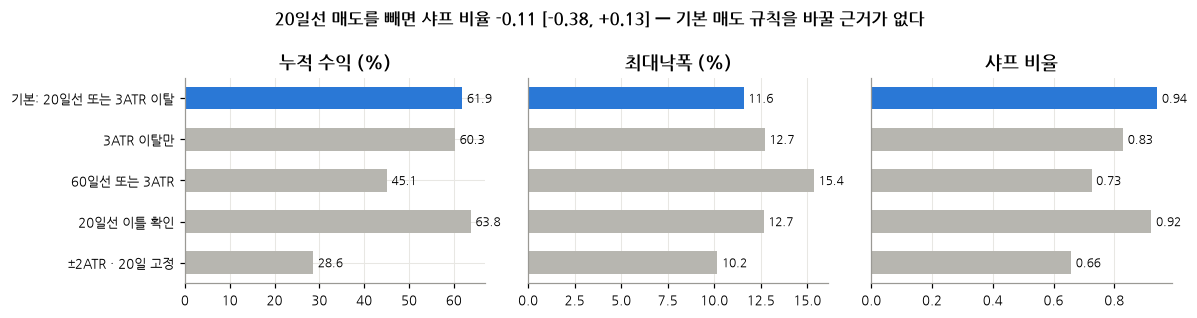

In [28]:
# 그림 8-1: 매도 규칙 비교 (신고가 돌파 매수는 같고 매도만 바꿈 · 20종 계열 균등 · 시가 체결 · 편도 0.1%)
_e = T3.set_index("청산")  # 결과
_nm = {"기본 청산(20일선·3ATR)": "기본: 20일선 또는 3ATR 이탈", "20일선 제거": "3ATR 이탈만", "60일선 (관찰)": "60일선 또는 3ATR", "이틀 확인 (관찰)": "20일선 이틀 확인", "장벽 ±2ATR 20일 (관찰)": "±2ATR · 20일 고정"}  # 표시 이름
_e = _e.rename(index=_nm)  # 이름 바꿈
fig, axs = plt.subplots(1, 3, figsize=(11, 2.9))  # 세 칸
_cc = [BLUE] + [GRAY] * (len(_e) - 1)  # 기본만 강조
for ax, col, tt, mul in [(axs[0], "ret", "누적 수익 (%)", 100), (axs[1], "mdd", "최대낙폭 (%)", -100), (axs[2], "sr", "샤프 비율", 1)]:  # 지표마다
    ax.barh(_e.index, _e[col] * mul, color=_cc, height=.55)  # 막대
    for y_, v_ in enumerate(_e[col] * mul):  # 값 표시
        ax.annotate(f"{v_:.2f}" if col == "sr" else f"{v_:.1f}", (v_, y_), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)  # 값
    ax.invert_yaxis()  # 위에서 아래로
    ax.set_title(tt)  # 제목
for ax in axs[1:]:  # 오른쪽 두 칸
    ax.set_yticks([])  # 눈금 숨김
_c3 = NUM3["C3"]  # 검정
fig.suptitle(f"20일선 매도를 빼면 샤프 비율 {_c3['d']:+.2f} [{_c3['lo']:+.2f}, {_c3['hi']:+.2f}] — 기본 매도 규칙을 바꿀 근거가 없다", fontweight="bold", fontsize=11)  # 결론 제목
savefig(fig, "f8_exits")  # 저장

#### 나. 근거

- 20일선 매도를 빼면 샤프 비율이 −0.11 [−0.38, +0.13] 로 낮아지며, 2026년 제외(−0.26) · 2018~20년(−0.15)에서도 같은 방향입니다. 수익은 20종 +61.9% → +60.3% (핵심 5종 지수군 동일 비중 +45.1% → +25.4%)
- 나머지 대안 셋도 현행보다 낫다고 볼 근거가 없습니다 (다중비교 보정 후)
- 실제 매도 시점은 같은 보유 기간으로 무작위로 판 경우보다 연 +3.1%p 앞서나 통계적으로 유의하지 않습니다
- 매도 뒤 20거래일 수익은 평균 −0.20%로, 같은 거래의 임의 보유일에 판 경우(−1.19%)보다 1.0%p 높고(유의) 무조건 평균(+0.61%)보다는 낮습니다 → 매도가 다소 이른 편일 가능성은 있으나, 대체로 '팔고 나서 크게 오르는' 매도는 아니었습니다

### 6.4 재진입 조건을 바꾸는 방안

> **확인한 것** 20일선 회복 재진입은 휩소가 41%로 많아, 20일 신고가 재진입(5%)을 유지합니다. → **질의 4: 재진입 기준**

#### 가. 검토 내용

- 모델이 상승 구간으로 판단하는 중에 매도 규칙으로 팔았을 때의 재진입 조건 세 가지를 비교함: 재진입 없음 · 20일선 회복 시 · 20일 신고가 돌파 시 (모두 종가 판단 · 다음 날 시가 체결)
- 모든 재진입이 판단일 다음 날 체결되었는지, 자료를 중간에 잘라도 과거 매매 기록이 같은지 먼저 검증합니다
- 신호 당일 시가로 **소급 체결**하는 시나리오도 계산해, 체결 시점 오류가 수익을 얼마나 부풀리는지 확인합니다

In [29]:
# (a) 코드 감사
same_day, total, bad_cut = 0, 0, 0  # 위반 수 · 재매수 수 · 절단 불일치 수
for u, (codes, bd) in BOARDS.items():  # 묶음마다
    for nm, b in bd.items():  # 판마다
        if b[2] is None:  # 재매수 없는 판은
            continue  # 건너뜀
        for c in codes:  # 종목마다
            lg = sim(c, b)[1]  # 사건 기록
            idx = X[c].index  # 날짜
            ev = lg.reset_index(drop=True)  # 번호 재설정
            for j in ev.index[ev.event == "재매수"]:  # 재매수마다
                total += 1  # 셈
                fill = idx.get_loc(ev.date[j])  # 체결일 위치
                prev_exit = idx.get_loc(ev.date[j - 1]) if j else -1  # 직전 사건일 위치
                same_day += int(fill <= prev_exit)  # 직전 청산 체결일 이전이나 같은 날이면 위반
                st = b[0]["state"][c].reindex(idx).fillna(0).values[fill - 1]  # 판단일(체결 전날) 상태
                same_day += int(not st)  # 판단일 상태가 꺼져 있으면 위반
                same_day += int(not (X[c].Close.values[fill - 1] > X[c].HI.values[fill - 1]))  # 판단일 종가가 HI20 을 못 넘었으면 위반

check(same_day == 0 and total > 0, f"재진입 체결 시점 점검: {total}건 모두 판단일(종가) 다음 날 시가 체결 · 위반 {same_day}건")  # 사전 판정

for cut in ["2023-06-30", "2025-01-02"]:  # 절단일마다
    for c in S1:  # 5종마다
        b = BOARDS["5종"][1]["베이스라인·규칙1"]  # 베이스라인 판
        lg_full = sim(c, b)[1]  # 전체 자료 사건
        x_cut = indicators(get(c).loc[:cut])  # 자른 자료의 지표
        st_cut = baseline_state(x_cut)  # 자른 자료의 상태
        lv2, lg2 = simulate(x_cut, onset(st_cut) & (x_cut.index >= T0), st_cut * (x_cut.index >= T0), RULES["규칙1"], None, False)  # 자른 자료로 매매
        a1 = lg_full[lg_full.date <= cut].reset_index(drop=True)  # 전체 자료의 같은 기간 사건
        a2 = lg2[lg2.date <= cut].reset_index(drop=True)  # 자른 자료의 사건
        bad_cut += int(not a1[["date", "event"]].equals(a2[["date", "event"]]))  # 다르면 셈

check(bad_cut == 0, f"미래 정보 미사용 점검: 자료를 두 시점에서 잘라도 과거 매매 동일 (불일치 {bad_cut})")  # 사전 판정



# (b) · (c) 재매수 조건 비교와 위반판
rows = []  # 결과 행
for u, mn in [("5종", "GBM단독"), ("5종", "GBM합동"), ("20종", "GBM단독"), ("20종", "GBM합동"), ("5종", "베이스라인"), ("20종", "베이스라인")]:  # 묶음 · 모델마다
    codes, m = UNIV[u], MODELS[u][mn]  # 대상 · 모델
    for rb, sb, tag in [(None, False, "없음"), ("MA20", False, "MA20"), ("HI20", False, "HI20"), ("MA20", True, "MA20 위반판"), ("HI20", True, "HI20 위반판")]:  # 조건마다
        lgs = {c: sim(c, (m, "규칙1", rb, False), same_bar=sb)[1] for c in codes}  # 매매
        cv = sleeve([equity_fill(X[c], lgs[c], T0, None, 10) for c in codes])  # 시가 체결 기준 곡선
        nb, fast, cash = 0, 0, []  # 재매수 수 · 2일 내 재청산 수 · 보유 비중
        for c in codes:  # 종목마다
            e = lgs[c]  # 사건
            ix = X[c].index  # 날짜
            ex = ix.get_indexer(pd.to_datetime(e[e.event == "전량 청산"].date))  # 청산 위치
            rbs = ix.get_indexer(pd.to_datetime(e[e.event == "재매수"].date))  # 재매수 위치
            nb += len(rbs)  # 누적
            fast += sum(((ex > r) & (ex <= r + 2)).any() for r in rbs)  # 2거래일 안 재청산
        rows.append(dict(묶음=u, 모델=mn, 재매수=tag, 수익=cv.iloc[-1] - 1, MDD=mdd(cv), 재매수수=nb, 두일내재청산=fast, 진입=sum(int((lgs[c].event == "진입").sum()) for c in codes)))  # 행 추가

X2 = pd.DataFrame(rows)  # 표로
X2.to_csv(RES / "x2_rebuy.csv", index=False, encoding="utf-8-sig")  # 저장
show(X2.round(3))  # 출력

NUM2["X2"] = {f"{r.묶음}|{r.모델}|{r.재매수}": dict(ret=r.수익, mdd=r.MDD, nb=r.재매수수, fast=r.두일내재청산, n=r.진입) for r in X2.itertuples()}  # PDF 용 저장
NUM2["X2_audit"] = dict(total=total, viol=same_day, cut_bad=bad_cut)  # 저장

# HI20 − MA20 짝 차이와 분기 묶음 구간
rows = []  # 결과 행
for u, mn in [("5종", "GBM단독"), ("5종", "GBM합동"), ("20종", "GBM단독"), ("20종", "GBM합동")]:  # GBM 네 판
    cv_ = {rb: fill_curve(UNIV[u], (MODELS[u][mn], "규칙1", rb, False)) for rb in ["MA20", "HI20", None]}  # 세 조건 곡선
    r1, r2 = paired_ci(cv_["HI20"], cv_["MA20"]), paired_ci(cv_["HI20"], cv_[None])  # 두 비교
    rows.append(dict(묶음=u, 모델=mn, HI_MA=r1["d"], HI_MA_lo=r1["lo"], HI_MA_hi=r1["hi"], HI_없음=r2["d"], HI_없음_lo=r2["lo"], HI_없음_hi=r2["hi"]))  # 행 추가

X2P = pd.DataFrame(rows)  # 표로
X2P.to_csv(RES / "x2_paired.csv", index=False, encoding="utf-8-sig")  # 저장
show(X2P.round(3))  # 출력

NUM2["X2_paired"] = {f"{r.묶음}|{r.모델}": dict(d=r.HI_MA, lo=r.HI_MA_lo, hi=r.HI_MA_hi, d0=r.HI_없음, lo0=r.HI_없음_lo, hi0=r.HI_없음_hi) for r in X2P.itertuples()}  # 저장


# 베이스라인과 GBM 은 진입이 같은가
rows = []  # 겹침 행
for u in UNIV:  # 묶음마다
    for mn in ["GBM단독", "GBM합동"]:  # 모델마다
        a, b_ = 0, 0  # 교집합 · 합집합
        for c in UNIV[u]:  # 종목마다
            e1 = BL["entry"][c].reindex(X[c].index).fillna(False).values & (X[c].index >= T0)  # 베이스라인 신호일
            e2 = MODELS[u][mn]["entry"][c].reindex(X[c].index).fillna(False).values & (X[c].index >= T0)  # GBM 신호일
            a += int((e1 & e2).sum())  # 같은 날 신호
            b_ += int((e1 | e2).sum())  # 어느 한쪽 신호
        rows.append(dict(묶음=u, 모델=mn, 같은날=a, 합집합=b_, 자카드=a / b_))  # 행 추가
XJ = pd.DataFrame(rows)  # 표로
show(XJ.round(3))  # 출력
NUM2["X2_jaccard"] = {f"{r.묶음}|{r.모델}": dict(same=r.같은날, union=r.합집합, j=r.자카드) for r in XJ.itertuples()}  # 저장
dump()  # 수치 저장

✔ 재진입 체결 시점 점검: 1030건 모두 판단일(종가) 다음 날 시가 체결 · 위반 0건
✔ 미래 정보 미사용 점검: 자료를 두 시점에서 잘라도 과거 매매 동일 (불일치 0)


,종목군,모델,재진입 조건,수익,MDD,재진입 건수,2거래일내 재청산,매수 건수
0,5종,GBM(종목별),재진입 없음,-0.165,-0.215,0,0,198
1,5종,GBM(종목별),20일선재진입,0.374,-0.391,151,66,183
2,5종,GBM(종목별),신고가재진입,0.454,-0.296,52,1,191
3,5종,GBM(종목별),20일선재진입·당일시가소급,1.007,-0.325,151,49,183
4,5종,GBM(종목별),신고가재진입·당일시가소급,0.718,-0.280,52,0,191
5,5종,GBM(통합),재진입 없음,0.127,-0.230,0,0,191
6,5종,GBM(통합),20일선재진입,0.579,-0.260,110,42,180
7,5종,GBM(통합),신고가재진입,0.545,-0.236,47,3,185
8,5종,GBM(통합),20일선재진입·당일시가소급,1.153,-0.216,110,27,180
9,5종,GBM(통합),신고가재진입·당일시가소급,0.754,-0.234,47,0,185


,종목군,모델,신고가−20일선,하한,상한,신고가−재진입없음,하한,상한
0,5종,GBM(종목별),0.081,-0.180,0.353,0.620,0.035,2.209
1,5종,GBM(통합),-0.034,-0.305,0.135,0.419,-0.144,1.764
2,20종,GBM(종목별),0.103,-0.078,0.257,0.316,-0.055,1.179
3,20종,GBM(통합),0.038,-0.146,0.189,0.225,-0.043,0.851


,종목군,모델,같은날 신호,어느한쪽 신호,신호일 중복률
0,5종,GBM(종목별),55,681,0.081
1,5종,GBM(통합),38,669,0.057
2,20종,GBM(종목별),199,2843,0.070
3,20종,GBM(통합),162,2655,0.061


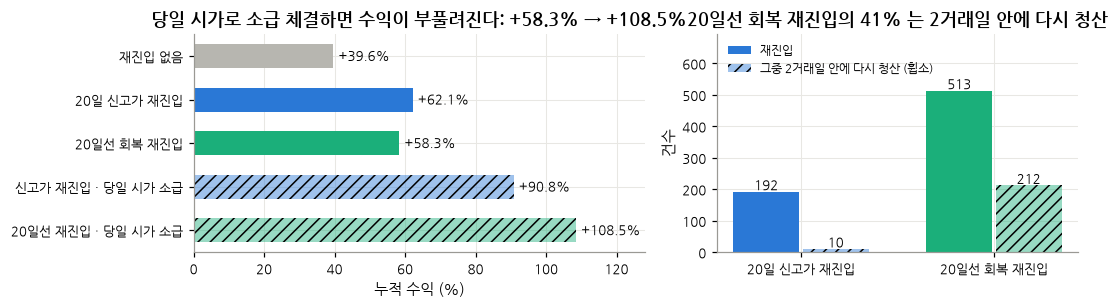

In [30]:
# 그림 9-1: 재진입 조건과 체결 시점 (전체 20종 · GBM 통합 학습 · 전량 청산 규칙 · 시가 체결 · 편도 0.1%)
_g = X2[(X2.묶음 == "20종") & (X2.모델 == "GBM합동")].set_index("재매수").reindex(["없음", "HI20", "MA20", "HI20 위반판", "MA20 위반판"])  # 다섯 판
fig, axs = plt.subplots(1, 2, figsize=(10, 2.9), gridspec_kw=dict(width_ratios=[1.25, 1]))  # 두 칸
_cl = [GRAY, BLUE, AQUA, BLUE, AQUA]  # 조건별 색 (위반판은 같은 색 · 빗금)
_br = axs[0].barh(["재진입 없음", "20일 신고가 재진입", "20일선 회복 재진입", "신고가 재진입 · 당일 시가 소급", "20일선 재진입 · 당일 시가 소급"], _g.수익 * 100, color=_cl, height=.55)  # 수익
for b_, nm in zip(_br, _g.index):  # 위반판 표시
    if "위반" in nm:  # 위반판이면
        b_.set_alpha(.45)  # 옅게
        b_.set_hatch("///")  # 빗금
for y_, v_ in enumerate(_g.수익):  # 값 표시
    axs[0].annotate(f"{v_ * 100:+.1f}%", (v_ * 100 + 1.5, y_), va="center", fontsize=8.5)  # 값
axs[0].invert_yaxis()  # 위에서 아래로
axs[0].set_xlim(0, _g.수익.max() * 100 * 1.18)  # 값 글자 자리
axs[0].set_xlabel("누적 수익 (%)")  # 축 이름
axs[0].set_title(f"당일 시가로 소급 체결하면 수익이 부풀려진다: {_g.loc['MA20', '수익'] * 100:+.1f}% → {_g.loc['MA20 위반판', '수익'] * 100:+.1f}%")  # 결론 제목
_k = ["HI20", "MA20"]  # 두 조건
_x = np.arange(2)  # 위치
axs[1].bar(_x - .18, _g.loc[_k, "재매수수"], width=.34, color=[BLUE, AQUA], label="재진입")  # 재매수 수
axs[1].bar(_x + .18, _g.loc[_k, "두일내재청산"], width=.34, color=[BLUE, AQUA], alpha=.45, hatch="///", label="그중 2거래일 안에 다시 청산 (휩소)")  # 헛매수
for x_, k_ in zip(_x, _k):  # 값 표시
    axs[1].annotate(f"{_g.loc[k_, '재매수수']:.0f}", (x_ - .18, _g.loc[k_, "재매수수"] + 8), ha="center", fontsize=8.5)  # 값
    axs[1].annotate(f"{_g.loc[k_, '두일내재청산']:.0f}", (x_ + .18, _g.loc[k_, "두일내재청산"] + 8), ha="center", fontsize=8.5)  # 값
axs[1].set_xticks(_x, ["20일 신고가 재진입", "20일선 회복 재진입"])  # 눈금
axs[1].set_ylabel("건수")  # 축 이름
axs[1].set_title(f"20일선 회복 재진입의 {_g.loc['MA20', '두일내재청산'] / _g.loc['MA20', '재매수수'] * 100:.0f}% 는 2거래일 안에 다시 청산")  # 결론 제목
axs[1].legend(loc="upper left", bbox_to_anchor=(0, 1.0), fontsize=7.6)
axs[1].set_ylim(0, _g.loc[_k, "재매수수"].max() * 1.35)  # 범례
savefig(fig, "x2_rebuy")  # 저장

#### 나. 근거 (20개 ETF · GBM 통합 학습 기준)

- (종목 동일 비중) 20일선 회복 재진입은 513건으로 20일 신고가 재진입(192건)의 약 2.7배이며, 그중 41%(212건)가 2거래일 안에 다시 청산되는 휩소입니다. 20일 신고가 재진입의 휩소는 5%(10건)
- 수익은 신고가 재진입(+62.1%)이 20일선 재진입(+58.3%)보다 높으나 통계적으로 유의한 차이는 아닙니다. 휩소가 적어 매매가 안정적이라는 점을 실무 근거로 봅니다
- 같은 조건을 신호 당일 시가로 소급 체결하는 시나리오에서는 수익이 **+58.3% → +108.5%** 로 부풀려집니다 → 백테스트 결과를 검토할 때 체결 시점을 가장 먼저 확인해야 합니다

## 7. 남은 쟁점과 질의 사항

### 7.1 검토 결과 종합

- 핵심 검정 네 개를 다중 검정 보정(Holm)한 결과, 넷 모두 통계적으로 유의하지 않습니다
- 아래 셀은 계산 점검이 하나라도 틀리면 멈춤

In [31]:
# 핵심 검정 네 가지와 다중 검정 보정 (Holm) · 계산 점검
C_ = {"보유 대비 타이밍 가치": NUM3["C1"]["p"], "매도 시점의 가치": NUM3["C2"]["p"], "20일선 매도 제거": NUM3["C3"]["p"], "과열 지표의 판별력": NUM3["C4"]["p"]}  # 원래 p
_ord = sorted(C_, key=C_.get)  # 작은 순
HOLM, _prev = {}, 0  # 보정 p
for i, k in enumerate(_ord):  # 차례로
    _prev = max(_prev, min(1, C_[k] * (len(_ord) - i)))  # Holm 계단
    HOLM[k] = _prev  # 저장
_txt = {"보유 대비 타이밍 가치": f"연 {NUM3['C1']['d'] * 100:+.1f}%p [{NUM3['C1']['lo'] * 100:+.1f}, {NUM3['C1']['hi'] * 100:+.1f}]",
        "매도 시점의 가치": f"연 {NUM3['C2']['d'] * 100:+.1f}%p [{NUM3['C2']['lo'] * 100:+.1f}, {NUM3['C2']['hi'] * 100:+.1f}]",
        "20일선 매도 제거": f"샤프 {NUM3['C3']['d']:+.2f} [{NUM3['C3']['lo']:+.2f}, {NUM3['C3']['hi']:+.2f}]",
        "과열 지표의 판별력": f"AUC {NUM3['C4']['auc_trunc']:.3f} (섞은 자료 중앙값 {NUM3['C4']['sh_med']:.3f})"}  # 효과 크기
VT = pd.DataFrame([dict(검정=k, 효과=_txt[k], p=C_[k], 보정p=HOLM[k], 결론="통계적으로 유의" if HOLM[k] < .05 else "통계적으로 구별되지 않음") for k in C_])  # 표
VT.to_csv(RES / "t_tests.csv", index=False, encoding="utf-8-sig")  # 저장
show(VT.round(3))  # 출력
NUM2["holm"] = HOLM  # 저장
_ok = sum(o for o, _ in CHECKS)  # 통과 수
print(f"계산 점검 {_ok} / {len(CHECKS)} 통과")  # 요약
assert _ok == len(CHECKS), [m for o, m in CHECKS if not o]  # 하나라도 틀리면 멈춤
NUM2["checks"] = [_ok, len(CHECKS)]  # 저장
dump()  # 최종 저장

,검정,효과,p,보정p,결론
0,보유 대비 타이밍 가치,"연 +3.0%p [-1.7, +8.3]",0.238,0.714,통계적으로 구별되지 않음
1,매도 시점의 가치,"연 +3.1%p [-0.7, +7.9]",0.121,0.484,통계적으로 구별되지 않음
2,20일선 매도 제거,"샤프 -0.11 [-0.38, +0.13]",0.347,0.714,통계적으로 구별되지 않음
3,과열 지표의 판별력,AUC 0.689 (섞은 자료 중앙값 0.702),0.780,0.780,통계적으로 구별되지 않음


계산 점검 6 / 6 통과


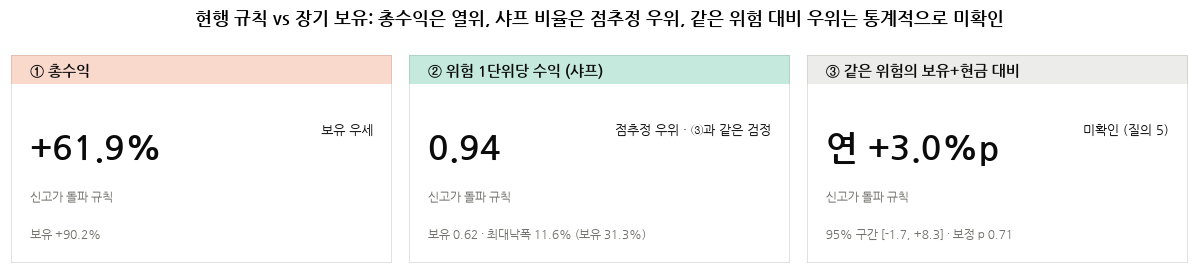

In [32]:
# 그림 10-1: 장기 보유를 이겼는가 — 성적표 세 장
_T = T1[T1.묶음 == PRIM].set_index("전략")  # 대표 묶음 표
_h, _b = _T.loc["보유"], _T.loc["베이스라인"]  # 보유 · 규칙
_c1 = NUM3["C1"]  # 같은 위험 비교
_tiles = [("① 총수익", f"{_b.ret * 100:+.1f}%", f"보유 {_h.ret * 100:+.1f}%", "보유 우세", ORANGE),  # 칸 1
          ("② 위험 1단위당 수익 (샤프)", f"{_b.sr:.2f}", f"보유 {_h.sr:.2f} · 최대낙폭 {-_b.mdd * 100:.1f}% (보유 {-_h.mdd * 100:.1f}%)", "점추정 우위 · ③과 같은 검정", AQUA),  # 칸 2
          ("③ 같은 위험의 보유+현금 대비", f"연 {_c1['d'] * 100:+.1f}%p", f"95% 구간 [{_c1['lo'] * 100:+.1f}, {_c1['hi'] * 100:+.1f}] · 보정 p {HOLM['보유 대비 타이밍 가치']:.2f}", "미확인 (질의 5)", GRAY)]  # 칸 3
fig, axs = plt.subplots(1, 3, figsize=(11, 2.5))  # 세 칸
for ax, (nm, big, sub_, verdict, col) in zip(axs, _tiles):  # 칸마다
    ax.axis("off")  # 축 숨김
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, ec="#d9d8d3", lw=1))  # 테두리
    ax.add_patch(plt.Rectangle((0, .86), 1, .14, transform=ax.transAxes, color=col, alpha=.25, lw=0))  # 머리 띠
    ax.text(.05, .9, nm, transform=ax.transAxes, fontsize=9.5, color=INK, fontweight="bold")  # 항목
    ax.text(.05, .5, big, transform=ax.transAxes, fontsize=22, fontweight="bold", color=INK)  # 규칙 값
    ax.text(.05, .3, "신고가 돌파 규칙", transform=ax.transAxes, fontsize=8, color=MUTED)  # 설명
    ax.text(.05, .12, sub_, transform=ax.transAxes, fontsize=8, color=MUTED)  # 비교
    ax.text(.95, .62, verdict, transform=ax.transAxes, fontsize=8.6, color=INK, ha="right")  # 판정
fig.suptitle("현행 규칙 vs 장기 보유: 총수익은 열위, 샤프 비율은 점추정 우위, 같은 위험 대비 우위는 통계적으로 미확인", fontweight="bold", fontsize=11.5)  # 결론 제목
savefig(fig, "f10_scorecard")  # 저장

### 7.2 정리

| 구분 | 내용 |
|---|---|
| 확인된 사실 | 현행 규칙은 보유 대비 수익 −28.3%p · 최대낙폭 1/3 (대부분 노출 축소 효과). 상승 국면은 모델로 판별되지만(AUC 0.816) 수익 나는 날은 판별되지 않음(AUC 0.515) |
| 현행 유지 | 매도 규칙 · 재진입 조건 · 임계값 0.6 / 0.4 |
| 추가 검증 | 수익 나는 날을 직접 학습한 모델 (건당 수익 지표에서만 우위) |
| **여쭙고 싶은 기준** | **상승 국면 판단 · 매수 시점 · 추격 매수 회피 · 청산과 재진입 · 성과 평가와 검증 기간 · 거래비용** |

### 7.3 질의 사항

| | 저희가 확인한 것 | 여쭙고 싶은 기준 |
|---|---|---|
| 1 | 상승 국면은 사후 정의(10% 반전 · 15% 상승)로 학습했고, 모델은 이를 잘 가립니다(AUC 0.816) (2장 · 6.1) | 실무에서 **상승 국면(추세)을 판단하는 기준** — 지표 · 기간 · 임계값 |
| 2 | 같은 모델이 수익 나는 날은 고르지 못합니다(AUC 0.515) (6.1) | 국면 판단 뒤 **실제 매수 시점을 정하는 기준** |
| 3 | 고점 3거래일 이내 매수 61건 중 이익 거래 2%, 과열 지표로 걸리는 것은 6건 (6.2) | 고점 직전 **추격 매수를 거르는 기준** — 일봉 외 정보 · 운용 원칙 포함 |
| 4 | 매도 대안 4종은 우위 근거가 없고, 20일선 회복 재진입의 휩소는 41% (6.3 · 6.4) | **청산과 재진입의 기준** |
| 5 | 같은 위험 대비 우위(연 +3.0%p)를 5.8년 표본으로는 확인할 수 없음 (5.1) | 전략을 평가하는 **지표**(수익 · 최대낙폭 · 샤프)와 **최소 검증 기간** |
| 6 | 거래비용을 0.3%로 올리면 우위가 +3.0%p → +0.7%p (5.1) | 현실적인 **거래비용 · 슬리피지** 가정 |

### 7.4 참고 — 실무 검토를 요청하는 해석

- 현재 결과로 말할 수 있는 것은 **노출 수준에 따른 수익 · 낙폭의 교환**임: 전부 보유(+90.2% · 최대낙폭 31.3%), 절반 혼합(+76.0% · 23.1%), 전부 규칙(+61.9% · 11.6%), 같은 변동성의 보유+현금(+36.5% · 14.2%)
- 이는 투자 권유가 아니며, 매매 규칙의 실질 가치는 7.3의 기준에 대한 의견을 듣고 판단하고자 합니다

## 8. 한계

- 평가 기간이 5.8년이고 같은 시장을 따르는 ETF가 많아 사실상 독립적인 시장은 몇 개뿐입니다. 연 7~9%p보다 작은 차이는 가려내기 어렵습니다
- 2021년 이후 자료는 연구 과정에서 여러 번 확인했고, 평가 비중(지수군 동일 비중) 등 일부 기준은 같은 기간 자료를 본 뒤 확정했으므로 완전한 표본 외 검증은 아닙니다
- 수정 가격 여부는 대표 종목만 외부 자료와 대조합니다. 보유 수익이 이 가정에 직접 걸려 있습니다
- 상승 구간과 고점 위치는 사후 정보이며 진단에만 사용합니다
- 세전 · 현금 이자 0 · 슬리피지는 편도 0.1% 비용에 포함한 가정입니다

## 붙임 1. 학습 종목 수와 모델 성과

#### 가. 검토 내용

- 핵심 5개 ETF로 학습한 모델의 수익이 대표 2개 ETF(KODEX 200 · KODEX 코스닥150)로 학습한 모델보다 높게 나타났습니다. 학습 종목 증가의 효과인지, 평가 종목 차이의 효과인지 구분합니다
- 평가 종목군을 고정하고 학습 종목군만 바꾸는 비교, 학습을 고정하고 평가 종목군만 바꾸는 비교를 따로 수행합니다. 평가를 고정한 비교의 95% 신뢰구간이 0을 포함하지 않을 때만 학습 효과로 판단합니다

{'069500': 'KODEX 200', '102110': 'TIGER 200', '226490': 'KODEX 코스피', '229200': 'KODEX 코스닥150', '232080': 'TIGER 코스닥150'}


,2종,5종,5종 지수군 동일 비중
학습,,,
2종,0.369,0.413,0.295
5종,0.431,0.545,0.422
KOSPI 3종,0.579,0.700,0.554
단독,0.391,0.454,0.333
단순 보유,0.723,0.839,0.671
신고가돌파,0.489,0.570,0.451


,2종,5종,KOSPI 3종,단독
종목,,,,
KODEX 200,1.031,1.122,1.322,0.974
KODEX 코스닥150,-0.292,-0.260,-0.164,-0.191
KODEX 코스피,0.772,0.847,1.261,0.850
TIGER 200,0.860,1.146,1.268,0.998
TIGER 코스닥150,-0.305,-0.129,-0.189,-0.359


,비교,평가 종목군,학습 종목군,차이,하한,상한,무작위 대비
0,학습 변경,2종,5종 − 2종,0.062,-0.093,0.380,구별 안 됨
1,학습 변경,2종,단독 − 2종,0.022,-0.254,0.533,구별 안 됨
2,학습 변경,2종,단독 − 5종,-0.040,-0.303,0.287,구별 안 됨
3,학습 변경,5종,5종 − 2종,0.132,-0.014,0.419,구별 안 됨
4,학습 변경,5종,단독 − 2종,0.041,-0.172,0.496,구별 안 됨
5,학습 변경,5종,단독 − 5종,-0.091,-0.344,0.275,구별 안 됨
6,학습 변경,5종 지수군 동일 비중,5종 − 2종,0.127,-0.016,0.405,구별 안 됨
7,학습 변경,5종 지수군 동일 비중,단독 − 2종,0.038,-0.166,0.460,구별 안 됨
8,학습 변경,5종 지수군 동일 비중,단독 − 5종,-0.089,-0.331,0.246,구별 안 됨
9,평가 변경,5종 지수군 동일 비중 − 2종,2종,-0.075,-0.217,0.016,구별 안 됨


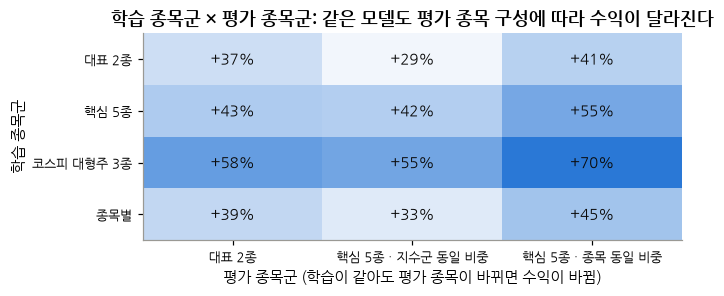

In [33]:
# 학습 × 평가 격자
_K3 = ["069500", "102110", "226490"]  # KOSPI 200 계열 3종

TRAINS = {"2종": S2, "5종": S1, "KOSPI 3종": _K3, "단독": "단독"}  # 학습 묶음

_rc = pd.DataFrame({NAME[c]: X[c].Close.pct_change() for c in S1}).loc[T0:].corr()  # 5종 일간 수익 상관
NUM2["X6_corr"] = dict(k200_tiger=_rc.loc[NAME["069500"], NAME["102110"]] if NAME["102110"] in _rc else None, kosdaq=_rc.loc[NAME["229200"], NAME["232080"]], cross=_rc.loc[NAME["069500"], NAME["229200"]])  # 대표 상관 저장
print({c: NAME[c] for c in S1})  # 종목 확인

def eval_sets(cvs):  # 평가 묶음 세 개의 곡선
    fam = {"코스피대형주지수군": [c for c in S1 if FAMILY[c] == "코스피대형주지수군"], "코스닥150지수군": [c for c in S1 if FAMILY[c] == "코스닥150지수군"]}  # 계열별 종목
    return {"2종": sleeve([cvs[c] for c in S2]), "5종": sleeve([cvs[c] for c in S1]), "5종 계열 균등": sleeve([sleeve([cvs[c] for c in v]) for v in fam.values()])}  # 세 곡선

rows, CV6, PER = [], {}, []  # 결과 · 곡선 · 종목별
for tn, tr_ in TRAINS.items():  # 학습 묶음마다
    pr = pd.concat([gbm_prob([c], [c]) for c in S1]) if tr_ == "단독" else gbm_prob(list(tr_), S1)  # 5종 예측
    m = make_model(pr)  # 모델
    cvs = {c: equity_fill(X[c], sim(c, (m, "규칙1", REBUY, False))[1], T0, None, 10) for c in S1}  # 종목별 곡선
    for c in S1:  # 종목마다
        PER.append(dict(학습=tn, 코드=c, 종목=NAME[c], 계열=FAMILY[c], 수익=cvs[c].iloc[-1] - 1, MDD=mdd(cvs[c]), F1=f1_table([c], m)["F1"]))  # 행 추가
    
    CV6[tn] = eval_sets(cvs)  # 묶음 곡선
    for en, cv in CV6[tn].items():  # 평가 묶음마다
        ev = S2 if en == "2종" else S1  # F1 대상
        rows.append(dict(학습=tn, 평가=en, 수익=cv.iloc[-1] - 1, MDD=mdd(cv), F1=f1_table(ev, m)["F1"]))  # 행 추가

# 비교 기준: 베이스라인 · 단순 보유
_bl = {c: equity_fill(X[c], sim(c, (BL, "규칙1", None, False))[1], T0, None, 10) for c in S1}  # 베이스라인 곡선
_hd = {c: X[c].Close.loc[T0:] / X[c].Close.loc[T0:].iloc[0] for c in S1}  # 단순 보유 곡선
for nm_, src in [("베이스라인", _bl), ("단순 보유", _hd)]:  # 기준마다
    for en, cv in eval_sets(src).items():  # 평가 묶음마다
        rows.append(dict(학습=nm_, 평가=en, 수익=cv.iloc[-1] - 1, MDD=mdd(cv), F1=np.nan))  # 행 추가

X6 = pd.DataFrame(rows)  # 표로
X6.to_csv(RES / "x6_matrix.csv", index=False, encoding="utf-8-sig")  # 저장

XP = pd.DataFrame(PER)  # 종목별 표
XP.to_csv(RES / "x6_per_code.csv", index=False, encoding="utf-8-sig")  # 저장

show(X6.pivot(index="학습", columns="평가", values="수익").round(3))  # 수익 표 출력
show(XP.pivot(index="종목", columns="학습", values="수익").round(3))  # 종목별 표 출력

rows = []  # 짝 차이 행
for en in ["2종", "5종", "5종 계열 균등"]:  # 평가 고정
    for a, b_ in [("5종", "2종"), ("단독", "2종"), ("단독", "5종")]:  # 학습만 변경
        r = paired_ci(CV6[a][en], CV6[b_][en])  # 짝 차이
        rows.append(dict(비교="학습 변경", 평가=en, 학습=f"{a} − {b_}", **r, 판정="학습 자료 효과" if r["lo"] > 0 or r["hi"] < 0 else "구별 안 됨"))  # 행 추가
for tn in ["2종", "5종", "단독"]:  # 학습 고정
    for a, b_ in [("5종 계열 균등", "2종"), ("5종", "5종 계열 균등"), ("5종", "2종")]:  # 평가만 변경
        r = paired_ci(CV6[tn][a], CV6[tn][b_])  # 짝 차이
        rows.append(dict(비교="평가 변경", 평가=f"{a} − {b_}", 학습=tn, **r, 판정="차이 있음" if r["lo"] > 0 or r["hi"] < 0 else "구별 안 됨"))  # 행 추가


X6D = pd.DataFrame(rows)  # 표로
X6D.to_csv(RES / "x6_paired.csv", index=False, encoding="utf-8-sig")  # 저장

show(X6D.round(3))  # 출력

_tw = XP[XP.코드.isin(["069500", "102110", "229200", "232080"])].pivot(index="학습", columns="코드", values="수익")  # 쌍둥이 비교
NUM2["X6"] = dict(matrix={f"{r.학습}|{r.평가}": dict(ret=r.수익, mdd=r.MDD, f1=r.F1) for r in X6.itertuples()}, paired={f"{r.비교}|{r.평가}|{r.학습}": dict(d=r.d, lo=r.lo, hi=r.hi, v=r.판정) for r in X6D.itertuples()}, per={f"{r.학습}|{r.코드}": dict(name=r.종목, ret=r.수익, f1=r.F1) for r in XP.itertuples()}, twin_gap={t: dict(k=abs(_tw.loc[t, "069500"] - _tw.loc[t, "102110"]), q=abs(_tw.loc[t, "229200"] - _tw.loc[t, "232080"])) for t in _tw.index})  # PDF 용 저장

_pv = X6[X6.학습.isin(TRAINS)].pivot(index="학습", columns="평가", values="수익").reindex(index=list(TRAINS), columns=["2종", "5종 계열 균등", "5종"]) * 100  # 격자

#============
fig, ax = plt.subplots(figsize=(6.4, 2.8))  # 그림 틀
ax.grid(False)  # 격자선 끔
ax.imshow(_pv.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", ["#f2f6fc", "#2a78d6"]), aspect="auto")  # 단일 색상 농도
for i_ in range(_pv.shape[0]):  # 행마다
    for j_ in range(_pv.shape[1]):  # 열마다
        ax.text(j_, i_, f"{_pv.iloc[i_, j_]:+.0f}%", ha="center", va="center", fontsize=10, color=INK)  # 값 표시
ax.set_xticks(range(3), ["대표 2종", "핵심 5종 · 지수군 동일 비중", "핵심 5종 · 종목 동일 비중"])  # 평가 눈금
ax.set_yticks(range(4), ["대표 2종", "핵심 5종", "코스피 대형주 3종", "종목별"])  # 학습 눈금
ax.set_xlabel("평가 종목군 (학습이 같아도 평가 종목이 바뀌면 수익이 바뀜)")  # 축 이름
ax.set_ylabel("학습 종목군")  # 축 이름
ax.set_title("학습 종목군 × 평가 종목군: 같은 모델도 평가 종목 구성에 따라 수익이 달라진다")  # 제목
savefig(fig, "x6_matrix")  # 저장
dump()  # 수치 저장

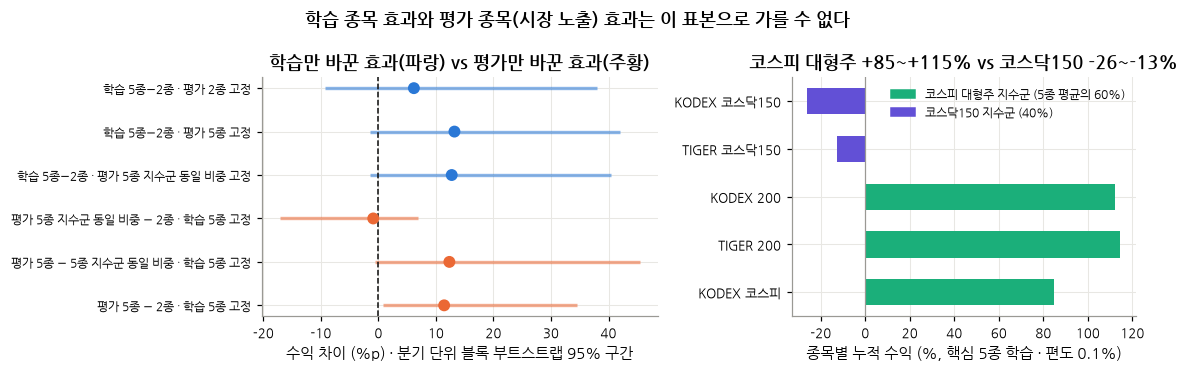

In [34]:
# 그림 A-1: 학습 종목 효과 vs 평가 종목(시장 노출) 효과
fig, axs = plt.subplots(1, 2, figsize=(10.6, 3.4), gridspec_kw=dict(width_ratios=[1.15, 1]))  # 두 칸
_sel = pd.concat([X6D[(X6D.비교 == "학습 변경") & (X6D.학습 == "5종 − 2종")], X6D[(X6D.비교 == "평가 변경") & (X6D.학습 == "5종")]])  # 비교 여섯 줄
_lab = [(f"학습 5종−2종 · 평가 {r.평가} 고정" if r.비교 == "학습 변경" else f"평가 {r.평가} · 학습 5종 고정").replace("5종 계열 균등", "5종 지수군 동일 비중") for r in _sel.itertuples()]  # 이름
ys = np.arange(len(_sel))  # 위치
_c = [BLUE if r.비교 == "학습 변경" else ORANGE for r in _sel.itertuples()]  # 색: 학습 변경 · 평가 변경
axs[0].hlines(ys, _sel.lo * 100, _sel.hi * 100, color=_c, lw=2.2, alpha=.55)  # 95% 구간
axs[0].scatter(_sel.d * 100, ys, color=_c, s=46, zorder=3)  # 점 추정
axs[0].axvline(0, color=INK, lw=1, ls="--")  # 0 선
axs[0].set_yticks(ys, _lab, fontsize=8)  # 눈금
axs[0].invert_yaxis()  # 위에서 아래로
axs[0].set_xlabel("수익 차이 (%p) · 분기 단위 블록 부트스트랩 95% 구간")  # 축 이름
axs[0].set_title("학습만 바꾼 효과(파랑) vs 평가만 바꾼 효과(주황)")  # 제목
_p5 = XP[XP.학습 == "5종"].set_index("종목")  # 학습 5종 · 종목별
_p5 = _p5.loc[_p5.계열.sort_values().index]  # 계열끼리 모음
_fc = [AQUA if f == "코스피대형주지수군" else VIOLET for f in _p5.계열]  # 계열 색
axs[1].barh(_p5.index, _p5.수익 * 100, color=_fc, height=.55)  # 종목별 수익
axs[1].axvline(0, color="#9a9994", lw=.8)  # 0 선
axs[1].invert_yaxis()  # 위에서 아래로
axs[1].set_xlabel("종목별 누적 수익 (%, 핵심 5종 학습 · 편도 0.1%)")  # 축 이름
_kp, _kq = _p5[_p5.계열 == "코스피대형주지수군"].수익, _p5[_p5.계열 == "코스닥150지수군"].수익  # 계열별
axs[1].set_title(f"코스피 대형주 {_kp.min() * 100:+.0f}~{_kp.max() * 100:+.0f}% vs 코스닥150 {_kq.min() * 100:+.0f}~{_kq.max() * 100:+.0f}%")  # 제목
_hh = [mpl.patches.Patch(color=AQUA), mpl.patches.Patch(color=VIOLET)]  # 범례 표식
axs[1].legend(_hh, ["코스피 대형주 지수군 (5종 평균의 60%)", "코스닥150 지수군 (40%)"], loc="upper right", fontsize=8)  # 범례
fig.suptitle("학습 종목 효과와 평가 종목(시장 노출) 효과는 이 표본으로 가를 수 없다", fontweight="bold", fontsize=11.5)  # 결론 제목
savefig(fig, "x6_decomp")  # 저장

#### 나. 결과

- 평가 종목군을 대표 2개로 고정하면 학습 5종 − 학습 2종의 수익 차이(+6.2%p [−9.3, +38.0])는 통계적으로 유의하지 않습니다
- 학습 효과(평가 5종 고정 시 +13.2%p)와 평가 구성 효과(학습 5종 고정 시 평가 5종 − 2종 +11.4%p)는 점추정으로 비슷하며, 이 표본으로는 둘을 가를 수 없습니다
- 학습이 없는 신고가 돌파 전략도 평가를 2개에서 5개로 바꾸면 +48.9% → +57.0%로 함께 오릅니다. 5종을 단순 평균하면 코스피 대형주 지수군이 60%를 차지하고, 이 기간 코스피 대형주가 코스닥150보다 크게 올랐기 때문입니다
- 평가 비중을 지수군 동일 비중으로 바꾸면 5종 평가의 우위는 사라짐(학습 5종 기준 −0.9%p)

#### 다. 판단

- 같은 시장을 추종하는 ETF를 학습에 더해도 새 정보는 거의 늘지 않습니다
- 평가 종목군은 같은 시장을 중복해 세지 않도록 지수군 동일 비중으로 묶습니다

## 붙임 2. 용어

| 용어 | 뜻 |
|---|---|
| 상승 구간 (상승 구간 라벨) | 10% 반전 기준 지그재그로 저점 · 고점을 사후 확정하고, 저점에서 고점까지 15% 이상 오른 구간. 그 안의 날은 1, 나머지는 0 |
| 거래 성공 라벨 | 다음 날 시가에 사서 20거래일 안에 '진입가 + ATR% 2배'에 먼저 닿으면 1, '− 2배'에 먼저 닿으면 0, 둘 다 아니면 기한 종가의 비용 차감 후 손익 부호 (삼중 장벽법) |
| 시가 체결 기준 | 종가로 판단하고 다음 날 시가에 실제로 사고판 가격과 수량으로 손익을 계산, 보유 중에는 매일 종가로 평가 |
| 종가 기준 계산 | 전날 보유 비중 × 오늘 종가 수익률. 매수일 시가→종가 수익을 빠뜨리고 매도 뒤 하루를 더 셈 |
| 20일 신고가 돌파 | 오늘 종가가 직전 20거래일 최고 종가를 넘는 것 |
| ATR | 평균 실제 변동폭(14일). 하루 가격 변동 폭의 척도 |
| 진입 · 해제 임계값 (0.6 / 0.4) | 모델 점수 0.6 이상이면 매수 허용, 0.4 이하로 내려가야 해제, 그 사이는 직전 상태 유지 |
| 고점 직전 매수 | 상승 구간 안에서 고점까지 3거래일 이내에 산 매수. 라벨상으로는 맞힌 신호이나 대부분 손실 |
| 고점 후 경과일 · 고점 대비 등락률 | 확정된 고점에서 며칠 지났는지, 고점 종가 대비 현재 종가가 몇 % 인지. 사후에만 계산 가능 |
| 휩소 | 매수 직후(여기서는 2거래일 이내) 다시 매도 신호가 나는 헛매매 |
| 기초지수군 동일 비중 | 같은 시장을 추종하는 ETF를 한 묶음으로 보고, 묶음마다 같은 금액을 배분 |
| 같은 변동성의 보유+현금 | 규칙과 일간 변동성이 같도록 보유와 현금을 섞은 포트폴리오. 타이밍의 실질 가치를 재는 비교 대상 |
| 조건 맞춤 무작위 매수 | 실제 매수와 같은 종목 · 연도 · 건수 · 미보유일 · 20일선 위아래 구성을 맞추고 날짜만 무작위로 1,000회 뽑은 비교 분포 |
| 분기 단위 블록 부트스트랩 | 일별 수익을 분기 단위로 묶어 복원 추출을 반복한 95% 신뢰구간. 수익의 자기상관을 보존 |
| 다중비교 보정 p값 | 여러 조합 중 최고를 고를 때 생기는 우연의 효과를 반영한 p값 |
| Holm 보정 | 여러 검정을 함께 할 때 우연히 하나쯤 유의하게 나오는 것을 막는 순차 보정 |
| AUC | 점수가 1 인 날을 0 인 날보다 높게 매길 확률. 0.5는 무작위, 1.0은 완전 구분 |
| 연 단위 전진 학습 | 매년 그 이전 자료만으로 모델을 다시 학습해 그해를 예측. 학습과 평가 사이 60거래일 공백 |
| 샤프 비율 | 연 수익 평균을 연 변동성으로 나눈 값 (무위험 수익률 0). 위험 1단위당 수익 |
| 최대낙폭 (MDD) | 누적 자산의 직전 최고점 대비 가장 큰 하락률 |

#### 참고 자료

- Fama, E. F. & Blume, M. E. (1966). Filter Rules and Stock-Market Trading. *Journal of Business*, 39(1).
- Donchian, R. D. (1960). High Finance in Copper. *Financial Analysts Journal*, 16(6). (채널 돌파 규칙)
- Wilder, J. W. (1978). *New Concepts in Technical Trading Systems*. (RSI · ATR)
- Faber, M. T. (2007). A Quantitative Approach to Tactical Asset Allocation. *Journal of Wealth Management*. (200일선 추세 추종)
- López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley. (삼중 장벽법 · 연 단위 전진 학습)
- Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2).
- Künsch, H. R. (1989). The Jackknife and the Bootstrap for General Stationary Observations. *Annals of Statistics*, 17(3). (블록 부트스트랩)
- White, H. (2000). A Reality Check for Data Snooping. *Econometrica*, 68(5). (여러 조합 중 최고를 고를 때의 보정)